# Co-location rather than causation: tourism, new construction and hazard exposure in the Sylhet tourism belt, Bangladesh
### Analysis notebook: complete, reproducible code for the article and its Supplementary Material

This notebook contains **all code** behind the article: the main analysis (**Part A**, Stages 0–8) and the additional analyses added during revision (**Part B**: label validation, time-matched OpenStreetMap, controlled attribution, the COVID-19 test, hazard exposure and robustness checks). The outputs printed under each cell are those of the authors' own runs, so the numbers in the paper can be traced to the cell that produced them.

**Study area:** four upazilas of the Sylhet tourism belt (Gowainghat, Companiganj, Jaintapur = North cluster; Sreemangal = South cluster), 1,455 km² on a 30 m grid (EPSG:32646).

**Research questions (as in the paper)**
| | Question | Main cells |
|---|---|---|
| RQ1 | Is new construction concentrated near attractions, and does this remain after controls? | Stage 2, Cell 2B |
| RQ2 | Do tourism predictors add out-of-sample predictive skill? | Stages 3–6, Cell 2B |
| RQ3 | Did construction near attractions respond differently to the COVID-19 closures? | Cell 2C |
| RQ4 | Is new construction near attractions more exposed to floods and landslides? | Cells 2D, 2D-v2, M2 |
| RQ5 | How much (hazard-zone) construction is projected to 2035? | Stages 7–8, Cells 2E, M3 |

**Temporal design (no information from the future is used for testing):**
* **Period A (training):** state in 2016 → new construction 2017–2020
* **Period B (independent test):** state in 2020 → new construction 2021–2023
* **Projection:** state in 2023 → Monte Carlo simulation 2024–2035

## Where each result of the paper comes from

| Notebook cell | Stage no. | What it produces | Paper |
|---|---|---|---|
| Stage 0 | – | Settings and helper functions (`sylhet_setup.py`) | – |
| Stage 1 | 1 | All layers on one 30 m grid | Section 4.1; Supplementary Table S1 |
| Stage 2 | 2 | Annual new construction, construction labels, feature tables | Sections 4.2, 5.1; Figure 3 |
| Stages 3–5 | 3–5 | Original five-model comparison (LR, CA–Markov, RF, XGBoost, ConvLSTM, null) | Supplementary Tables S6–S7 |
| Stage 6 | 6 | Original SHAP analysis; label-threshold robustness | Supplementary Table S9 |
| Stage 7 | 7 | Monte Carlo scenarios to 2035 | Section 5.6; Table 8; Figure 7; Figure S3 |
| Stage 8 | 8 | Ecological sensitivity index, planning zones, figures | Figure 8; Supplementary Tables S14–S16 |
| Cell 1A | 91 | Temporal stability of the Open Buildings labels | Section 5.1; Table S2; Figures S1–S2 |
| Cell 1B | 92 | Automatic screen of 1,200 points; manual-check sample | Table S3 |
| Cell 1M | – | Interactive manual check against dated imagery | (produces `manual_answers.csv`) |
| Cell 1C | 93 | Label precision and omission | Table 3 |
| Cell 2A | 94 | Time-matched roads and tourism facilities (OSM 2016/2020/2023) | Section 4.3; Table S5 |
| Cell 2B | 95 | RQ1 controlled odds ratios; RQ2 models, block bootstrap, ablation, SHAP; calibration | Tables 4–5; Figures 4–5; Table S8 |
| Cell 2C | 96 | RQ3 difference-in-differences and event study | Table 6; Figure 6 |
| Cell 2D | 97 | Hazard layers: HAND, June 2022 Sentinel-1 flood, slope | Section 4.7 |
| Cell 2D-v2 | 99 | RQ4 hazard odds ratios (2022 flood as main flood class) | Table 7; Table S10 |
| Cell 2E | 98 | RQ5 hazard-zone construction, avoided exposure, precision correction | Table 8 |
| Cell M2 | 101 | Flood-threshold sensitivity (−15 to −20 dB, Otsu, change detection) | Table S11 |
| Cell M3 | 102 | Projection with 2023 roads; p versus p² allocation | Table S13 |

*Note on labels inside the code:* comments such as "RO1–RO7" refer to the objectives of an earlier draft; the table above gives the mapping to the published research questions. In the code, "vulnerability" is the **exposure-weighted ecological sensitivity index** of the paper.

## How to run

**Requirements:** a Google account with Google Drive and Google Colab (High-RAM runtime recommended; Stage 4 needs a GPU), and a Google Earth Engine Cloud project for Cells 1B, 2D and M2. Python packages missing from Colab are installed automatically by Stage 0.

**Input data** (all open; see Supplementary Table S1). Place them anywhere in *My Drive*; the notebook searches the whole Drive by file name:
* Google Earth Engine exports on the 30 m grid: `Landsat_dry_<year>.tif`, `VIIRS_dry_<year>.tif`, `OB_built_2016_2023*.tif`, `OB_first_year*.tif`, `DEM_slope*.tif`, `JRC_water*.tif`, `Hansen_forest*.tif`, `CHIRPS_*.tif`, optional `S2_dry_2023*.tif`;
* WorldPop population: `pop_<year>_clip.tif`;
* vector layers (study area, upazilas, roads, rivers, tourism points, attractions, gateways, tourism zone, protected areas) as listed at the top of Stage 1.

The World Database on Protected Areas cannot be redistributed; download it from https://www.protectedplanet.net and clip it to the study area.

**Rules**
1. Run Part A in order (Stage 0 → 8), then Part B in the order shown. Every cell is **independent**: it loads what it needs from Drive, runs, saves its results and can be followed by a new session (`begin_stage` / `end_stage` in `sylhet_setup.py`). A cell stops with a clear message if an earlier one is missing.
2. Cells that use Earth Engine (1B, 2D, M2) need your own project ID: replace `'YOUR-GEE-PROJECT'`.
3. Results are written to `MyDrive/Sylhet_outputs` (tables as CSV, maps as GeoTIFF, figures as 300 dpi PNG) and the revision results to `MyDrive/Sylhet_outputs/revision`. Key numbers accumulate in `key_results.json`.
4. Random seeds are fixed (`SEED = 42` in Stage 0); package versions are written to `key_results.json` by Stage 8.

| Stage | Runtime type | Approx. time |
|---|---|---|
| 0 | CPU | 2 min |
| 1 | CPU (High-RAM) | 15–30 min |
| 2 | CPU (High-RAM) | 10–20 min |
| 3 | CPU (High-RAM) | 30–60 min |
| 4 | T4 GPU (High-RAM) | 20–60 min |
| 5 | CPU (High-RAM) | 10–20 min |
| 6 | CPU (High-RAM) | 20–40 min |
| 7 | CPU (High-RAM) | 60–150 min |
| 8 | CPU (High-RAM) | 10–20 min |
| Part B cells | CPU (High-RAM) | 1–15 min each; 1M is interactive; M3 about 45 min |

---
# Part A – Main analysis (Stages 0–8)

## Stage 0 – Settings and helper functions
Run **both** cells below once. They save `sylhet_setup.py` to `MyDrive/Sylhet_outputs`; every later cell loads it. All analysis settings (periods, thresholds, number of simulations, seed) are in the second cell.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
os.makedirs('/content/drive/MyDrive/Sylhet_outputs', exist_ok=True)
print('Drive ready')

Mounted at /content/drive
Drive ready


In [ ]:
%%writefile /content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py
# sylhet_setup.py – written by Stage 0 and loaded at the start of every stage.
# Edit parameters in the Stage 0 cell (not in this file on Drive), then run Stage 0 again.
import importlib.util, subprocess, sys
for _pkg, _mod in [('rasterio', 'rasterio'), ('geopandas', 'geopandas'), ('xgboost', 'xgboost'),
                   ('shap', 'shap'), ('pyogrio', 'pyogrio')]:
    if importlib.util.find_spec(_mod) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', _pkg], check=True)

# ============================ PARAMETERS ============================
# Everything you may want to change is here. Write the final values in your Methods section.

DRIVE = '/content/drive/MyDrive'
OUT   = DRIVE + '/Sylhet_outputs'
SEARCH = ['GEE_Data', 'Sylhet_Landsat', 'Sylhet_S2', 'Sylhet_static', 'Sylhet_VIIRS',
          'Sylhet_CHIRPS', 'Sylhet_buildings', 'Sylhet_QGIS', 'Sylhet_data']
SEARCH_WHOLE_DRIVE = True     # True: find input files anywhere in My Drive (no need to organise folders)

SEED = 42
LABEL_THRESHOLD = 0.30        # a 30 m pixel is "new construction" if >= 30 % of it became newly built
BUILT_START_MAX = 30          # pixels with >= 30 % building cover at the start are excluded (already built)
WATER_MAX = 50                # pixels with JRC water occurrence >= 50 % are excluded (permanent water)
FOCAL_PIX = 17                # 17 x 17 pixels at 30 m ~ 500 m neighbourhood
NEG_PER_POS = 5               # training sample: 5 non-change pixels per change pixel
TEST_SAMPLE = 400_000         # Period B evaluation sample (natural class proportions)
BOOTSTRAP = 200               # bootstrap resamples for confidence intervals and significance tests
SIG_SAMPLE = 100_000          # test pixels used in the paired bootstrap significance tests
CV_BLOCK_M = 3000             # spatial cross-validation block size (m)
TUNE = True                   # tune Random Forest / XGBoost hyper-parameters with spatial CV (Period A only)
LABEL_SENS = [0.2, 0.5]       # extra label thresholds for the label-sensitivity test (0.3 is the main value)
RESUME = True                 # reuse saved ConvLSTM model and scenario results if Colab disconnects and you re-run

# Period definitions
PERIOD_A = dict(start=2016, new_from=2017, new_to=2020, seq=[2014, 2015, 2016])
PERIOD_B = dict(start=2020, new_from=2021, new_to=2023, seq=[2018, 2019, 2020])
PROJ_START = 2023
PROJ_END = 2035

# Tourism-specific predictors (all others are 'general growth')
TOURISM_FEATURES = ['dist_attraction', 'dist_tourism_route', 'night_light']

# ConvLSTM
RUN_CONVLSTM = True           # set False if you have no GPU or little time
PATCH = 64
STRIDE_TRAIN = 32
EPOCHS = 30
BATCH = 16

# Monte Carlo scenarios: multipliers of the observed 2017-2023 construction rate.
# Justify these with your tourism statistics (Part 8 of data collection) and state them in the paper.
SCENARIOS = {'Low': 0.7, 'Medium': 1.0, 'High': 1.5}   # provisional; replaced by observed ratios if AUTO_SCENARIOS
AUTO_SCENARIOS = True         # Low/High = slowest/fastest 3-year mean of annual construction ÷ 2017–2023 mean
SENS_MULTS = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]   # quantity sensitivity analysis (Supplementary Material)
N_SIM = 100                   # simulations per scenario (final paper value)
UPDATE_EVERY = 4              # years between re-computing neighbourhood predictors in the simulation
ALLOC_SHARPNESS = 2.0         # allocation weight = probability ** ALLOC_SHARPNESS
N_ENSEMBLE = 5                # bootstrap XGBoost models used for model uncertainty

# Vulnerability (sensitivity components, equal weights by default)
SENS_WEIGHTS = {'forest': 1, 'vegetation': 1, 'water': 1, 'slope': 1, 'protected': 1, 'monsoon_rain': 1}
SENS_WEIGHT_DRAWS = 200       # Dirichlet draws for weight-uncertainty analysis

# Decision support: planning-watch hotspots = top WATCH_TOP_PCT % of the study area by High-scenario probability
WATCH_TOP_PCT = 2.0
# ===================================================================

import os, glob, json, time, warnings, platform
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.features import rasterize
from scipy import ndimage
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, brier_score_loss,
                             cohen_kappa_score, precision_score, recall_score, roc_curve, precision_recall_curve)
import xgboost as xgb
import shap, joblib
warnings.filterwarnings('ignore')

import random
random.seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(OUT, exist_ok=True)
FIG = OUT + '/figures'; os.makedirs(FIG, exist_ok=True)
CACHE = OUT + '/cache'; os.makedirs(CACHE, exist_ok=True)
RESULTS = {}          # key numbers collected for the paper (reloaded from Drive below)
T_START = time.time()
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 10, 'font.family': 'DejaVu Sans'})
print('Output folder:', OUT)

# Runtime check (Colab Pro: choose a GPU and High-RAM)
try:
    import psutil
    print(f'RAM: {psutil.virtual_memory().total / 1e9:.1f} GB | CPUs: {os.cpu_count()}')
    if psutil.virtual_memory().total < 20e9:
        print('WARNING: less than 20 GB RAM. Use Runtime > Change runtime type > High-RAM.')
except ImportError:
    pass
if os.system('nvidia-smi -L > /dev/null 2>&1') == 0:
    os.system('nvidia-smi -L')

import fnmatch
def build_index():
    # Index every file in My Drive once (including folder shortcuts from another account),
    # so files are found wherever they are and the Drive does not need to be re-organised.
    idx = {}
    roots = [os.path.join(DRIVE, f) for f in SEARCH if os.path.isdir(os.path.join(DRIVE, f))]
    if SEARCH_WHOLE_DRIVE:
        roots = [DRIVE]
    for root in roots:
        for d, subdirs, files in os.walk(root, followlinks=True):
            subdirs[:] = [s for s in subdirs if not s.startswith('.') and s not in ('Sylhet_outputs', 'Colab Notebooks')]
            for fn in files:
                idx.setdefault(fn, []).append(os.path.join(d, fn))
    # Unzip an uploaded Sylhet_QGIS*.zip automatically (Google Drive cannot unzip by itself)
    import zipfile
    for fn, paths in list(idx.items()):
        if fnmatch.fnmatch(fn, 'Sylhet_QGIS*.zip'):
            dest = '/content/Sylhet_QGIS_unzipped'
            with zipfile.ZipFile(paths[0]) as z:
                for member in z.namelist():
                    if member.endswith('/'):
                        continue
                    target = os.path.join(dest, os.path.basename(member))
                    os.makedirs(dest, exist_ok=True)
                    with z.open(member) as src, open(target, 'wb') as out:
                        out.write(src.read())
                    idx.setdefault(os.path.basename(member), []).insert(0, target)
            print('Unzipped', fn, '->', dest)
    return idx
FILE_INDEX = build_index()
print(f'Indexed {sum(len(v) for v in FILE_INDEX.values()):,} files in Drive')

def find_all(name):
    # All files matching a name pattern (handles split Earth Engine exports such as name-0000000000-0000000000.tif)
    if os.path.isfile(name):          # already a full path (e.g. from an earlier find_all call)
        return [name]
    hits = [p for fn, paths in FILE_INDEX.items() if fnmatch.fnmatch(fn, name) for p in paths]
    if not hits and '*' not in name and name.endswith('.tif'):
        stem = name[:-4]
        hits = [p for fn, paths in FILE_INDEX.items() if fnmatch.fnmatch(fn, stem + '-*.tif') for p in paths]
    if not hits and name.endswith('.gpkg'):
        # QGIS sometimes saves a layer as a shapefile called 'name.gpkg.shp' (or 'name.shp'); accept both
        for alt in (name + '.shp', name[:-5] + '.shp'):
            hits = [p for p in FILE_INDEX.get(alt, [])]
            if hits:
                break
    if not hits:
        raise FileNotFoundError(f'"{name}" not found anywhere in My Drive')
    # if the same file name exists twice (duplicate copies), keep one copy per name
    by_name = {}
    for p in sorted(hits):
        by_name.setdefault(os.path.basename(p), p)
    return sorted(by_name.values())

def find(name):
    return find_all(name)[0]

def exists(name):
    try:
        find_all(name); return True
    except FileNotFoundError:
        return False

def to_grid(pattern, band=1, method=Resampling.bilinear, scale=1.0, fill=np.nan):
    # Reproject one band of a raster (or of all its split parts) onto the common grid
    out = np.full((H, W), np.nan, dtype='float32')
    for path in find_all(pattern):
        part = np.full((H, W), np.nan, dtype='float32')
        with rasterio.open(path) as src:
            reproject(source=rasterio.band(src, band), destination=part,
                      src_transform=src.transform, src_crs=src.crs, src_nodata=src.nodata,
                      dst_transform=GRID['transform'], dst_crs=GRID['crs'],
                      dst_nodata=np.nan, resampling=method)
        out = np.where(np.isnan(out), part, out)
    out = out * scale
    if not np.isnan(fill):
        out = np.where(np.isnan(out), fill, out)
    return out.astype('float32')

def read_vec(name):
    g = gpd.read_file(find(name))
    g = g[g.geometry.notna() & ~g.geometry.is_empty]
    return g.to_crs(GRID['crs'])

def burn(gdf, values=None):
    vals = [1] * len(gdf) if values is None else list(values)
    return rasterize(zip(gdf.geometry, vals), out_shape=(H, W), transform=GRID['transform'],
                     fill=0, all_touched=True, dtype='int32')

def dist_to(mask):
    mask = np.asarray(mask) > 0
    if mask.sum() == 0:
        return np.full((H, W), np.nan, 'float32')
    return ndimage.distance_transform_edt(~mask, sampling=RES).astype('float32')

def norm01(a, mask=None, lo=2, hi=98):
    # Robust 0-1 scaling using the 2nd-98th percentile inside the mask
    m = np.isfinite(a) if mask is None else (mask & np.isfinite(a))
    p_lo, p_hi = np.percentile(a[m], [lo, hi])
    return np.clip((a - p_lo) / (p_hi - p_lo + 1e-12), 0, 1).astype('float32')

def save_tif(arr, name, dtype='float32', nodata=np.nan):
    prof = dict(driver='GTiff', height=H, width=W, count=1, dtype=dtype, crs=GRID['crs'],
                transform=GRID['transform'], nodata=nodata, compress='deflate')
    with rasterio.open(os.path.join(OUT, name), 'w', **prof) as dst:
        dst.write(arr.astype(dtype), 1)

def crop(a):
    return a[R0:R1, C0:C1]

def show_map(arr, title, fname, cmap='viridis', vmin=None, vmax=None, label='', mask_outside=True):
    a = arr.astype('float32').copy()
    if mask_outside:
        a[~study] = np.nan
    fig, ax = plt.subplots(figsize=(6.5, 9))
    im = ax.imshow(crop(a), cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title); ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.035, pad=0.02, label=label)
    plt.savefig(os.path.join(FIG, fname), bbox_inches='tight'); plt.show()

def fom_stats(pred, obs, elig):
    # Figure of Merit and related allocation statistics (Pontius et al.)
    p, o = pred & elig, obs & elig
    hits = int((p & o).sum()); misses = int((~p & o).sum()); fa = int((p & ~o).sum())
    return dict(hits=hits, misses=misses, false_alarms=fa,
                FoM=hits / max(hits + misses + fa, 1),
                producers_acc=hits / max(hits + misses, 1),
                users_acc=hits / max(hits + fa, 1))

def top_n(prob, elig, n):
    # Binary map of the n most probable eligible pixels (quantity-matched allocation)
    out = np.zeros(prob.shape, bool)
    r, c = np.where(elig & np.isfinite(prob))
    if n <= 0 or len(r) == 0:
        return out
    n = min(int(n), len(r))
    k = np.argpartition(-prob[r, c], n - 1)[:n]
    out[r[k], c[k]] = True
    return out

def boot_ci(y, p, fn, n=BOOTSTRAP):
    vals = []
    idx = np.arange(len(y))
    for _ in range(n):
        s = rng.choice(idx, len(idx), replace=True)
        if y[s].min() == y[s].max():
            continue
        vals.append(fn(y[s], p[s]))
    return np.percentile(vals, [2.5, 97.5])

# ---------------- Shared functions used by several stages ----------------
_dyn_cache = {}
def dynamic(year):
    if year in _dyn_cache:
        return _dyn_cache[year]
    ls = find(f'Landsat_dry_{year}.tif')
    d = {'ndvi': to_grid(ls, band=7), 'ndbi': to_grid(ls, band=8), 'mndwi': to_grid(ls, band=9),
         'night_light': to_grid(f'VIIRS_dry_{year}.tif', band=1)}
    pop = to_grid(f'pop_{max(year, 2015)}_clip.tif', method=Resampling.average, fill=0)
    d['population_log'] = np.log1p(np.clip(pop, 0, None)).astype('float32')
    _dyn_cache[year] = d
    return d

def make_xgb(seed=SEED, **kw):
    p = {**XGB_PARAMS, **kw}
    return xgb.XGBClassifier(subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw, tree_method='hist',
                             eval_metric='aucpr', n_jobs=-1, random_state=seed, **p)

def matrix(feats, idx):
    return np.column_stack([feats[k][idx] for k in FEATURES]).astype('float32')

def neighbourhood(built_pct):
    b = np.nan_to_num(built_pct, nan=0)
    return {'built_density_500m': ndimage.uniform_filter(b, size=FOCAL_PIX).astype('float32'),
            'dist_existing_built': dist_to(b >= BUILT_START_MAX)}

def new_fraction(y0, y1):
    # Share of each 30 m pixel whose 10 m sub-pixels first became built between y0 and y1
    out = np.zeros((H, W), 'float32')
    for path in find_all('OB_first_year*.tif'):
        with rasterio.open(path) as src:
            fy = src.read(1); tr, cr = src.transform, src.crs
        is_new = ((fy >= y0) & (fy <= y1)).astype('float32')
        part = np.full((H, W), np.nan, 'float32')
        reproject(source=is_new, destination=part, src_transform=tr, src_crs=cr,
                  dst_transform=GRID['transform'], dst_crs=GRID['crs'], dst_nodata=np.nan,
                  resampling=Resampling.average)
        out = np.where(np.isnan(part), out, np.maximum(out, part))
    return out

def predict_map(model, feats, er, ec, chunk=400_000):
    prob = np.full((H, W), np.nan, 'float32')
    for s in range(0, len(er), chunk):
        r, c = er[s:s + chunk], ec[s:s + chunk]
        prob[r, c] = model.predict_proba(imputer.transform(matrix(feats, (r, c))))[:, 1]
    return prob

# ---------------- Saving / loading results between stages ----------------
STATE = CACHE + '/state'; os.makedirs(STATE, exist_ok=True)
PRODUCER = {"C0": 1, "C1": 1, "DYN_NAMES": 1, "FEATURES": 1, "GENERAL_FEATURES": 1, "GRID": 1, "H": 1, "HAS_S2": 1, "NEIGH_NAMES": 1, "R0": 1, "R1": 1, "RES": 1, "UPZ_NAMES": 1, "W": 1, "built": 1, "cluster": 1, "gw": 1, "monsoon": 1, "name_col": 1, "rivers_mask": 1, "static": 1, "study": 1, "tree_now": 1, "upz": 1, "upz_id": 1, "zone": 1, "BLOCK": 2, "SCENARIOS": 2, "XA": 2, "XA_i": 2, "XB_i": 2, "eligA": 2, "eligB": 2, "featsA": 2, "featsB": 2, "gA": 2, "idxB": 2, "imputer": 2, "labA": 2, "labB": 2, "yA": 2, "yB": 2, "zone_gdf": 2, "XGB_PARAMS": 3, "eB_c": 3, "eB_r": 3, "models": 3, "prob_maps": 3, "spw": 3, "BEST": 5, "N_MARKOV": 5, "error_maps": 5, "nB_years": 5, "near_pa": 7, "px_km2": 7, "scen_out": 7}
RESULTS_FILE = OUT + '/key_results.json'

def _jsonable(o):
    if isinstance(o, dict): return {str(k): _jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_jsonable(v) for v in o]
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return o

if os.path.exists(RESULTS_FILE):
    with open(RESULTS_FILE) as _fh:
        RESULTS.update(json.load(_fh))

def _sig(o):
    if isinstance(o, dict): return ('dict', tuple((k, id(v)) for k, v in o.items()))
    if isinstance(o, list): return ('list', tuple(id(v) for v in o))
    return ('obj', id(o))

def begin_stage(k, needs):
    global rng, T_START, _LOADED_SIG
    T_START = time.time()
    rng = np.random.default_rng(SEED + 1000 * k)
    missing = [n for n in needs if not os.path.exists(f'{STATE}/{n}.joblib')]
    if missing:
        stages = sorted({PRODUCER[n] for n in missing})
        raise RuntimeError(f'Stage {k} needs results that are not saved yet: {missing}.\n'
                           f'Run Stage(s) {stages} first (stages must be run in order 1 → 8).')
    g = globals()
    for n in needs:
        g[n] = joblib.load(f'{STATE}/{n}.joblib')
    _LOADED_SIG = {n: _sig(g[n]) for n in needs}
    print(f'Stage {k}: loaded {len(needs)} saved results from earlier stages.')

def end_stage(k, exports):
    g = globals(); saved = []
    for n in exports:
        if n not in g:
            continue
        if n in _LOADED_SIG and _sig(g[n]) == _LOADED_SIG[n]:
            continue          # loaded from an earlier stage and unchanged
        joblib.dump(g[n], f'{STATE}/{n}.joblib', compress=1); saved.append(n)
    with open(RESULTS_FILE, 'w') as fh:
        json.dump(_jsonable(RESULTS), fh, indent=2)
    with open(f'{STATE}/stage_{k}_done.txt', 'w') as fh:
        fh.write(time.strftime('%Y-%m-%d %H:%M'))
    print(f'\n✅ Stage {k} finished in {(time.time() - T_START) / 60:.1f} min. Saved: {saved}')
    print('   Results are on Google Drive. You can now disconnect; the next stage can run in a new session.')


Overwriting /content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py


In [ ]:
# Check that the setup file works (installs missing packages the first time)
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())
print('\n✅ Stage 0 done. Continue with Stage 1 (now or in a later session).')

Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 56.9 GB | CPUs: 12
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 361 files in Drive

✅ Stage 0 done. Continue with Stage 1 (now or in a later session).


## Stage 1 – RO1 – Data integration on one 30 m grid
**Runtime type:** CPU (High-RAM) · **Approx. time:** 15–30 min

**In the paper:** Section 4.1 and Supplementary Table S1 (data sources and pre-processing).

In [ ]:
# ================= STAGE 1: RO1 – Data integration on one 30 m grid =================
from google.colab import drive
drive.mount('/content/drive')
import os
assert os.path.exists('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py'), 'Run Stage 0 first: it saves the settings file to Google Drive.'
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())          # settings + helper functions (from Stage 0)
begin_stage(1, needs=[])

REQUIRED = ['sylhet_belt_bbs.gpkg', 'study_area_4upazila_utm.gpkg', 'main_roads_20km.gpkg',
            'roads_20km_utm.gpkg', 'tourism_access_roads.gpkg', 'rivers_osm.gpkg', 'tourism_osm.gpkg',
            'attractions.shp', 'gateways.shp', 'protected_areas_utm.gpkg', 'tourism_zone.gpkg',
            'DEM_slope*.tif', 'JRC_water*.tif', 'Hansen_forest*.tif',
            'OB_built_2016_2023*.tif', 'OB_first_year*.tif', 'CHIRPS_*.tif']
REQUIRED += [f'Landsat_dry_{y}.tif' for y in sorted(set(PERIOD_A['seq'] + PERIOD_B['seq'] + [PROJ_START]))]
REQUIRED += [f'VIIRS_dry_{y}.tif'  for y in sorted(set(PERIOD_A['seq'] + PERIOD_B['seq'] + [PROJ_START]))]
REQUIRED += [f'pop_{y}_clip.tif' for y in sorted(set([max(y, 2015) for y in PERIOD_A['seq'] + PERIOD_B['seq']] + [PROJ_START]))]
missing = [n for n in REQUIRED if not exists(n)]
for n in REQUIRED:
    if n in missing:
        print(f'MISSING  {n}')
    else:
        hits = find_all(n)
        print(f'ok       {n:38s} {len(hits)} file(s) in  {os.path.relpath(os.path.dirname(hits[0]), DRIVE)}')
if missing:
    print('\nUpload the missing files to any folder in My Drive (for example a folder called Sylhet_QGIS),'
          '\nthen run this notebook again from the top. Shapefiles (.shp) need their .shx, .dbf and .prj files too.')
assert not missing, f'Missing files: {missing}'
HAS_S2 = exists('S2_dry_2023*.tif')
print('\nSentinel-2 2023 available for vegetation condition:', HAS_S2)

with rasterio.open(find(f'Landsat_dry_{PROJ_START}.tif')) as ref:
    GRID = dict(crs=ref.crs, transform=ref.transform)
    H, W = ref.height, ref.width
RES = GRID['transform'].a
print(f'Grid: {W} x {H} pixels, {RES} m, {GRID["crs"]}')

study = burn(read_vec('sylhet_belt_bbs.gpkg')) > 0
rr, cc = np.where(study)
R0, R1, C0, C1 = rr.min(), rr.max() + 1, cc.min(), cc.max() + 1
RESULTS['study_area_km2'] = float(study.sum() * RES * RES / 1e6)
print('Study area on grid:', round(RESULTS['study_area_km2'], 1), 'km²')

# Upazilas and clusters
upz = read_vec('study_area_4upazila_utm.gpkg').reset_index(drop=True)
def name_column(gdf, hint):
    # The text column whose values contain a known name (works for HDX 'ADM3_EN', 'adm3_name', 'name', ...)
    for col in gdf.columns:
        if col != 'geometry' and gdf[col].dtype == object and gdf[col].astype(str).str.contains(hint, case=False).any():
            return col
    raise KeyError(f'No column containing "{hint}" in {list(gdf.columns)}')
name_col = name_column(upz, 'mangal')
assert len(upz) == 4, f'Expected 4 upazilas, found {len(upz)}'
UPZ_NAMES = {i + 1: str(n) for i, n in enumerate(upz[name_col])}
upz_id = burn(upz, values=range(1, len(upz) + 1)) * study
south_ids = [i for i, n in UPZ_NAMES.items() if 'mangal' in n.lower()]
cluster = np.where(np.isin(upz_id, south_ids), 2, np.where(upz_id > 0, 1, 0))   # 1 North, 2 South
print('Upazilas:', UPZ_NAMES, '| South =', [UPZ_NAMES[i] for i in south_ids])

zone = (burn(read_vec('tourism_zone.gpkg')) > 0) & study
print('Tourism zone share of study area:', round(100 * zone.sum() / study.sum(), 2), '%')

# ---------- Static predictors ----------
static = {}
static['elevation'] = to_grid('DEM_slope*.tif', band=1)
static['slope']     = to_grid('DEM_slope*.tif', band=2)
static['water_occurrence'] = to_grid('JRC_water*.tif', fill=0)
static['treecover2000']    = to_grid('Hansen_forest*.tif', band=1, fill=0)

static['dist_main_road']   = dist_to(burn(read_vec('main_roads_20km.gpkg')))
static['dist_any_road']    = dist_to(burn(read_vec('roads_20km_utm.gpkg')))
gw = read_vec('gateways.shp')
gw_col = name_column(gw, 'mangal')
static['dist_sylhet_city'] = dist_to(burn(gw[gw[gw_col].str.contains('Sylhet', case=False)]))
static['dist_sreemangal']  = dist_to(burn(gw[gw[gw_col].str.contains('mangal', case=False)]))
rivers_mask = burn(read_vec('rivers_osm.gpkg'))
static['dist_river']       = dist_to(rivers_mask)
protected_mask = burn(read_vec('protected_areas_utm.gpkg'))
static['dist_protected']   = dist_to(protected_mask)
static['dist_attraction']    = dist_to(burn(read_vec('attractions.shp')))
static['dist_tourism_route'] = dist_to(burn(read_vec('tourism_access_roads.gpkg')))

# Layers used only for vulnerability / validation
lossyear = to_grid('Hansen_forest*.tif', band=2, method=Resampling.nearest, fill=0)
tree_now = np.where(lossyear > 0, 0, static['treecover2000']).astype('float32')
chirps_files = find_all('CHIRPS_*.tif')
monsoon = np.nanmean(np.stack([to_grid(f, band=2) for f in chirps_files]), axis=0).astype('float32')
osm_tour = read_vec('tourism_osm.gpkg')

for k, v in static.items():
    print(f'{k:20s} {np.nanmin(v[study]):10.1f} – {np.nanmax(v[study]):10.1f}')

# ---------- Built-up (Google Open Buildings Temporal) ----------
OB_YEARS = list(range(2016, 2024))
built = {y: to_grid('OB_built_2016_2023*.tif', band=i + 1, method=Resampling.average, fill=0)
         for i, y in enumerate(OB_YEARS)}

def new_fraction(y0, y1):
    # Share of each 30 m pixel whose 10 m sub-pixels first became built between y0 and y1
    out = np.zeros((H, W), 'float32')
    for path in find_all('OB_first_year*.tif'):
        with rasterio.open(path) as src:
            fy = src.read(1); tr, cr = src.transform, src.crs
        is_new = ((fy >= y0) & (fy <= y1)).astype('float32')
        part = np.full((H, W), np.nan, 'float32')
        reproject(source=is_new, destination=part, src_transform=tr, src_crs=cr,
                  dst_transform=GRID['transform'], dst_crs=GRID['crs'], dst_nodata=np.nan,
                  resampling=Resampling.average)
        out = np.where(np.isnan(part), out, np.maximum(out, part))
    return out

# ---------- Dynamic predictors for any year ----------
_dyn_cache = {}
def dynamic(year):
    if year in _dyn_cache:
        return _dyn_cache[year]
    ls = find(f'Landsat_dry_{year}.tif')
    d = {'ndvi': to_grid(ls, band=7), 'ndbi': to_grid(ls, band=8), 'mndwi': to_grid(ls, band=9),
         'night_light': to_grid(f'VIIRS_dry_{year}.tif', band=1)}
    pop = to_grid(f'pop_{max(year, 2015)}_clip.tif', method=Resampling.average, fill=0)
    d['population_log'] = np.log1p(np.clip(pop, 0, None)).astype('float32')
    _dyn_cache[year] = d
    return d

def neighbourhood(built_pct):
    b = np.nan_to_num(built_pct, nan=0)
    return {'built_density_500m': ndimage.uniform_filter(b, size=FOCAL_PIX).astype('float32'),
            'dist_existing_built': dist_to(b >= BUILT_START_MAX)}

DYN_NAMES = ['ndvi', 'ndbi', 'mndwi', 'night_light', 'population_log']
NEIGH_NAMES = ['built_density_500m', 'dist_existing_built']
FEATURES = list(static.keys()) + DYN_NAMES + NEIGH_NAMES
GENERAL_FEATURES = [f for f in FEATURES if f not in TOURISM_FEATURES]
print(len(FEATURES), 'predictors:', FEATURES)

end_stage(1, exports=['C0', 'C1', 'DYN_NAMES', 'FEATURES', 'GENERAL_FEATURES', 'GRID', 'H', 'HAS_S2', 'NEIGH_NAMES', 'R0', 'R1', 'RES', 'UPZ_NAMES', 'W', 'built', 'cluster', 'gw', 'monsoon', 'name_col', 'rivers_mask', 'static', 'study', 'tree_now', 'upz', 'upz_id', 'zone'])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 54.8 GB | CPUs: 8
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 357 files in Drive
Stage 1: loaded 0 saved results from earlier stages.
ok       sylhet_belt_bbs.gpkg                   1 file(s) in  ../../Sylhet_QGIS_unzipped
ok       study_area_4upazila_utm.gpkg           1 file(s) in  ../../Sylhet_QGIS_unzipped
ok       main_roads_20km.gpkg                   1 file(s) in  ../../Sylhet_QGIS_unzipped
ok       roads_20km_utm.gpkg                    1 file(s) in  ../../Sylhet_QGIS_unzipped
ok       tourism_access_roads.gpkg              1 file(s) in  ../../Sylhet_QGIS_unzipped
ok       rivers_osm.gpkg                        1 file(s) in  ../../Sylhet_QGIS_unzipped
ok       tourism_osm.gpkg                       1 file(s) in  ../../Sylhet_QGIS_unzipped
ok       attractions.shp          

## Stage 2 – RO2 – Indicators, observed change 2016–2023, labels and feature tables
**Runtime type:** CPU (High-RAM) · **Approx. time:** 10–20 min

**In the paper:** Section 4.2 (labels), Section 5.1 and Figure 3 (annual new building cover, tourism-zone share).

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 54.8 GB | CPUs: 8
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 357 files in Drive
Stage 2: loaded 10 saved results from earlier stages.
                   MNDWI                    NDBI                    NDVI                 built_cover_pct                 night_light                 population_log        
year                2016    2023  change    2016    2023  change    2016    2023  change            2016    2023  change        2016    2023  change           2016    2023
group                                                                                                                                                                      
North cluster    -0.3212 -0.3218 -0.0006 -0.1497 -0.1341  0.0156  0.4658  0.4470 -0.0188          0.5292  0.8175  0.2883      0.2609  0.5083

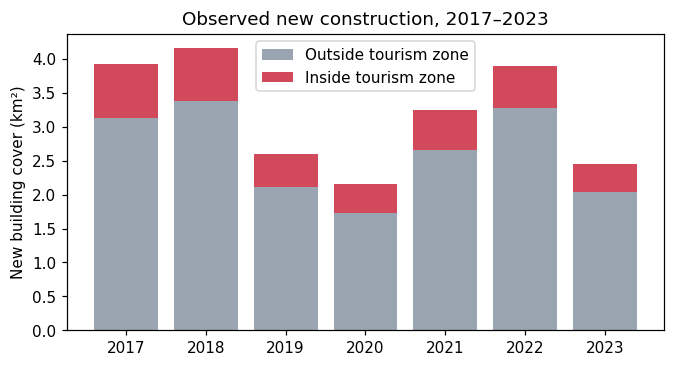

Period A (2017-2020): eligible 1,564,159 px | new construction 10,620 px (0.679 %) | 9.56 km² | 2,655 px/yr
Period B (2021-2023): eligible 1,561,535 px | new construction 4,909 px (0.314 %) | 4.42 km² | 1,636 px/yr
Training: (63720, 19) positives 10620 | Test: (400000, 19) positives 1231
VIF:
 mndwi                  32.78
ndvi                   24.15
ndbi                   23.70
dist_sreemangal        16.86
dist_sylhet_city       13.14
dist_tourism_route      4.69
dist_protected          4.29
elevation               3.83
dist_attraction         3.18
water_occurrence        2.67
dist_any_road           2.22
population_log          2.14
dist_river              2.11
built_density_500m      1.96
treecover2000           1.94
slope                   1.92
dist_existing_built     1.85
dist_main_road          1.84
night_light             1.40

Pairs with |Spearman rho| >= 0.7: [('elevation', 'water_occurrence', -0.74), ('dist_sreemangal', 'dist_protected', 0.72), ('population_log', 'built_densi

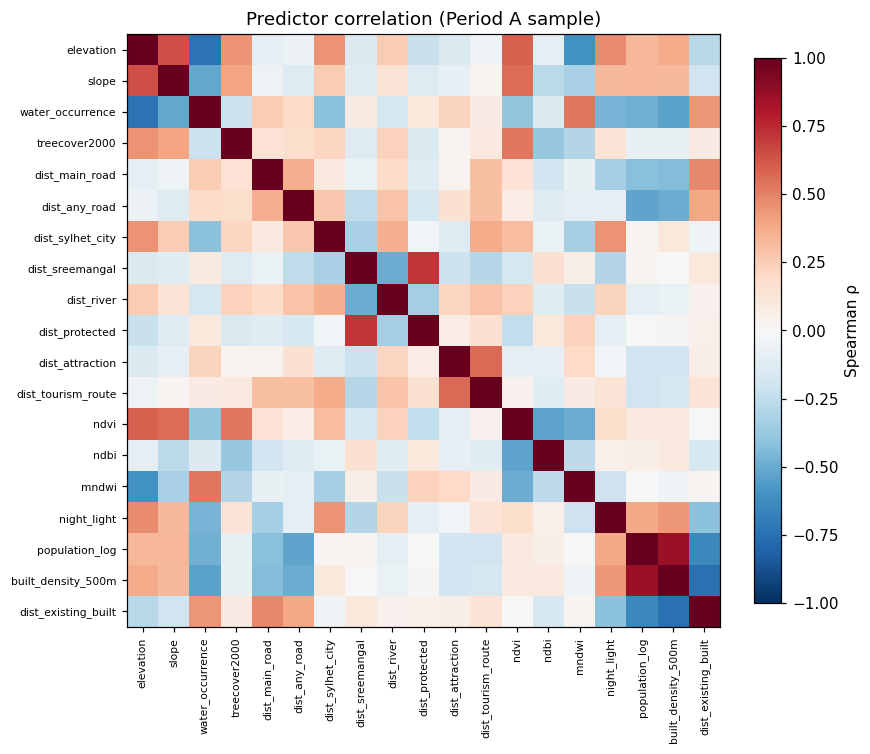


✅ Stage 2 finished in 1.4 min. Saved: ['BLOCK', 'SCENARIOS', 'XA', 'XA_i', 'XB_i', 'eligA', 'eligB', 'featsA', 'featsB', 'gA', 'idxB', 'imputer', 'labA', 'labB', 'yA', 'yB', 'zone_gdf']
   Results are on Google Drive. You can now disconnect; the next stage can run in a new session.


In [ ]:
# ================= STAGE 2: RO2 – Indicators, observed change 2016–2023, labels and feature tables =================
from google.colab import drive
drive.mount('/content/drive')
import os
assert os.path.exists('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py'), 'Run Stage 0 first: it saves the settings file to Google Drive.'
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())          # settings + helper functions (from Stage 0)
begin_stage(2, needs=['FEATURES', 'GRID', 'H', 'RES', 'W', 'built', 'cluster', 'static', 'study', 'zone'])

groups = {'Tourism zone': zone, 'Outside zone': study & ~zone,
          'North cluster': cluster == 1, 'South cluster': cluster == 2, 'Whole study area': study}
rows = []
for y in [2016, PROJ_START]:
    d = dynamic(y)
    for gname, gmask in groups.items():
        rows.append(dict(year=y, group=gname,
                         NDVI=np.nanmean(d['ndvi'][gmask]), NDBI=np.nanmean(d['ndbi'][gmask]),
                         MNDWI=np.nanmean(d['mndwi'][gmask]), night_light=np.nanmean(d['night_light'][gmask]),
                         population_log=np.nanmean(d['population_log'][gmask]),
                         built_cover_pct=np.nanmean(built[y][gmask])))
ind = pd.DataFrame(rows)
wide = ind.pivot(index='group', columns='year')
for v in ['NDVI', 'NDBI', 'MNDWI', 'night_light', 'built_cover_pct']:
    wide[(v, 'change')] = wide[(v, PROJ_START)] - wide[(v, 2016)]
wide = wide.sort_index(axis=1).round(4)
print(wide.to_string())
wide.to_csv(OUT + '/RO2_indicators_2016_2023.csv')

# Annual new construction (km²) from the 10 m first-year layer, inside the study area and the tourism zone
ann = {y: [0.0, 0.0] for y in range(2017, 2024)}
zone_gdf = read_vec('tourism_zone.gpkg'); study_gdf = read_vec('sylhet_belt_bbs.gpkg')
for path in find_all('OB_first_year*.tif'):
    with rasterio.open(path) as src:
        fy = src.read(1); tr = src.transform; px_area = abs(tr.a * tr.e)
        sm = rasterize(((g, 1) for g in study_gdf.to_crs(src.crs).geometry), out_shape=fy.shape, transform=tr, fill=0)
        zm = rasterize(((g, 1) for g in zone_gdf.to_crs(src.crs).geometry), out_shape=fy.shape, transform=tr, fill=0)
    for y in ann:
        hit = (fy == y)
        ann[y][0] += hit[sm == 1].sum() * px_area / 1e6
        ann[y][1] += hit[(sm == 1) & (zm == 1)].sum() * px_area / 1e6
annual = pd.DataFrame([dict(year=y, new_km2_study=a, new_km2_zone=z) for y, (a, z) in ann.items()])
annual['zone_share_%'] = 100 * annual.new_km2_zone / annual.new_km2_study
print(annual.round(3).to_string(index=False))
annual.to_csv(OUT + '/RO2_annual_new_construction.csv', index=False)
RESULTS['annual_new_km2_mean'] = float(annual.new_km2_study.mean())
RESULTS['annual_new_km2_cv'] = float(annual.new_km2_study.std() / annual.new_km2_study.mean())
RESULTS['zone_share_of_new_2017_2023_%'] = float(100 * annual.new_km2_zone.sum() / annual.new_km2_study.sum())

# Empirically bounded scenario multipliers (Methods 4.9, "Scenario rationale")
_mean = annual.new_km2_study.mean()
_roll = annual.set_index('year').new_km2_study.rolling(3).mean().dropna()   # index = last year of window
if AUTO_SCENARIOS and _mean > 0 and len(_roll) > 0:
    SCENARIOS = {'Low': round(float(_roll.min() / _mean), 2), 'Medium': 1.0,
                 'High': round(float(_roll.max() / _mean), 2)}
    RESULTS['scenario_windows'] = dict(slowest=f'{int(_roll.idxmin()) - 2}–{int(_roll.idxmin())}',
                                       fastest=f'{int(_roll.idxmax()) - 2}–{int(_roll.idxmax())}')
RESULTS['scenario_multipliers'] = SCENARIOS
print('Scenario multipliers:', SCENARIOS, RESULTS.get('scenario_windows', '(provisional values)'))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(annual.year, annual.new_km2_study - annual.new_km2_zone, label='Outside tourism zone', color='#9aa5b1')
ax.bar(annual.year, annual.new_km2_zone, bottom=annual.new_km2_study - annual.new_km2_zone,
       label='Inside tourism zone', color='#d1495b')
ax.set_ylabel('New building cover (km²)'); ax.set_title('Observed new construction, 2017–2023'); ax.legend()
plt.savefig(FIG + '/fig_annual_new_construction.png', bbox_inches='tight'); plt.show()

def build_period(P):
    feats = dict(static)
    feats.update(dynamic(P['start']))
    feats.update(neighbourhood(built[P['start']]))
    elig = study & (built[P['start']] < BUILT_START_MAX) & (static['water_occurrence'] < WATER_MAX)
    lab = (new_fraction(P['new_from'], P['new_to']) >= LABEL_THRESHOLD) & elig
    return feats, elig, lab

featsA, eligA, labA = build_period(PERIOD_A)
featsB, eligB, labB = build_period(PERIOD_B)
for nm, el, lb, P in [('A', eligA, labA, PERIOD_A), ('B', eligB, labB, PERIOD_B)]:
    n_years = P['new_to'] - P['new_from'] + 1
    print(f"Period {nm} ({P['new_from']}-{P['new_to']}): eligible {el.sum():,} px | "
          f"new construction {lb.sum():,} px ({100*lb.sum()/el.sum():.3f} %) | "
          f"{lb.sum()*RES*RES/1e6:.2f} km² | {lb.sum()/n_years:,.0f} px/yr")
RESULTS['labels'] = {'A_pos': int(labA.sum()), 'A_elig': int(eligA.sum()),
                     'B_pos': int(labB.sum()), 'B_elig': int(eligB.sum())}

rows_i, cols_i = np.indices((H, W))
BLOCK = int(CV_BLOCK_M / RES)
block_id = (rows_i // BLOCK) * 100000 + (cols_i // BLOCK)

def matrix(feats, idx):
    return np.column_stack([feats[k][idx] for k in FEATURES]).astype('float32')

# Training sample (Period A): all change pixels + NEG_PER_POS x random non-change pixels
pos = np.where(labA)
neg = np.where(eligA & ~labA)
pick = rng.choice(len(neg[0]), min(len(neg[0]), NEG_PER_POS * len(pos[0])), replace=False)
idxA = (np.r_[pos[0], neg[0][pick]], np.r_[pos[1], neg[1][pick]])
XA, yA, gA = matrix(featsA, idxA), labA[idxA].astype(int), block_id[idxA]

# Test sample (Period B): natural proportions
allB = np.where(eligB)
pickB = rng.choice(len(allB[0]), min(TEST_SAMPLE, len(allB[0])), replace=False)
idxB = (allB[0][pickB], allB[1][pickB])
XB, yB = matrix(featsB, idxB), labB[idxB].astype(int)

imputer = SimpleImputer(strategy='median').fit(XA)
XA_i, XB_i = imputer.transform(XA), imputer.transform(XB)
print('Training:', XA.shape, 'positives', yA.sum(), '| Test:', XB.shape, 'positives', yB.sum())
pd.DataFrame(XA, columns=FEATURES).assign(label=yA, block=gA).to_csv(OUT + '/train_periodA.csv', index=False)

# ---- 5.1 Collinearity check (Supplementary Table): Spearman correlations and variance inflation factors ----
dfA = pd.DataFrame(XA_i, columns=FEATURES)
varying = [f for f in FEATURES if dfA[f].std() > 0]          # constant columns have no correlation / VIF
corr = dfA.corr(method='spearman').fillna(0.0)
corr.round(3).to_csv(OUT + '/S1_predictor_spearman_correlation.csv')
Z = StandardScaler().fit_transform(dfA[varying])
vif = pd.Series(np.nan, index=FEATURES, name='VIF')
vif[varying] = np.diag(np.linalg.pinv(np.corrcoef(Z, rowvar=False)))
vif.round(2).to_csv(OUT + '/S1_predictor_VIF.csv')
high_pairs = [(a, b, round(float(corr.loc[a, b]), 2)) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:]
              if abs(corr.loc[a, b]) >= 0.7]
if len(varying) < len(FEATURES):
    print('Constant in the training sample (no VIF):', [f for f in FEATURES if f not in varying])
print('VIF:\n', vif.sort_values(ascending=False).round(2).to_string())
print('\nPairs with |Spearman rho| >= 0.7:', high_pairs if high_pairs else 'none')
RESULTS['collinearity'] = dict(max_VIF=float(vif.max()), max_VIF_feature=str(vif.idxmax()), high_pairs=high_pairs)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels(FEATURES, rotation=90, fontsize=7)
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(FEATURES, fontsize=7)
plt.colorbar(im, ax=ax, fraction=0.04, label='Spearman ρ'); ax.set_title('Predictor correlation (Period A sample)')
plt.savefig(FIG + '/figS1_predictor_correlation.png', bbox_inches='tight'); plt.show()

end_stage(2, exports=['BLOCK', 'FEATURES', 'GRID', 'H', 'RES', 'SCENARIOS', 'W', 'XA', 'XA_i', 'XB_i', 'built', 'cluster', 'eligA', 'eligB', 'featsA', 'featsB', 'gA', 'idxB', 'imputer', 'labA', 'labB', 'static', 'study', 'yA', 'yB', 'zone', 'zone_gdf'])


## Stage 3 – RO3 – Tuning and fitting Logistic Regression, Random Forest, XGBoost, CA–Markov and the null model
**Runtime type:** CPU (High-RAM) · **Approx. time:** 30–60 min

**In the paper:** Supplementary Tables S6–S7 (original model comparison and model settings). These models used the 2026 road network; the corrected models with time-matched roads are in Cell 2B.

In [ ]:
# ================= STAGE 3: RO3 – Tuning and fitting Logistic Regression, Random Forest, XGBoost, CA–Markov and the null model =================
from google.colab import drive
drive.mount('/content/drive')
import os
assert os.path.exists('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py'), 'Run Stage 0 first: it saves the settings file to Google Drive.'
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())          # settings + helper functions (from Stage 0)
begin_stage(3, needs=['FEATURES', 'H', 'RES', 'W', 'XA_i', 'eligB', 'featsB', 'gA', 'imputer', 'study', 'yA'])

spw = (yA == 0).sum() / max((yA == 1).sum(), 1)
RF_PARAMS = dict(n_estimators=500, min_samples_leaf=5, max_features='sqrt')
XGB_PARAMS = dict(n_estimators=700, max_depth=6, learning_rate=0.05, min_child_weight=5)
def make_lr():  return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced'))
def make_rf(**kw):
    p = {**RF_PARAMS, **kw}
    return RandomForestClassifier(class_weight='balanced_subsample', n_jobs=-1, random_state=SEED, **p)
def make_xgb(seed=SEED, **kw):
    p = {**XGB_PARAMS, **kw}
    return xgb.XGBClassifier(subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw, tree_method='hist',
                             eval_metric='aucpr', n_jobs=-1, random_state=seed, **p)

N_FOLDS = int(min(5, len(np.unique(gA))))
FOLDS = list(GroupKFold(n_splits=N_FOLDS).split(XA_i, yA, gA))

# ---- 6.0 Hyper-parameter tuning with spatial CV (Period A only, so Period B stays independent) ----
if TUNE:
    def cv_prauc(maker, **kw):
        return np.mean([average_precision_score(yA[va], maker(**kw).fit(XA_i[tr], yA[tr]).predict_proba(XA_i[va])[:, 1])
                        for tr, va in FOLDS])
    grids = {'RandomForest': (make_rf, [dict(min_samples_leaf=l, max_features=f) for l in [2, 5, 10] for f in ['sqrt', 0.5]]),
             'XGBoost': (make_xgb, [dict(max_depth=d, learning_rate=lr, n_estimators=int(35 / lr))
                                    for d in [4, 6, 8] for lr in [0.05, 0.1]])}
    tune_rows = []
    for name, (maker, grid) in grids.items():
        for g in grid:
            tune_rows.append(dict(model=name, params=json.dumps(g), cv_pr_auc=cv_prauc(maker, **g)))
            print(name, g, round(tune_rows[-1]['cv_pr_auc'], 4))
    tune = pd.DataFrame(tune_rows)
    tune.to_csv(OUT + '/RO3_hyperparameter_tuning.csv', index=False)
    best_p = {n: json.loads(tune[tune.model == n].sort_values('cv_pr_auc').iloc[-1]['params']) for n in grids}
    RF_PARAMS.update(best_p['RandomForest']); XGB_PARAMS.update(best_p['XGBoost'])
    RESULTS['tuned_params'] = dict(RandomForest=RF_PARAMS, XGBoost=XGB_PARAMS)
    print('Selected:', RESULTS['tuned_params'])

MAKERS = {'LogReg': make_lr, 'RandomForest': make_rf, 'XGBoost': make_xgb}

# ---- 6.1 Spatial cross-validation on Period A ----
cv_rows = []
for fold, (tr, va) in enumerate(FOLDS, 1):
    for name, mk in MAKERS.items():
        p = mk().fit(XA_i[tr], yA[tr]).predict_proba(XA_i[va])[:, 1]
        cv_rows.append(dict(model=name, fold=fold, roc_auc=roc_auc_score(yA[va], p),
                            pr_auc=average_precision_score(yA[va], p)))
cv = pd.DataFrame(cv_rows)
cv_sum = cv.groupby('model')[['roc_auc', 'pr_auc']].agg(['mean', 'std']).round(4)
print('Spatial 5-fold CV (3 km blocks), Period A:\n', cv_sum)
cv.to_csv(OUT + '/RO3_spatial_cv_periodA.csv', index=False)

# ---- 6.2 Fit on all of Period A ----
models = {name: mk().fit(XA_i, yA) for name, mk in MAKERS.items()}
for name, m in models.items():
    joblib.dump(m, OUT + f'/model_{name}_periodA.joblib')

# ---- 6.3 Full-map probabilities for Period B ----
eB_r, eB_c = np.where(eligB)
def predict_map(model, feats, er, ec, chunk=400_000):
    prob = np.full((H, W), np.nan, 'float32')
    for s in range(0, len(er), chunk):
        r, c = er[s:s + chunk], ec[s:s + chunk]
        prob[r, c] = model.predict_proba(imputer.transform(matrix(feats, (r, c))))[:, 1]
    return prob

prob_maps = {name: predict_map(m, featsB, eB_r, eB_c) for name, m in models.items()}

# CA-Markov baseline: logistic suitability x neighbourhood effect (Markov quantity is applied in 6.5)
neigh_B = norm01(featsB['built_density_500m'], study)
prob_maps['CA-Markov'] = (prob_maps['LogReg'] * (0.5 + 0.5 * neigh_B)).astype('float32')

# Null model (Pontius et al.): new construction is most likely next to existing buildings.
# Any useful model must beat this simple distance rule.
prob_maps['Null (distance)'] = np.where(eligB, 1.0 / (1.0 + featsB['dist_existing_built'] / RES), np.nan).astype('float32')
print('Probability maps ready:', list(prob_maps))

end_stage(3, exports=['FEATURES', 'H', 'RES', 'W', 'XA_i', 'XGB_PARAMS', 'eB_c', 'eB_r', 'eligB', 'featsB', 'imputer', 'models', 'prob_maps', 'spw', 'study', 'yA'])


Mounted at /content/drive
Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 56.9 GB | CPUs: 12
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 357 files in Drive
Stage 3: loaded 11 saved results from earlier stages.
RandomForest {'min_samples_leaf': 2, 'max_features': 'sqrt'} 0.7344
RandomForest {'min_samples_leaf': 2, 'max_features': 0.5} 0.7334
RandomForest {'min_samples_leaf': 5, 'max_features': 'sqrt'} 0.7372
RandomForest {'min_samples_leaf': 5, 'max_features': 0.5} 0.738
RandomForest {'min_samples_leaf': 10, 'max_features': 'sqrt'} 0.7361
RandomForest {'min_samples_leaf': 10, 'max_features': 0.5} 0.7377
XGBoost {'max_depth': 4, 'learning_rate': 0.05, 'n_estimators': 700} 0.7394
XGBoost {'max_depth': 4, 'learning_rate': 0.1, 'n_estimators': 350} 0.7378
XGBoost {'max_depth': 6, 'learning_rate': 0.05, 'n_estimators': 700} 0.7376
XGBoost {'max_depth': 6, 'learning_rate': 0.1, 'n_estimators': 350} 0.7345
XGBoost {'max_depth': 8, 'learning_rate': 0.05, 'n_estim

## Stage 4 – RO3 – ConvLSTM (spatio-temporal deep learning)
**Runtime type:** T4 GPU (High-RAM) · **Approx. time:** 20–60 min

➡️ Switch to **T4 GPU** (*Runtime → Change runtime type*) before running this stage, and back to **CPU** afterwards.

**In the paper:** Supplementary Table S6 (ConvLSTM in the original model comparison).

In [ ]:
# ================= STAGE 4: RO3 – ConvLSTM (spatio-temporal deep learning) =================
from google.colab import drive
drive.mount('/content/drive')
import os
assert os.path.exists('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py'), 'Run Stage 0 first: it saves the settings file to Google Drive.'
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())          # settings + helper functions (from Stage 0)
begin_stage(4, needs=['BLOCK', 'C0', 'C1', 'DYN_NAMES', 'GRID', 'H', 'NEIGH_NAMES', 'R0', 'R1', 'W', 'eligA', 'eligB', 'featsA', 'featsB', 'labA', 'prob_maps', 'static', 'study'])

# ---- 6.4 ConvLSTM (spatio-temporal deep learning) ----
if RUN_CONVLSTM:
    import tensorflow as tf
    from tensorflow import keras
    tf.random.set_seed(SEED)
    print('GPU:', tf.config.list_physical_devices('GPU'))

    STATIC_CH = list(static.keys()) + NEIGH_NAMES
    def channel_stack(P, feats, elig):
        seq = [dynamic(y) for y in P['seq']]
        stat = np.stack([feats[k] for k in STATIC_CH], -1)                 # H, W, Cs
        dyn = np.stack([np.stack([s[k] for k in DYN_NAMES], -1) for s in seq], 0)   # T, H, W, Cd
        return stat, dyn

    statA, dynA = channel_stack(PERIOD_A, featsA, eligA)
    statB, dynB = channel_stack(PERIOD_B, featsB, eligB)
    s_mean = np.nanmean(statA[study], 0); s_std = np.nanstd(statA[study], 0) + 1e-6
    d_mean = np.nanmean(dynA[:, study], (0, 1)); d_std = np.nanstd(dynA[:, study], (0, 1)) + 1e-6
    def normed(stat, dyn):
        s = np.nan_to_num((stat - s_mean) / s_std).astype('float16')
        d = np.nan_to_num((dyn - d_mean) / d_std).astype('float16')
        return s, d
    statA, dynA = normed(statA, dynA); statB, dynB = normed(statB, dynB)
    T = len(PERIOD_A['seq']); CIN = statA.shape[-1] + dynA.shape[-1]

    def patch_x(stat, dyn, r, c):
        s = stat[r:r + PATCH, c:c + PATCH]
        d = dyn[:, r:r + PATCH, c:c + PATCH]
        return np.concatenate([np.repeat(s[None], T, 0), d], -1)

    MODEL_PATH = OUT + '/model_ConvLSTM_periodA.keras'
    if RESUME and os.path.exists(MODEL_PATH):
        convlstm = keras.models.load_model(MODEL_PATH, compile=False)
        print('Loaded the saved ConvLSTM model (set RESUME = False to retrain)')
    else:
        origins = [(r, c) for r in range(R0, max(R0 + 1, R1 - PATCH), STRIDE_TRAIN)
                          for c in range(C0, max(C0 + 1, C1 - PATCH), STRIDE_TRAIN)
                   if study[r:r + PATCH, c:c + PATCH].mean() > 0.2]
        # spatially blocked validation patches (about 1 in 5), never adjacent to training patches of the same block
        is_val = np.array([((r // (BLOCK * 3)) + (c // (BLOCK * 3))) % 5 == 0 for r, c in origins])
        Xp = np.stack([patch_x(statA, dynA, r, c) for r, c in origins])
        Yp = np.stack([np.stack([labA[r:r + PATCH, c:c + PATCH], eligA[r:r + PATCH, c:c + PATCH]], -1)
                       for r, c in origins]).astype('float32')
        print('Patches:', Xp.shape, '| validation patches:', is_val.sum())

        POS_W = float(min(20.0, (eligA & ~labA).sum() / max(labA.sum(), 1)))
        def masked_bce(y_true, y_pred):
            # class-weighted binary cross-entropy computed only on eligible pixels
            lab, msk = y_true[..., 0:1], y_true[..., 1:2]
            w = msk * (1.0 + (POS_W - 1.0) * lab)
            yp = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
            bce = -(lab * tf.math.log(yp) + (1.0 - lab) * tf.math.log(1.0 - yp))
            return tf.reduce_sum(w * bce) / (tf.reduce_sum(w) + 1e-6)

        inp = keras.Input(shape=(T, PATCH, PATCH, CIN))
        x = keras.layers.ConvLSTM2D(32, 3, padding='same', return_sequences=True)(inp)
        x = keras.layers.BatchNormalization()(x)
        x = keras.layers.ConvLSTM2D(32, 3, padding='same', return_sequences=False)(x)
        x = keras.layers.BatchNormalization()(x)
        x = keras.layers.Conv2D(32, 3, padding='same', activation='relu')(x)
        x = keras.layers.Dropout(0.2)(x)
        out = keras.layers.Conv2D(1, 1, activation='sigmoid')(x)
        convlstm = keras.Model(inp, out)
        convlstm.compile(optimizer=keras.optimizers.Adam(1e-3), loss=masked_bce)
        convlstm.summary()

        hist = convlstm.fit(Xp[~is_val].astype('float32'), Yp[~is_val],
                            validation_data=(Xp[is_val].astype('float32'), Yp[is_val]),
                            epochs=EPOCHS, batch_size=BATCH, verbose=2,
                            callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
                                       keras.callbacks.ReduceLROnPlateau(patience=3, factor=0.5)])
        convlstm.save(MODEL_PATH)
        pd.DataFrame(hist.history).to_csv(OUT + '/RO3_convlstm_training_history.csv', index=False)
        RESULTS['convlstm'] = dict(train_patches=int((~is_val).sum()), val_patches=int(is_val.sum()),
                                   epochs_run=len(hist.history['loss']), pos_weight=POS_W)
        del Xp, Yp

    # Full-map prediction for Period B (overlapping tiles, averaged)
    acc = np.zeros((H, W), 'float32'); cnt = np.zeros((H, W), 'float32')
    tiles = [(r, c) for r in range(R0, R1, PATCH // 2) for c in range(C0, C1, PATCH // 2)
             if study[r:r + PATCH, c:c + PATCH].any()]
    for s in range(0, len(tiles), 64):
        batch = tiles[s:s + 64]
        xb = []
        for r, c in batch:
            r2, c2 = min(r, H - PATCH), min(c, W - PATCH)
            xb.append(patch_x(statB, dynB, r2, c2))
        pb = convlstm.predict(np.stack(xb).astype('float32'), verbose=0)[..., 0]
        for (r, c), p in zip(batch, pb):
            r2, c2 = min(r, H - PATCH), min(c, W - PATCH)
            acc[r2:r2 + PATCH, c2:c2 + PATCH] += p; cnt[r2:r2 + PATCH, c2:c2 + PATCH] += 1
    pc = np.where(cnt > 0, acc / np.maximum(cnt, 1), np.nan).astype('float32')
    prob_maps['ConvLSTM'] = np.where(eligB, pc, np.nan).astype('float32')
    print('ConvLSTM map ready')

end_stage(4, exports=['C0', 'C1', 'GRID', 'H', 'R0', 'R1', 'W', 'eligA', 'eligB', 'featsA', 'featsB', 'labA', 'prob_maps', 'static', 'study'])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 56.9 GB | CPUs: 12
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 357 files in Drive
Stage 4: loaded 18 saved results from earlier stages.
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Patches: (1727, 3, 64, 64, 19) | validation patches: 307


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 3, 64, 64, 19)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm2d (ConvLSTM2D)        │ (None, 3, 64, 64, 32)  │        58,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 3, 64, 64, 32)  │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm2d_1 (ConvLSTM2D)      │ (None, 64, 64, 32)     │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 1)      │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 142,273 (555.75 KB)

 Trainable params: 142,145 (555.25 KB)

 Non-trainable params: 128 (512.00 B)

Epoch 1/30
89/89 - 28s - 311ms/step - loss: 0.2634 - val_loss: 0.2596 - learning_rate: 0.0010
Epoch 2/30
89/89 - 3s - 38ms/step - loss: 0.2104 - val_loss: 0.2229 - learning_rate: 0.0010
Epoch 3/30
89/89 - 3s - 38ms/step - loss: 0.2009 - val_loss: 0.2154 - learning_rate: 0.0010
Epoch 4/30
89/89 - 3s - 39ms/step - loss: 0.1924 - val_loss: 0.1995 - learning_rate: 0.0010
Epoch 5/30
89/89 - 3s - 39ms/step - loss: 0.1835 - val_loss: 0.1894 - learning_rate: 0.0010
Epoch 6/30
89/89 - 3s - 39ms/step - loss: 0.1769 - val_loss: 0.1886 - learning_rate: 0.0010
Epoch 7/30
89/89 - 3s - 39ms/step - loss: 0.1707 - val_loss: 0.1896 - learning_rate: 0.0010
Epoch 8/30
89/89 - 3s - 38ms/step - loss: 0.1647 - val_loss: 0.1889 - learning_rate: 0.0010
Epoch 9/30
89/89 - 3s - 39ms/step - loss: 0.1591 - val_loss: 0.1906 - learning_rate: 0.0010
Epoch 10/30
89/89 - 3s - 39ms/step - loss: 0.1516 - val_loss: 0.1880 - learning_rate: 5.0000e-04
Epoch 11/30
89/89 - 3s - 39ms/step - loss: 0.1469 - val_loss: 0.1936 - le

## Stage 5 – RO3 – Evaluation on Period B, significance tests, accuracy by cluster and upazila
**Runtime type:** CPU (High-RAM) · **Approx. time:** 10–20 min

**In the paper:** Supplementary Table S6 (Period B accuracy of the original models).

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 56.9 GB | CPUs: 12
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 357 files in Drive
Stage 5: loaded 13 saved results from earlier stages.
Markov-projected quantity for Period B: 7,952 px | observed: 4,909 px (quantity error +62.0 %)
          model  ROC_AUC  ROC_AUC_CI  PR_AUC   PR_AUC_CI  PR_baseline  Brier    FoM  FoM_true_quantity  producers_acc  users_acc     F1  kappa
   RandomForest   0.9142 0.909–0.920  0.0381 0.034–0.044       0.0031 0.0691 0.0420             0.0372         0.1055     0.0651 0.0806 0.0770
        XGBoost   0.9184 0.913–0.924  0.0380 0.033–0.044       0.0031 0.1113 0.0415             0.0387         0.1045     0.0645 0.0798 0.0762
       ConvLSTM   0.9138 0.908–0.919  0.0333 0.030–0.037       0.0031 0.0320 0.0410             0.0342         0.1033     0.0638 0.

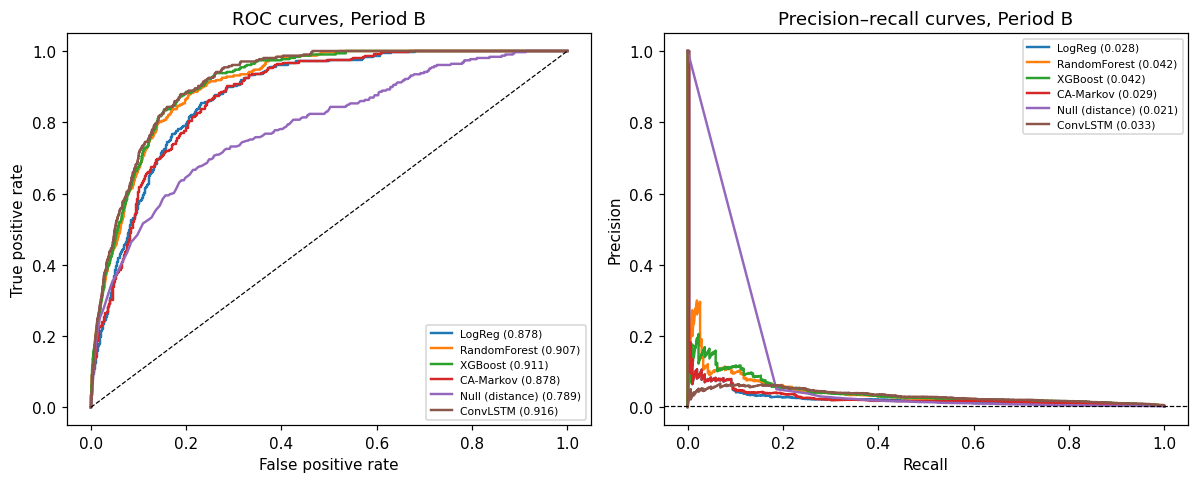

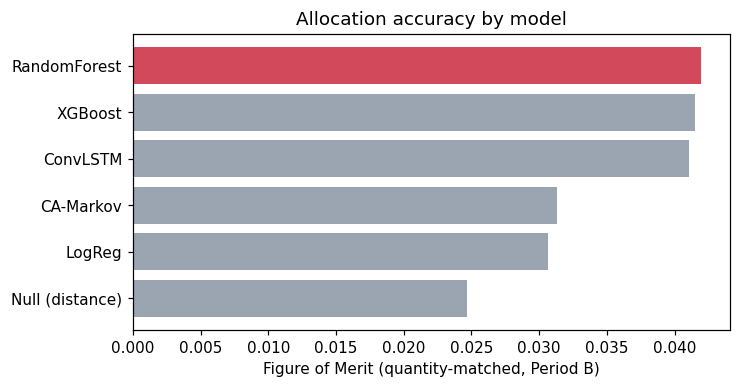

         unit  observed_new_px  ROC_AUC  hits  misses  false_alarms    FoM  producers_acc  users_acc
North cluster             3009   0.9198   203    2806          4183 0.0282         0.0675     0.0463
South cluster             1900   0.9035   315    1585          3251 0.0612         0.1658     0.0883
   Sreemangal             1900   0.9035   315    1585          3251 0.0612         0.1658     0.0883
  Companiganj              668   0.9367    64     604          1147 0.0353         0.0958     0.0528
   Gowainghat             1438   0.9218    82    1356          2098 0.0232         0.0570     0.0376
    Jaintapur              903   0.9015    57     846           938 0.0310         0.0631     0.0573

✅ Stage 5 finished in 7.4 min. Saved: ['BEST', 'N_MARKOV', 'error_maps', 'nB_years']
   Results are on Google Drive. You can now disconnect; the next stage can run in a new session.


In [ ]:
# ================= STAGE 5: RO3 – Evaluation on Period B, significance tests, accuracy by cluster and upazila =================
from google.colab import drive
drive.mount('/content/drive')
import os
assert os.path.exists('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py'), 'Run Stage 0 first: it saves the settings file to Google Drive.'
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())          # settings + helper functions (from Stage 0)
begin_stage(5, needs=['GRID', 'H', 'UPZ_NAMES', 'W', 'cluster', 'eligA', 'eligB', 'idxB', 'labA', 'labB', 'prob_maps', 'upz_id', 'yB'])

# ---- 6.5 Evaluation on Period B ----
rateA = labA.sum() / eligA.sum() / (PERIOD_A['new_to'] - PERIOD_A['new_from'] + 1)
nB_years = PERIOD_B['new_to'] - PERIOD_B['new_from'] + 1
N_MARKOV = int(round(rateA * nB_years * eligB.sum()))
N_TRUE = int(labB.sum())
print(f'Markov-projected quantity for Period B: {N_MARKOV:,} px | observed: {N_TRUE:,} px '
      f'(quantity error {100*(N_MARKOV-N_TRUE)/max(N_TRUE,1):+.1f} %)')
RESULTS['markov_quantity_B'] = N_MARKOV; RESULTS['observed_quantity_B'] = N_TRUE

eval_rows, error_maps = [], {}
for name, pm in prob_maps.items():
    p_s = np.nan_to_num(pm[idxB], nan=0.0)
    auc = roc_auc_score(yB, p_s); ap = average_precision_score(yB, p_s)
    auc_ci = boot_ci(yB, p_s, roc_auc_score); ap_ci = boot_ci(yB, p_s, average_precision_score)
    pred = top_n(pm, eligB, N_MARKOV)
    st = fom_stats(pred, labB, eligB)
    y_full, p_full = labB[eligB], pred[eligB]
    st_true = fom_stats(top_n(pm, eligB, N_TRUE), labB, eligB)
    is_prob = name in ('LogReg', 'RandomForest', 'XGBoost', 'ConvLSTM')   # outputs on a probability scale
    eval_rows.append(dict(model=name, ROC_AUC=auc, ROC_AUC_CI=f'{auc_ci[0]:.3f}–{auc_ci[1]:.3f}',
                          PR_AUC=ap, PR_AUC_CI=f'{ap_ci[0]:.3f}–{ap_ci[1]:.3f}', PR_baseline=yB.mean(),
                          Brier=brier_score_loss(yB, np.clip(p_s, 0, 1)) if is_prob else np.nan,
                          FoM=st['FoM'], FoM_true_quantity=st_true['FoM'],
                          producers_acc=st['producers_acc'], users_acc=st['users_acc'],
                          F1=f1_score(y_full, p_full), kappa=cohen_kappa_score(y_full, p_full)))
    em = np.zeros((H, W), 'uint8')
    em[pred & labB] = 1; em[~pred & labB] = 2; em[pred & ~labB & eligB] = 3
    error_maps[name] = em
evaluation = pd.DataFrame(eval_rows).sort_values('FoM', ascending=False)
print(evaluation.round(4).to_string(index=False))
evaluation.to_csv(OUT + '/RO3_model_comparison_periodB.csv', index=False)
BEST = evaluation[~evaluation.model.str.startswith('Null')].iloc[0]['model']
RESULTS['model_comparison'] = evaluation.round(4).to_dict(orient='records')
RESULTS['best_model_by_FoM'] = BEST
null_fom = float(evaluation.loc[evaluation.model.str.startswith('Null'), 'FoM'].iloc[0])
RESULTS['best_beats_null_FoM'] = bool(evaluation.loc[evaluation.model == BEST, 'FoM'].iloc[0] > null_fom)
print('\nBest model by Figure of Merit:', BEST, '| beats null model:', RESULTS['best_beats_null_FoM'])

for name, pm in prob_maps.items():
    save_tif(pm, f'RO3_prob_2021_2023_{name.replace(" ", "_").replace("(", "").replace(")", "")}.tif')
save_tif(error_maps[BEST], f'RO3_error_map_{BEST}.tif', dtype='uint8', nodata=0)

# ---- 6.5b Are the differences between models significant? (paired bootstrap on the same test pixels) ----
sig_idx = rng.choice(len(yB), min(SIG_SAMPLE, len(yB)), replace=False)
ys = yB[sig_idx]
scores = {n: np.nan_to_num(pm[idxB][sig_idx], nan=0.0) for n, pm in prob_maps.items()}
sig_rows = []
for other in scores:
    if other == BEST:
        continue
    d_auc, d_ap = [], []
    for _ in range(BOOTSTRAP):
        s = rng.choice(len(ys), len(ys), replace=True)
        if ys[s].min() == ys[s].max():
            continue
        d_auc.append(roc_auc_score(ys[s], scores[BEST][s]) - roc_auc_score(ys[s], scores[other][s]))
        d_ap.append(average_precision_score(ys[s], scores[BEST][s]) - average_precision_score(ys[s], scores[other][s]))
    d_auc, d_ap = np.array(d_auc), np.array(d_ap)
    sig_rows.append(dict(comparison=f'{BEST} vs {other}',
                         dROC_AUC=d_auc.mean(), dROC_AUC_CI=f'{np.percentile(d_auc, 2.5):.4f}–{np.percentile(d_auc, 97.5):.4f}',
                         p_ROC_AUC=min(1.0, 2 * min((d_auc <= 0).mean(), (d_auc >= 0).mean())),
                         dPR_AUC=d_ap.mean(), dPR_AUC_CI=f'{np.percentile(d_ap, 2.5):.4f}–{np.percentile(d_ap, 97.5):.4f}',
                         p_PR_AUC=min(1.0, 2 * min((d_ap <= 0).mean(), (d_ap >= 0).mean()))))
sig = pd.DataFrame(sig_rows)
print(sig.round(4).to_string(index=False))
print(f'(p = 0 means p < {1 / BOOTSTRAP:.3f})')
sig.to_csv(OUT + '/RO3_model_significance_tests.csv', index=False)
RESULTS['significance_vs_best'] = sig.round(4).to_dict(orient='records')

# ROC and precision-recall curves (Figure for the Results section)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
for n, sc in scores.items():
    fpr, tpr, _ = roc_curve(ys, sc); pr, rc, _ = precision_recall_curve(ys, sc)
    axs[0].plot(fpr, tpr, lw=1.6, label=f'{n} ({roc_auc_score(ys, sc):.3f})')
    axs[1].plot(rc, pr, lw=1.6, label=f'{n} ({average_precision_score(ys, sc):.3f})')
axs[0].plot([0, 1], [0, 1], 'k--', lw=0.8); axs[1].axhline(ys.mean(), color='k', ls='--', lw=0.8)
axs[0].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curves, Period B')
axs[1].set(xlabel='Recall', ylabel='Precision', title='Precision–recall curves, Period B')
for a in axs: a.legend(fontsize=7, loc='lower right' if a is axs[0] else 'upper right')
plt.tight_layout(); plt.savefig(FIG + '/fig_roc_pr_curves.png', bbox_inches='tight'); plt.show()

# Figure of Merit bar chart
fig, ax = plt.subplots(figsize=(7, 3.5))
ev = evaluation.sort_values('FoM')
ax.barh(ev.model, ev.FoM, color=['#d1495b' if m == BEST else '#9aa5b1' for m in ev.model])
ax.set_xlabel('Figure of Merit (quantity-matched, Period B)'); ax.set_title('Allocation accuracy by model')
plt.savefig(FIG + '/fig_model_FoM.png', bbox_inches='tight'); plt.show()

# ---- 6.6 Accuracy by cluster and upazila (spatial reliability) ----
rows = []
best_pred = top_n(prob_maps[BEST], eligB, N_MARKOV)
for nm, msk in [('North cluster', cluster == 1), ('South cluster', cluster == 2)] + \
               [(UPZ_NAMES[i], upz_id == i) for i in UPZ_NAMES]:
    e = eligB & msk
    sub = msk[idxB]
    auc = roc_auc_score(yB[sub], np.nan_to_num(prob_maps[BEST][idxB][sub])) if yB[sub].min() != yB[sub].max() else np.nan
    st = fom_stats(best_pred, labB, e)
    rows.append(dict(unit=nm, observed_new_px=int((labB & e).sum()), ROC_AUC=auc, **st))
by_unit = pd.DataFrame(rows)
print(by_unit.round(4).to_string(index=False))
by_unit.to_csv(OUT + f'/RO3_accuracy_by_unit_{BEST}.csv', index=False)

end_stage(5, exports=['BEST', 'GRID', 'H', 'N_MARKOV', 'UPZ_NAMES', 'W', 'cluster', 'eligA', 'eligB', 'error_maps', 'idxB', 'labA', 'labB', 'nB_years', 'prob_maps', 'upz_id', 'yB'])


## Stage 6 – RO4 – SHAP drivers, North vs South, ablation, label sensitivity, G4 test
**Runtime type:** CPU (High-RAM) · **Approx. time:** 20–40 min

**In the paper:** Supplementary Table S9 (label-threshold robustness). The final SHAP results in the paper come from Cell 2B.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 56.9 GB | CPUs: 12
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 361 files in Drive
Stage 6: loaded 26 saved results from earlier stages.
            feature  mean_abs_shap            group  share_%
     population_log          2.235   general growth   30.372
          elevation          1.309   general growth   17.782
 built_density_500m          0.640   general growth    8.700
   water_occurrence          0.594   general growth    8.077
      dist_any_road          0.392   general growth    5.332
              slope          0.333   general growth    4.520
              mndwi          0.297   general growth    4.040
   dist_sylhet_city          0.217   general growth    2.953
               ndbi          0.186   general growth    2.528
     dist_protected          0.166   general 

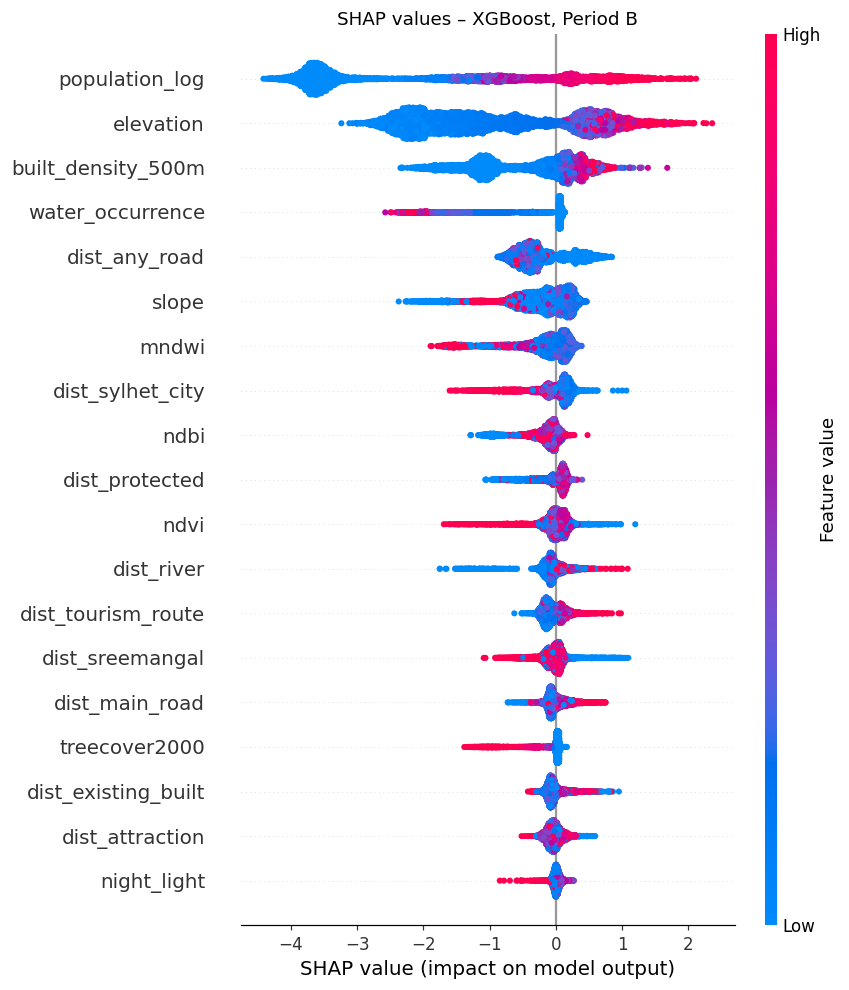

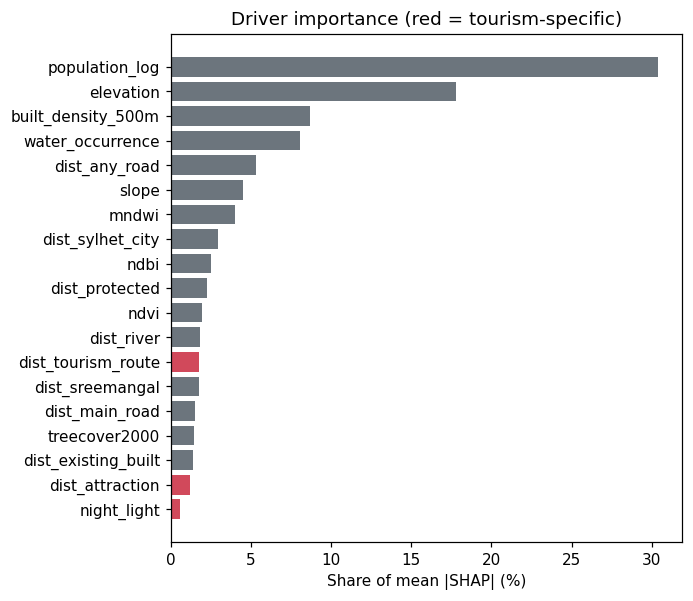

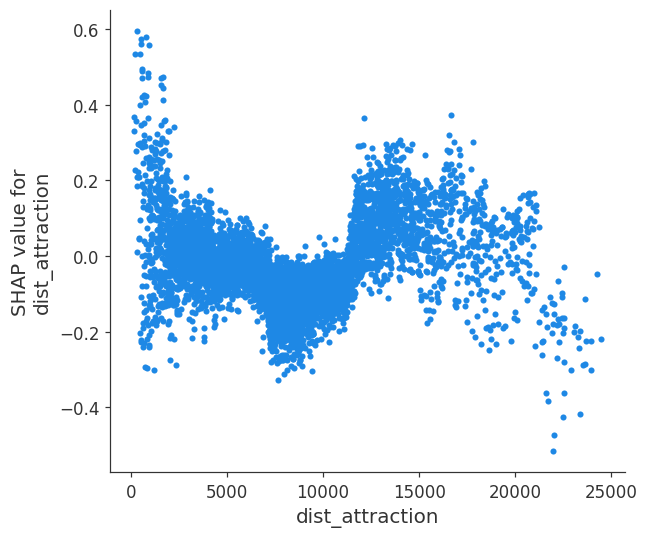

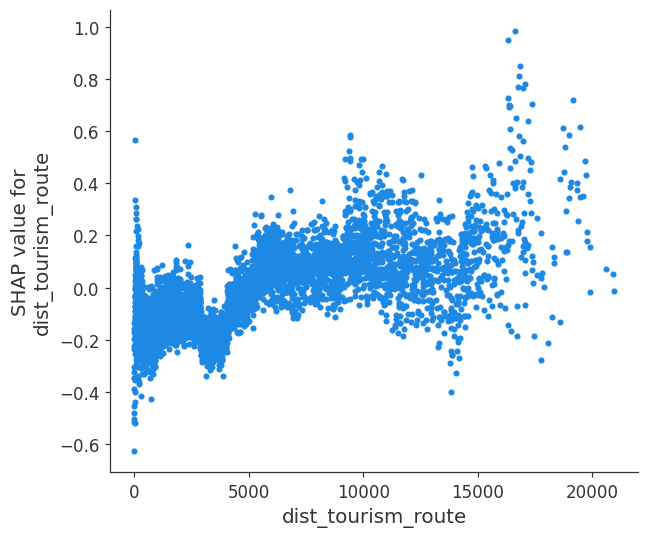

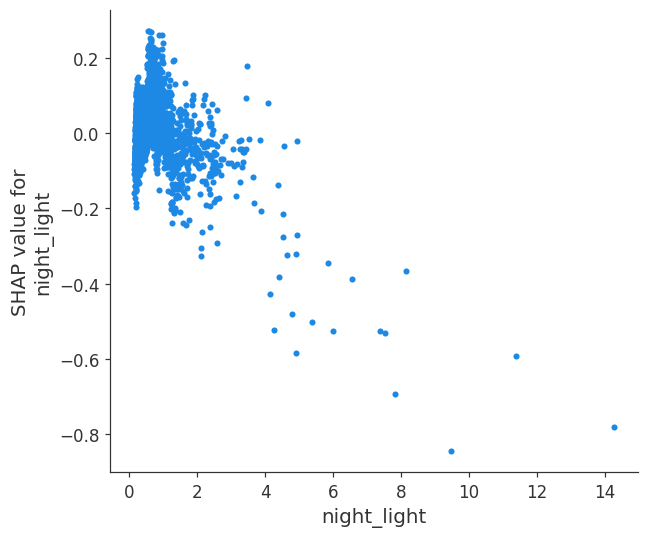

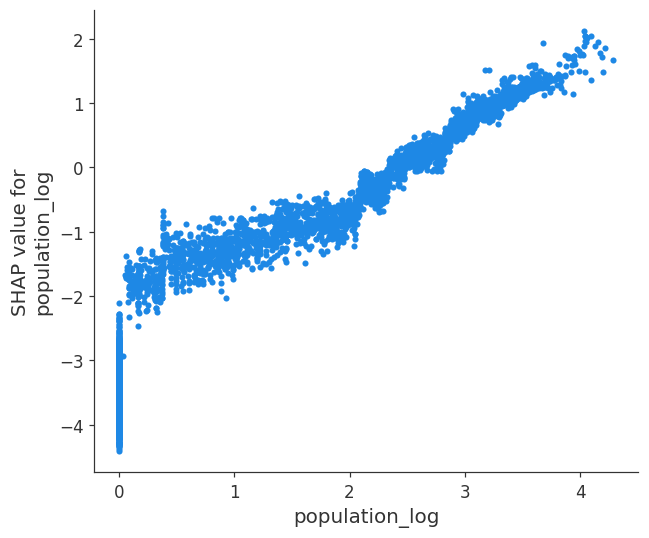

North cluster – tourism-specific share: 3.83 %
South cluster – tourism-specific share: 2.8 %


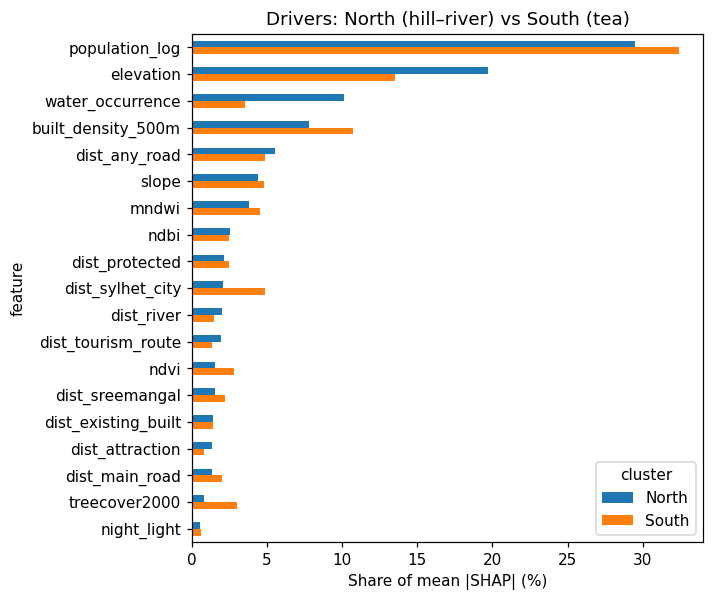

                              model  ROC_AUC  PR_AUC    FoM
            XGBoost, all predictors   0.9184  0.0380 0.0415
XGBoost, without tourism predictors   0.9187  0.0379 0.0434
FoM gain from tourism predictors inside the tourism zone: +0.0049
XGBoost without population_log: {'ROC_AUC': np.float64(0.914), 'PR_AUC': np.float64(0.0374), 'FoM': 0.042, 'tourism_shap_share_pct': 4.6883, 'top5': ['built_density_500m', 'elevation', 'water_occurrence', 'dist_any_road', 'slope']}
 threshold  positives_A  positives_B  ROC_AUC  PR_AUC    FoM  tourism_shap_share_pct
       0.3        10620         4909   0.9190  0.0363 0.0355                  3.3518
       0.2        29897        19136   0.9244  0.1220 0.0915                  3.5557
       0.5         1314          456   0.8380  0.0016 0.0055                  5.9110
              index  ROC_AUC  PR_AUC    FoM
SHAP-weighted index   0.8839  0.0196 0.0155
 Equal-weight index   0.7912  0.0109 0.0104

✅ Stage 6 finished in 1.7 min. Saved: []
   Resul

In [ ]:
# ================= STAGE 6: RO4 – SHAP drivers, North vs South, ablation, label sensitivity, G4 test =================
from google.colab import drive
drive.mount('/content/drive')
import os
assert os.path.exists('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py'), 'Run Stage 0 first: it saves the settings file to Google Drive.'
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())          # settings + helper functions (from Stage 0)
begin_stage(6, needs=['FEATURES', 'GENERAL_FEATURES', 'GRID', 'H', 'N_MARKOV', 'W', 'XA_i', 'XB_i', 'XGB_PARAMS', 'cluster', 'eB_c', 'eB_r', 'eligA', 'eligB', 'featsA', 'featsB', 'idxB', 'imputer', 'labB', 'models', 'prob_maps', 'spw', 'study', 'yA', 'yB', 'zone'])

xgbm = models['XGBoost']
samp = rng.choice(len(yB), min(6000, len(yB)), replace=False)
Xs = pd.DataFrame(XB_i[samp], columns=FEATURES)
explainer = shap.TreeExplainer(xgbm)
sv = explainer.shap_values(Xs)

def shap_table(sv_, cols):
    t = pd.DataFrame({'feature': cols, 'mean_abs_shap': np.abs(sv_).mean(0)})
    t['group'] = np.where(t.feature.isin(TOURISM_FEATURES), 'tourism-specific', 'general growth')
    t['share_%'] = 100 * t.mean_abs_shap / t.mean_abs_shap.sum()
    return t.sort_values('mean_abs_shap', ascending=False)

imp = shap_table(sv, FEATURES)
grp = imp.groupby('group')['share_%'].sum()
print(imp.round(3).to_string(index=False)); print('\nGroup shares (%):\n', grp.round(2))
imp.to_csv(OUT + '/RO4_shap_importance.csv', index=False)
RESULTS['shap_group_share_%'] = grp.round(2).to_dict()

# 95 % bootstrap CI of the tourism-specific SHAP share (resampling explained pixels)
tour_j = [FEATURES.index(f) for f in TOURISM_FEATURES]
abs_sv = np.abs(sv)
bs_share = []
for _ in range(BOOTSTRAP):
    s = rng.choice(len(abs_sv), len(abs_sv), replace=True)
    m_ = abs_sv[s].mean(0); bs_share.append(100 * m_[tour_j].sum() / m_.sum())
RESULTS['shap_tourism_share_CI95_%'] = [round(float(v), 2) for v in np.percentile(bs_share, [2.5, 97.5])]
print('Tourism-specific SHAP share 95 % CI:', RESULTS['shap_tourism_share_CI95_%'])
RESULTS['shap_top5'] = imp.feature.head(5).tolist()

shap.summary_plot(sv, Xs, show=False, max_display=len(FEATURES))
plt.title('SHAP values – XGBoost, Period B'); plt.tight_layout()
plt.savefig(FIG + '/fig_shap_summary.png', bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(figsize=(6, 6))
colors = ['#d1495b' if g == 'tourism-specific' else '#6c757d' for g in imp.group]
ax.barh(imp.feature[::-1], imp['share_%'][::-1], color=colors[::-1])
ax.set_xlabel('Share of mean |SHAP| (%)'); ax.set_title('Driver importance (red = tourism-specific)')
plt.savefig(FIG + '/fig_shap_importance_groups.png', bbox_inches='tight'); plt.show()

for f in TOURISM_FEATURES + [imp.feature.iloc[0]]:
    shap.dependence_plot(f, sv, Xs, interaction_index=None, show=False)
    plt.tight_layout(); plt.savefig(FIG + f'/fig_shap_dependence_{f}.png', bbox_inches='tight'); plt.show()

# ---- SHAP by cluster ----
cl_s = cluster[idxB][samp]
rows = []
for cid, nm in [(1, 'North'), (2, 'South')]:
    m = cl_s == cid
    if m.sum() < 50:
        continue
    t = shap_table(sv[m], FEATURES)
    t['cluster'] = nm; rows.append(t)
    print(nm, 'cluster – tourism-specific share:',
          round(t.loc[t.group == 'tourism-specific', 'share_%'].sum(), 2), '%')
if rows:
    by_cl = pd.concat(rows)
    by_cl.to_csv(OUT + '/RO4_shap_by_cluster.csv', index=False)
    RESULTS['shap_tourism_share_by_cluster_%'] = by_cl[by_cl.group == 'tourism-specific'].groupby('cluster')['share_%'].sum().round(2).to_dict()
    piv = by_cl.pivot(index='feature', columns='cluster', values='share_%').sort_values('North', ascending=False)
    piv.plot.barh(figsize=(6, 6)); plt.gca().invert_yaxis(); plt.xlabel('Share of mean |SHAP| (%)')
    plt.title('Drivers: North (hill–river) vs South (tea)')
    plt.savefig(FIG + '/fig_shap_by_cluster.png', bbox_inches='tight'); plt.show()

# ---- 7.3 Ablation: how much predictive skill do the tourism predictors add? ----
# XGBoost is retrained on Period A without the tourism-specific predictors and tested on Period B.
gen_j = [FEATURES.index(f) for f in GENERAL_FEATURES]
xgb_gen = make_xgb().fit(XA_i[:, gen_j], yA)
p_gen = np.full((H, W), np.nan, 'float32')
for s in range(0, len(eB_r), 400_000):
    r, c = eB_r[s:s + 400_000], eB_c[s:s + 400_000]
    p_gen[r, c] = xgb_gen.predict_proba(imputer.transform(matrix(featsB, (r, c)))[:, gen_j])[:, 1]
abl = []
for nm, pm in [('XGBoost, all predictors', prob_maps['XGBoost']), ('XGBoost, without tourism predictors', p_gen)]:
    ps = np.nan_to_num(pm[idxB]); st = fom_stats(top_n(pm, eligB, N_MARKOV), labB, eligB)
    abl.append(dict(model=nm, ROC_AUC=roc_auc_score(yB, ps), PR_AUC=average_precision_score(yB, ps), FoM=st['FoM']))
abl = pd.DataFrame(abl)
ez, n_z = eligB & zone, int((labB & zone).sum())          # inside the tourism zone, observed quantity
gain_in_zone = (fom_stats(top_n(prob_maps['XGBoost'], ez, n_z), labB, ez)['FoM']
                - fom_stats(top_n(p_gen, ez, n_z), labB, ez)['FoM'])
print(abl.round(4).to_string(index=False))
print(f'FoM gain from tourism predictors inside the tourism zone: {gain_in_zone:+.4f}')
abl.to_csv(OUT + '/RO4_ablation_tourism_predictors.csv', index=False)
RESULTS['ablation_tourism'] = dict(table=abl.round(4).to_dict(orient='records'), FoM_gain_in_zone=round(float(gain_in_zone), 4))

# ---- 7.3b Population sensitivity: is the result driven by the modelled WorldPop layer? ----
# WorldPop constrained estimates are distributed using building / settlement data, so population can partly
# 'see' buildings. XGBoost is retrained without population_log to check that the main conclusions hold.
nopop = [f for f in FEATURES if f != 'population_log']
np_j = [FEATURES.index(f) for f in nopop]
xgb_np = make_xgb().fit(XA_i[:, np_j], yA)
p_np = np.full((H, W), np.nan, 'float32')
for s in range(0, len(eB_r), 400_000):
    r, c = eB_r[s:s + 400_000], eB_c[s:s + 400_000]
    p_np[r, c] = xgb_np.predict_proba(imputer.transform(matrix(featsB, (r, c)))[:, np_j])[:, 1]
ps = np.nan_to_num(p_np[idxB])
sv_np = shap.TreeExplainer(xgb_np).shap_values(Xs[nopop])
m_np = np.abs(sv_np).mean(0)
tj_np = [nopop.index(f) for f in TOURISM_FEATURES]
imp_np = pd.DataFrame({'feature': nopop, 'share_%': 100 * m_np / m_np.sum()}).sort_values('share_%', ascending=False)
popsens = dict(ROC_AUC=roc_auc_score(yB, ps), PR_AUC=average_precision_score(yB, ps),
               FoM=fom_stats(top_n(p_np, eligB, N_MARKOV), labB, eligB)['FoM'],
               tourism_shap_share_pct=float(100 * m_np[tj_np].sum() / m_np.sum()),
               top5=imp_np.feature.head(5).tolist())
print('XGBoost without population_log:', {k: (round(v, 4) if isinstance(v, float) else v) for k, v in popsens.items()})
imp_np.to_csv(OUT + '/S3_shap_without_population.csv', index=False)
RESULTS['population_sensitivity'] = popsens

# ---- 7.4 Label sensitivity: are the results robust to the 30 % construction threshold? ----
lab_rows = []
fracA = new_fraction(PERIOD_A['new_from'], PERIOD_A['new_to'])
fracB = new_fraction(PERIOD_B['new_from'], PERIOD_B['new_to'])
for thr in [LABEL_THRESHOLD] + list(LABEL_SENS):
    lA = (fracA >= thr) & eligA
    lB = (fracB >= thr) & eligB
    if lA.sum() < 50 or lB.sum() < 50:
        print('threshold', thr, 'skipped: too few positives'); continue
    pA_ = np.where(lA); nA_ = np.where(eligA & ~lA)
    pk = rng.choice(len(nA_[0]), min(len(nA_[0]), NEG_PER_POS * len(pA_[0])), replace=False)
    ii = (np.r_[pA_[0], nA_[0][pk]], np.r_[pA_[1], nA_[1][pk]])
    m_thr = make_xgb().fit(imputer.transform(matrix(featsA, ii)), lA[ii].astype(int))
    pm = predict_map(m_thr, featsB, eB_r, eB_c)
    yb = lB[idxB].astype(int); ps = np.nan_to_num(pm[idxB])
    sv_t = shap.TreeExplainer(m_thr).shap_values(Xs)
    tshare = 100 * np.abs(sv_t)[:, tour_j].mean(0).sum() / np.abs(sv_t).mean(0).sum()
    lab_rows.append(dict(threshold=thr, positives_A=int(lA.sum()), positives_B=int(lB.sum()),
                         ROC_AUC=roc_auc_score(yb, ps), PR_AUC=average_precision_score(yb, ps),
                         FoM=fom_stats(top_n(pm, eligB, int(lB.sum())), lB, eligB)['FoM'],
                         tourism_shap_share_pct=tshare))
lab_sens = pd.DataFrame(lab_rows)
print(lab_sens.round(4).to_string(index=False))
lab_sens.to_csv(OUT + '/S2_label_threshold_sensitivity.csv', index=False)
RESULTS['label_sensitivity'] = lab_sens.round(4).to_dict(orient='records')

# ---- G4 test: SHAP-weighted vs equal-weight development-pressure index ----
direction = {}
for j, f in enumerate(FEATURES):
    rho = spearmanr(Xs[f], sv[:, j]).correlation
    direction[f] = 1 if (np.isnan(rho) or rho >= 0) else -1
w_shap = (imp.set_index('feature')['mean_abs_shap'] / imp['mean_abs_shap'].sum()).to_dict()

norm_feats = {}
for f in FEATURES:
    n = norm01(featsB[f], study)
    norm_feats[f] = n if direction[f] > 0 else 1 - n
P_shap = sum(w_shap[f] * norm_feats[f] for f in FEATURES)
P_equal = sum(norm_feats[f] for f in FEATURES) / len(FEATURES)

g4 = []
for nm, P in [('SHAP-weighted index', P_shap), ('Equal-weight index', P_equal)]:
    p_s = np.nan_to_num(P[idxB]); st = fom_stats(top_n(P, eligB, N_MARKOV), labB, eligB)
    g4.append(dict(index=nm, ROC_AUC=roc_auc_score(yB, p_s), PR_AUC=average_precision_score(yB, p_s), FoM=st['FoM']))
g4 = pd.DataFrame(g4)
print(g4.round(4).to_string(index=False))
g4.to_csv(OUT + '/RO4_G4_shap_vs_equal_weights.csv', index=False)
RESULTS['G4_test'] = g4.round(4).to_dict(orient='records')
pd.DataFrame({'feature': FEATURES, 'shap_weight': [w_shap[f] for f in FEATURES],
              'direction': [direction[f] for f in FEATURES]}).to_csv(OUT + '/RO4_shap_weights.csv', index=False)

end_stage(6, exports=['FEATURES', 'GRID', 'H', 'W', 'XGB_PARAMS', 'eligB', 'featsB', 'imputer', 'labB', 'prob_maps', 'spw', 'study', 'yA', 'zone'])


## Stage 7 – RO6 – Final XGBoost ensemble and Monte Carlo scenarios 2024–2035
**Runtime type:** CPU (High-RAM) · **Approx. time:** 60–150 min

**In the paper:** Sections 4.8 and 5.6, Table 8 (label-based totals), Figure 7 and Supplementary Figure S3.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 56.9 GB | CPUs: 12
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 360 files in Drive
Stage 7: loaded 21 saved results from earlier stages.
Final ensemble trained on 93174 samples
Observed mean conversion: 2,218 px/yr (2.00 km²/yr), CV 0.25
Low: loaded saved results (/content/drive/MyDrive/Sylhet_outputs/cache/scenario_Low_x0.83_n100.npz)
  Medium: 10/100 runs, 134 s
  Medium: 20/100 runs, 268 s
  Medium: 30/100 runs, 398 s
  Medium: 40/100 runs, 529 s
  Medium: 50/100 runs, 660 s
  Medium: 60/100 runs, 792 s
  Medium: 70/100 runs, 923 s
  Medium: 80/100 runs, 1054 s
  Medium: 90/100 runs, 1185 s
  Medium: 100/100 runs, 1316 s
Medium (x1.0): 100 runs in 1317 s
  High: 10/100 runs, 132 s
  High: 20/100 runs, 263 s
  High: 30/100 runs, 394 s
  High: 40/100 runs, 526 s
  High: 50/100 run

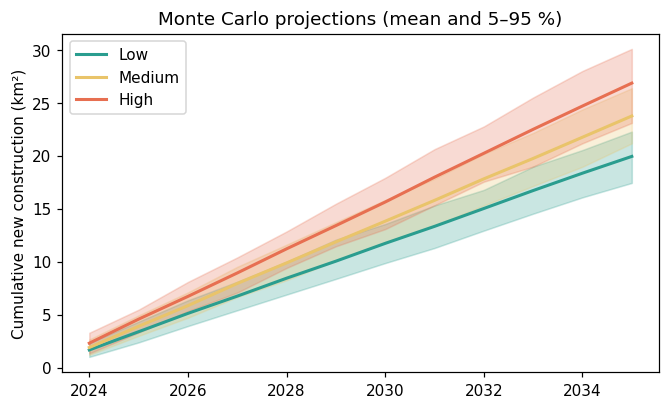


✅ Stage 7 finished in 44.3 min. Saved: ['near_pa', 'px_km2', 'scen_out']
   Results are on Google Drive. You can now disconnect; the next stage can run in a new session.


In [ ]:
# ================= STAGE 7: RO6 – Final XGBoost ensemble and Monte Carlo scenarios 2024–2035 =================
from google.colab import drive
drive.mount('/content/drive')
import os
assert os.path.exists('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py'), 'Run Stage 0 first: it saves the settings file to Google Drive.'
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())          # settings + helper functions (from Stage 0)
begin_stage(7, needs=['FEATURES', 'GRID', 'H', 'RES', 'SCENARIOS', 'W', 'XA', 'XGB_PARAMS', 'built', 'eligB', 'featsB', 'imputer', 'labA', 'labB', 'nB_years', 'spw', 'static', 'study', 'tree_now', 'yA', 'zone'])

posB = np.where(labB); negB = np.where(eligB & ~labB)
pickNB = rng.choice(len(negB[0]), min(len(negB[0]), NEG_PER_POS * len(posB[0])), replace=False)
idxB_tr = (np.r_[posB[0], negB[0][pickNB]], np.r_[posB[1], negB[1][pickNB]])
X_all = imputer.transform(np.vstack([XA, matrix(featsB, idxB_tr)]))
y_all = np.r_[yA, labB[idxB_tr].astype(int)]

ensemble = []
for k in range(N_ENSEMBLE):
    bs = rng.choice(len(y_all), len(y_all), replace=True)
    ensemble.append(make_xgb(seed=SEED + k).fit(X_all[bs], y_all[bs]))
    joblib.dump(ensemble[-1], OUT + f'/model_XGBoost_final_{k}.joblib')
print('Final ensemble trained on', len(y_all), 'samples')

yrsA = PERIOD_A['new_to'] - PERIOD_A['new_from'] + 1
RATE_PX = (labA.sum() + labB.sum()) / (yrsA + nB_years)          # mean pixels converted per year
RATE_CV = RESULTS['annual_new_km2_cv']
print(f'Observed mean conversion: {RATE_PX:,.0f} px/yr ({RATE_PX*RES*RES/1e6:.2f} km²/yr), CV {RATE_CV:.2f}')

base_feats = dict(static); base_feats.update(dynamic(PROJ_START))
built0 = built[PROJ_START].copy()
elig0 = study & (built0 < BUILT_START_MAX) & (static['water_occurrence'] < WATER_MAX)
YEARS_SIM = list(range(PROJ_START + 1, PROJ_END + 1))

def predict_elig(model, feats, elig):
    r, c = np.where(elig)
    p = np.zeros(len(r), 'float32')
    for s in range(0, len(r), 500_000):
        p[s:s + 500_000] = model.predict_proba(imputer.transform(matrix(feats, (r[s:s + 500_000], c[s:s + 500_000]))))[:, 1]
    return r, c, p

def run_once(mult):
    model = ensemble[rng.integers(len(ensemble))]
    b = built0.copy(); elig = elig0.copy()
    conv_year = np.zeros((H, W), 'int16'); cum = []
    total = 0
    for i, yr in enumerate(YEARS_SIM):
        if i % UPDATE_EVERY == 0:
            feats = dict(base_feats); feats.update(neighbourhood(b))
            r, c, p = predict_elig(model, feats, elig)
            alive = np.ones(len(r), bool)
        n = int(max(0, rng.normal(RATE_PX * mult, RATE_PX * mult * RATE_CV)))
        cand = np.where(alive)[0]
        n = min(n, len(cand))
        if n > 0:
            w = np.power(np.clip(p[cand], 1e-9, 1), ALLOC_SHARPNESS)
            keys = np.log(w) + rng.gumbel(size=len(cand))        # weighted sampling without replacement
            chosen = cand[np.argpartition(-keys, n - 1)[:n]]
            alive[chosen] = False
            conv_year[r[chosen], c[chosen]] = yr
            b[r[chosen], c[chosen]] = 100.0
            elig[r[chosen], c[chosen]] = False
            total += n
        cum.append(total)
    return conv_year, cum

scen_out = {}
for sname, mult in SCENARIOS.items():
    cache_f = f'{CACHE}/scenario_{sname}_x{mult}_n{N_SIM}.npz'
    if RESUME and os.path.exists(cache_f):
        z = np.load(cache_f)
        scen_out[sname] = dict(p2030=z['p2030'], p2035=z['p2035'], cum=z['cum'])
        print(f'{sname}: loaded saved results ({cache_f})'); continue
    t0 = time.time()
    c2030 = np.zeros((H, W), 'float32'); c2035 = np.zeros((H, W), 'float32'); cums = []
    for k in range(N_SIM):
        cy, cum = run_once(mult)
        c2030 += (cy > 0) & (cy <= 2030); c2035 += cy > 0; cums.append(cum)
        if (k + 1) % 10 == 0:
            print(f'  {sname}: {k + 1}/{N_SIM} runs, {time.time() - t0:.0f} s')
    scen_out[sname] = dict(p2030=c2030 / N_SIM, p2035=c2035 / N_SIM, cum=np.array(cums))
    np.savez_compressed(cache_f, **scen_out[sname])
    print(f'{sname} (x{mult}): {N_SIM} runs in {time.time()-t0:.0f} s')

# Year-by-year cumulative projection table (for the Results section)
yearly = []
for sname, so in scen_out.items():
    c = so['cum'] * RES * RES / 1e6
    for j, yr in enumerate(YEARS_SIM):
        yearly.append(dict(scenario=sname, year=yr, mean_km2=c[:, j].mean(),
                           p5_km2=np.percentile(c[:, j], 5), p95_km2=np.percentile(c[:, j], 95)))
pd.DataFrame(yearly).round(3).to_csv(OUT + '/RO6_cumulative_by_year.csv', index=False)

# Quantity sensitivity (Supplementary Material): total new construction by 2035 for a range of multipliers
pool = int(elig0.sum()); sens = []
for m in SENS_MULTS:
    tots = []
    for k in range(1000):
        draws = np.maximum(0, rng.normal(RATE_PX * m, RATE_PX * m * RATE_CV, len(YEARS_SIM)))
        tots.append(min(pool, int(draws.astype(int).sum())) * RES * RES / 1e6)
    tots = np.array(tots)
    sens.append(dict(multiplier=m, new_km2_2035_mean=tots.mean(),
                     p5=np.percentile(tots, 5), p95=np.percentile(tots, 95)))
sens = pd.DataFrame(sens).round(2)
print(sens.to_string(index=False))
sens.to_csv(OUT + '/RO5_quantity_sensitivity.csv', index=False)
RESULTS['quantity_sensitivity'] = sens.to_dict('records')

px_km2 = RES * RES / 1e6
near_pa = (static['dist_protected'] <= 1000) & study
rows = []
for sname, so in scen_out.items():
    tot = so['cum'][:, -1] * px_km2
    p = so['p2035']
    rows.append(dict(scenario=sname,
                     new_km2_2035_mean=tot.mean(), new_km2_2035_p5=np.percentile(tot, 5), new_km2_2035_p95=np.percentile(tot, 95),
                     expected_km2_in_tourism_zone=(p * zone).sum() * px_km2,
                     share_in_tourism_zone_pct=100 * (p * zone).sum() / max(p.sum(), 1e-9),
                     expected_km2_within_1km_protected=(p * near_pa).sum() * px_km2,
                     expected_forest_loss_km2=(p * (tree_now >= 30)).sum() * px_km2,
                     area_prob_ge_0_5_km2=((p >= 0.5) & study).sum() * px_km2))
    save_tif(so['p2030'], f'RO6_prob_conversion_2030_{sname}.tif')
    save_tif(so['p2035'], f'RO6_prob_conversion_2035_{sname}.tif')
scen_tab = pd.DataFrame(rows)
print(scen_tab.round(3).to_string(index=False))
scen_tab.to_csv(OUT + '/RO6_scenario_summary_2035.csv', index=False)
RESULTS['scenarios_2035'] = scen_tab.round(3).to_dict(orient='records')

fig, ax = plt.subplots(figsize=(7, 4))
cols = {'Low': '#2a9d8f', 'Medium': '#e9c46a', 'High': '#e76f51'}
for sname, so in scen_out.items():
    c = so['cum'] * px_km2
    ax.fill_between(YEARS_SIM, np.percentile(c, 5, 0), np.percentile(c, 95, 0), alpha=0.25, color=cols.get(sname))
    ax.plot(YEARS_SIM, c.mean(0), label=sname, color=cols.get(sname), lw=2)
ax.set_ylabel('Cumulative new construction (km²)'); ax.set_title('Monte Carlo projections (mean and 5–95 %)')
ax.legend(); plt.savefig(FIG + '/fig_scenarios_uncertainty.png', bbox_inches='tight'); plt.show()

end_stage(7, exports=['GRID', 'H', 'RES', 'SCENARIOS', 'W', 'labA', 'labB', 'near_pa', 'px_km2', 'scen_out', 'static', 'study', 'tree_now', 'zone'])


## Stage 8 – RO5 + RO7 – Vulnerability, decision-support zones, publication figures, key results
**Runtime type:** CPU (High-RAM) · **Approx. time:** 10–20 min

**In the paper:** Section 4.8 (exposure-weighted ecological sensitivity), Figure 8, Supplementary Tables S14–S16.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 56.9 GB | CPUs: 12
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 361 files in Drive
Stage 8: loaded 30 saved results from earlier stages.
{'very_high_km2': 82.0368, 'very_high_robust_km2': 69.075, 'robust_share_of_very_high_pct': 84.20001755309812, 'very_high_in_tourism_zone_pct': 21.638581709671758}
Planning-watch hotspot definitions (High scenario, 2035):
 top_pct  prob_threshold  area_km2  expected_new_km2_inside  share_of_expected_new_pct  share_in_tourism_zone_pct
     1.0            0.16   18.7515                   3.3010                  12.288300                    22.2174
     2.0            0.14   39.2157                   6.2545                  23.282801                    21.0773
     5.0            0.11   89.2512                  12.2080                  45.445000     

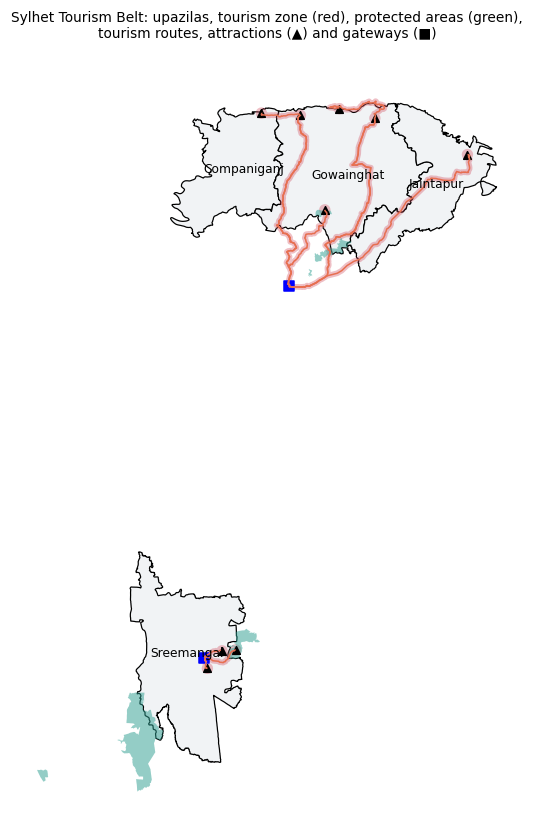

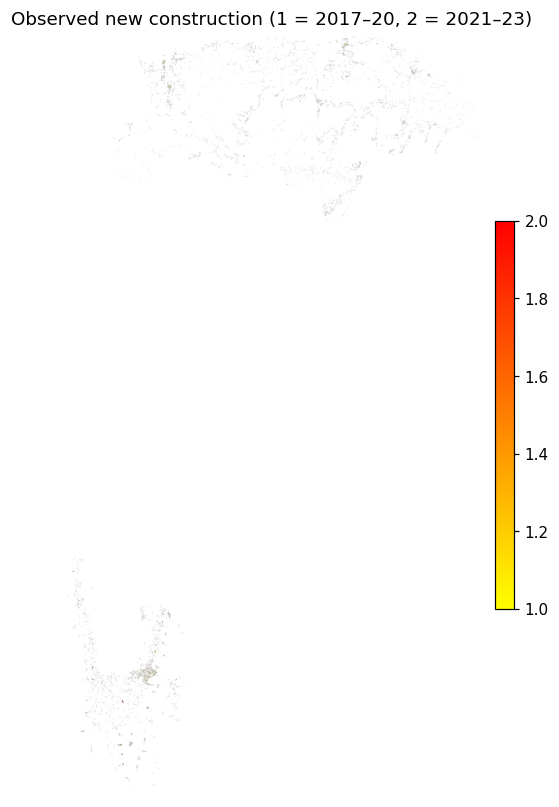

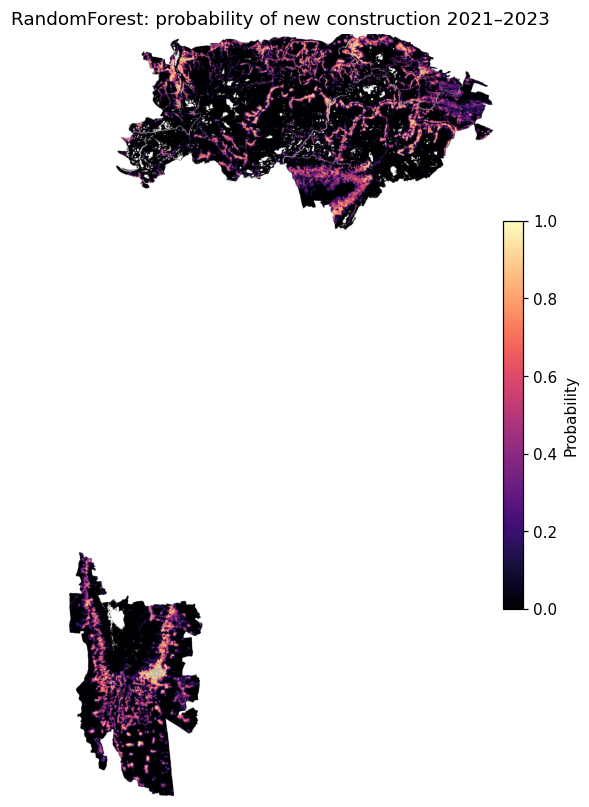

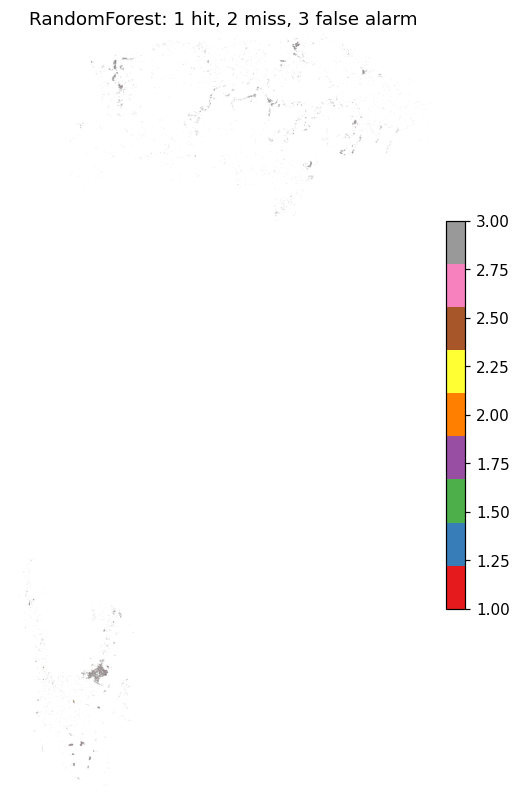

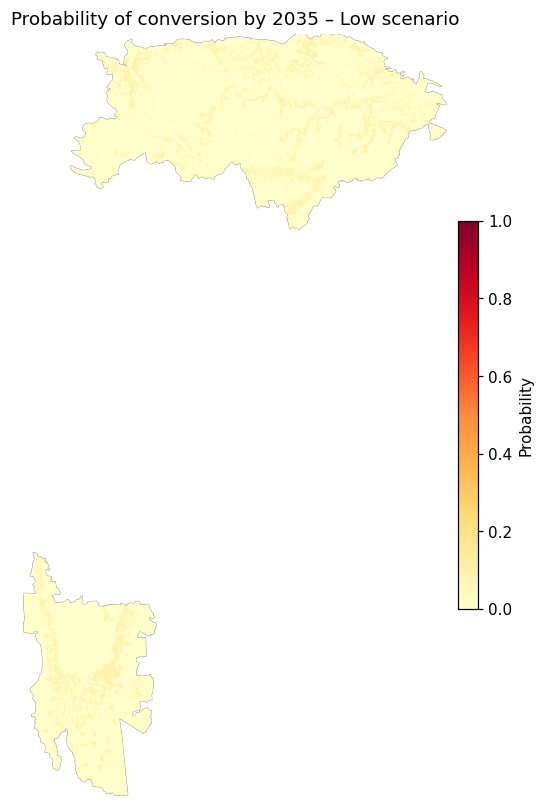

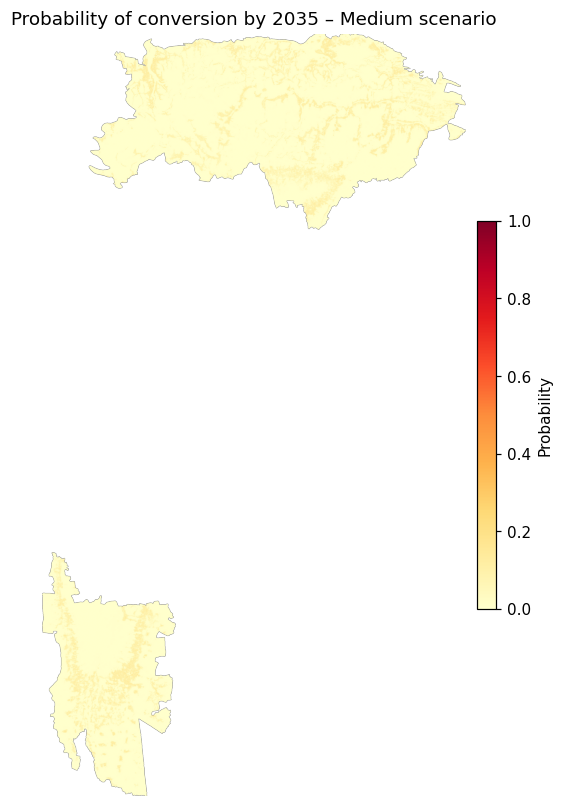

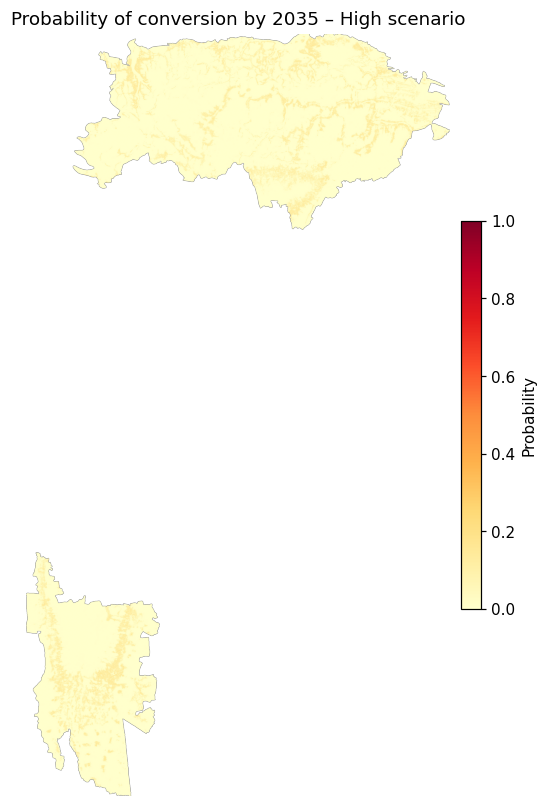

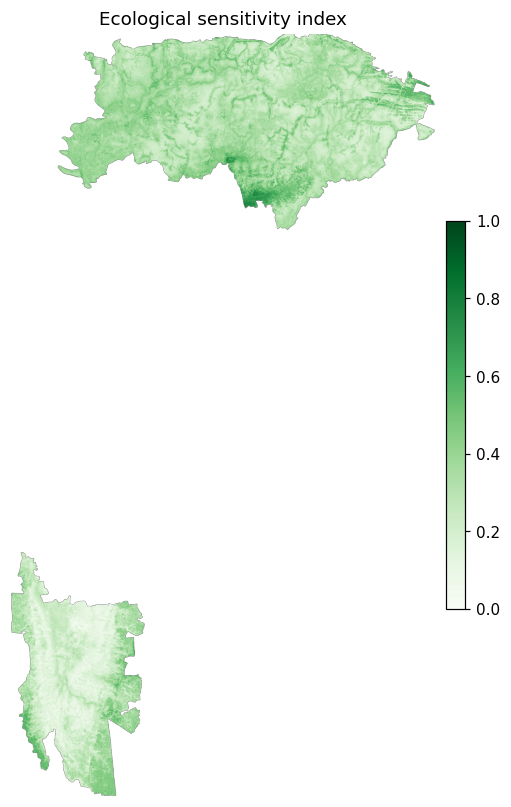

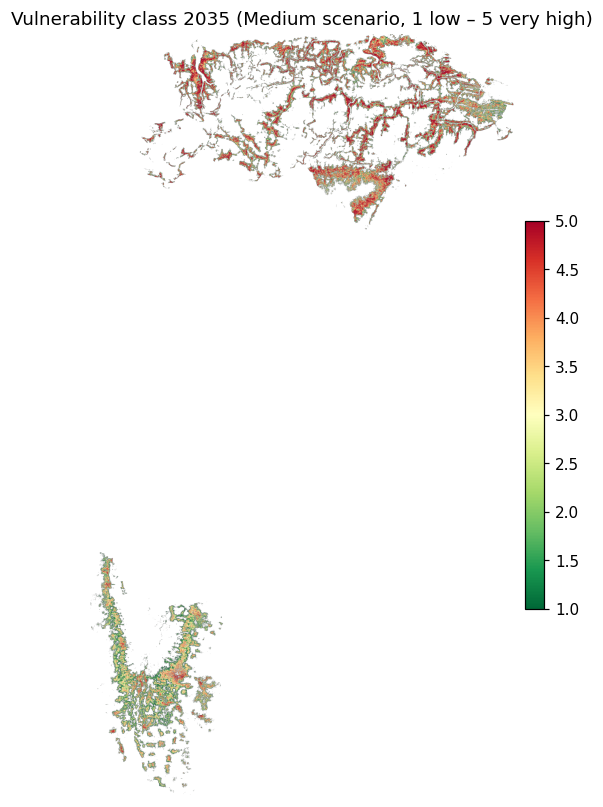

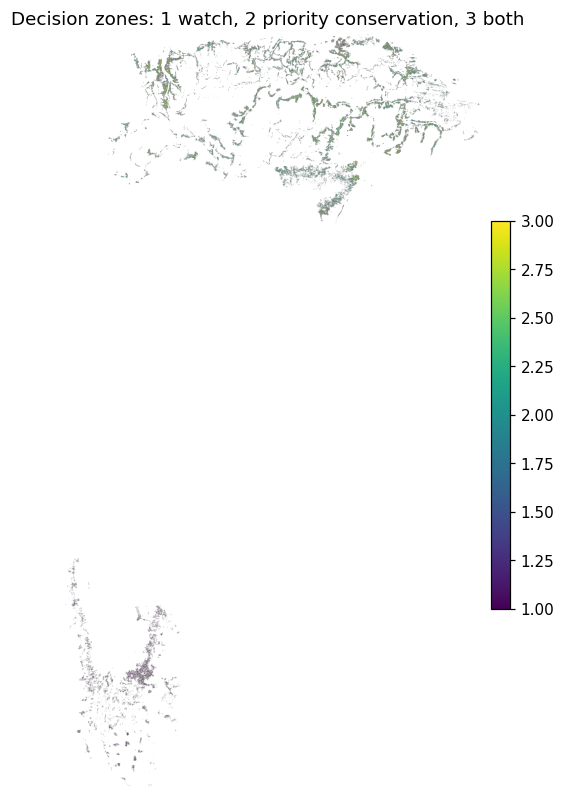

{
  "study_area_km2": 1455.1209,
  "annual_new_km2_mean": 3.206142857142857,
  "annual_new_km2_cv": 0.2536671976989573,
  "zone_share_of_new_2017_2023_%": 18.359399367286017,
  "scenario_windows": {
    "slowest": "2019\u20132021",
    "fastest": "2017\u20132019"
  },
  "scenario_multipliers": {
    "Low": 0.83,
    "Medium": 1.0,
    "High": 1.11
  },
  "labels": {
    "A_pos": 10620,
    "A_elig": 1564159,
    "B_pos": 4909,
    "B_elig": 1561535
  },
  "collinearity": {
    "max_VIF": 32.777402223002575,
    "max_VIF_feature": "mndwi",
    "high_pairs": [
      [
        "elevation",
        "water_occurrence",
        -0.74
      ],
      [
        "dist_sreemangal",
        "dist_protected",
        0.72
      ],
      [
        "population_log",
        "built_density_500m",
        0.87
      ],
      [
        "built_density_500m",
        "dist_existing_built",
        -0.74
      ]
    ]
  },
  "tuned_params": {
    "RandomForest": {
      "n_estimators": 500,
      "min_samp

In [ ]:
# ================= STAGE 8: RO5 + RO7 – Vulnerability, decision-support zones, publication figures, key results =================
from google.colab import drive
drive.mount('/content/drive')
import os
assert os.path.exists('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py'), 'Run Stage 0 first: it saves the settings file to Google Drive.'
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())          # settings + helper functions (from Stage 0)
begin_stage(8, needs=['BEST', 'C0', 'C1', 'GRID', 'H', 'HAS_S2', 'R0', 'R1', 'RES', 'SCENARIOS', 'UPZ_NAMES', 'W', 'error_maps', 'gw', 'labA', 'labB', 'monsoon', 'name_col', 'near_pa', 'prob_maps', 'px_km2', 'rivers_mask', 'scen_out', 'static', 'study', 'tree_now', 'upz', 'upz_id', 'zone', 'zone_gdf'])

if HAS_S2:
    ndvi_veg = to_grid('S2_dry_2023*.tif', band=7, method=Resampling.average, scale=1 / 10000)
else:
    ndvi_veg = dynamic(PROJ_START)['ndvi']
water_any = (static['water_occurrence'] >= WATER_MAX) | (rivers_mask > 0)
comp = {
    'forest': norm01(tree_now, study),
    'vegetation': norm01(ndvi_veg, study),
    'water': np.exp(-dist_to(water_any) / 500).astype('float32'),
    'slope': norm01(static['slope'], study),
    'protected': np.exp(-static['dist_protected'] / 1000).astype('float32'),
    'monsoon_rain': norm01(monsoon, study),
}
for k in comp:
    comp[k] = np.nan_to_num(comp[k], nan=0.0)
wv = np.array([SENS_WEIGHTS[k] for k in comp], float); wv /= wv.sum()
SENS = sum(w * comp[k] for w, k in zip(wv, comp)).astype('float32')

def vulnerability(exposure, sens):
    return (np.nan_to_num(exposure) * sens).astype('float32')

V_med = vulnerability(scen_out['Medium']['p2035'], SENS)
V_high = vulnerability(scen_out['High']['p2035'], SENS)

# Classes: 0 = none (no exposure), 1-5 = quintiles of vulnerability among exposed pixels
def classes(V, ref):
    exp_mask = study & (V > 0)
    qs = np.percentile(ref[exp_mask], [20, 40, 60, 80]) if exp_mask.any() else [0, 0, 0, 0]
    c = np.zeros(V.shape, 'uint8'); c[exp_mask] = 1 + np.digitize(V[exp_mask], qs)
    return c, qs
V_cls, QS = classes(V_med, V_med)
V_cls_high = np.zeros(V_high.shape, 'uint8'); m = study & (V_high > 0)
V_cls_high[m] = 1 + np.digitize(V_high[m], QS)

# Weight uncertainty: how often is a pixel in the top-20 % class?
top_count = np.zeros((H, W), 'float32')
expo = np.nan_to_num(scen_out['Medium']['p2035'])
for _ in range(SENS_WEIGHT_DRAWS):
    wd = rng.dirichlet(np.full(len(comp), 5.0))
    Vd = expo * sum(w * comp[k] for w, k in zip(wd, comp))
    mm = study & (Vd > 0)
    if mm.any():
        top_count += (Vd >= np.percentile(Vd[mm], 80)) & mm
stability = top_count / SENS_WEIGHT_DRAWS
robust_high = (V_cls == 5) & (stability >= 0.8)
RESULTS['vulnerability'] = dict(
    very_high_km2=float((V_cls == 5).sum() * px_km2),
    very_high_robust_km2=float(robust_high.sum() * px_km2),
    robust_share_of_very_high_pct=float(100 * robust_high.sum() / max((V_cls == 5).sum(), 1)),
    very_high_in_tourism_zone_pct=float(100 * ((V_cls == 5) & zone).sum() / max((V_cls == 5).sum(), 1)))
print(RESULTS['vulnerability'])

for nm, arr in [('sensitivity_index', SENS), ('vulnerability_medium_2035', V_med), ('vulnerability_high_2035', V_high),
                ('vulnerability_weight_stability', stability)]:
    save_tif(np.where(study, arr, np.nan), f'RO5_{nm}.tif')
save_tif(V_cls, 'RO5_vulnerability_class_medium_2035.tif', dtype='uint8', nodata=255)
pd.DataFrame({'component': list(comp), 'weight': wv}).to_csv(OUT + '/RO5_sensitivity_weights.csv', index=False)

# Planning-watch hotspots: growth is scattered, so few pixels reach a 50 % conversion probability.
# Watch zones are therefore the top WATCH_TOP_PCT % of the study area by High-scenario probability.
pH = scen_out['High']['p2035']
p_study = pH[study & np.isfinite(pH)]
watch_thr = float(np.percentile(p_study, 100 - WATCH_TOP_PCT))
watch = (pH >= watch_thr) & (pH > 0) & study
wrows = []
for pct in [1.0, 2.0, 5.0]:
    t_ = float(np.percentile(p_study, 100 - pct)); w_ = (pH >= t_) & (pH > 0) & study
    wrows.append(dict(top_pct=pct, prob_threshold=t_, area_km2=w_.sum() * px_km2,
                      expected_new_km2_inside=(pH * w_).sum() * px_km2,
                      share_of_expected_new_pct=100 * (pH * w_).sum() / max((pH * study).sum(), 1e-9),
                      share_in_tourism_zone_pct=100 * (w_ & zone).sum() / max(w_.sum(), 1)))
watch_tab = pd.DataFrame(wrows)
print('Planning-watch hotspot definitions (High scenario, 2035):')
print(watch_tab.round(4).to_string(index=False))
watch_tab.to_csv(OUT + '/RO7_watch_zone_thresholds.csv', index=False)
RESULTS['watch_zone'] = dict(top_pct=WATCH_TOP_PCT, prob_threshold=round(watch_thr, 4),
                             max_prob_High_2035=round(float(np.nanmax(pH)), 4),
                             area_km2_prob_ge_0_2=round(float(((pH >= 0.2) & study).sum() * px_km2), 3),
                             area_km2_prob_ge_0_1=round(float(((pH >= 0.1) & study).sum() * px_km2), 3),
                             table=watch_tab.round(4).to_dict(orient='records'))
priority = robust_high
rows = []
for i, nm in UPZ_NAMES.items():
    u = upz_id == i
    rows.append(dict(upazila=nm, area_km2=u.sum() * px_km2,
                     new_2017_2023_km2=((labA | labB) & u).sum() * px_km2,
                     expected_new_2035_medium_km2=(scen_out['Medium']['p2035'] * u).sum() * px_km2,
                     expected_new_2035_high_km2=(scen_out['High']['p2035'] * u).sum() * px_km2,
                     very_high_vulnerability_km2=((V_cls == 5) & u).sum() * px_km2,
                     priority_conservation_km2=(priority & u).sum() * px_km2,
                     planning_watch_km2=(watch & u).sum() * px_km2,
                     priority_within_1km_protected_km2=(priority & u & near_pa).sum() * px_km2))
dss = pd.DataFrame(rows).round(3)
print(dss.to_string(index=False))
dss.to_csv(OUT + '/RO7_decision_support_by_upazila.csv', index=False)
RESULTS['decision_support'] = dss.to_dict(orient='records')
dz = np.zeros((H, W), 'uint8'); dz[watch] = 1; dz[priority] = 2; dz[priority & watch] = 3
save_tif(dz, 'RO7_decision_zones.tif', dtype='uint8', nodata=0)   # 1 watch, 2 priority, 3 both

# Fig. 1 – Study area
fig, ax = plt.subplots(figsize=(7, 9))
upz.plot(ax=ax, facecolor='#f1f3f5', edgecolor='black', lw=0.8)
zone_gdf.plot(ax=ax, color='#d1495b', alpha=0.35)
read_vec('protected_areas_utm.gpkg').plot(ax=ax, color='#2a9d8f', alpha=0.5)
read_vec('tourism_access_roads.gpkg').plot(ax=ax, color='#e76f51', lw=1)
read_vec('attractions.shp').plot(ax=ax, color='black', markersize=25, marker='^')
gw.plot(ax=ax, color='blue', markersize=40, marker='s')
for _, r in upz.iterrows():
    p = r.geometry.representative_point(); ax.annotate(str(r[name_col]), (p.x, p.y), ha='center', fontsize=8)
ax.set_title('Sylhet Tourism Belt: upazilas, tourism zone (red), protected areas (green),\n'
             'tourism routes, attractions (▲) and gateways (■)', fontsize=9)
ax.set_axis_off(); plt.savefig(FIG + '/fig01_study_area.png', bbox_inches='tight'); plt.show()

# Fig. 2 – Observed new construction 2017–2023
obs = np.zeros((H, W), 'float32'); obs[labA] = 1; obs[labB] = 2
show_map(np.where(obs > 0, obs, np.nan), 'Observed new construction (1 = 2017–20, 2 = 2021–23)',
         'fig02_observed_new_construction.png', cmap='autumn_r', vmin=1, vmax=2)

# Fig. 3 – Best model probability and error map
show_map(prob_maps[BEST], f'{BEST}: probability of new construction 2021–2023', 'fig03_probability_best.png',
         cmap='magma', vmin=0, vmax=1, label='Probability')
show_map(np.where(error_maps[BEST] > 0, error_maps[BEST], np.nan).astype('float32'),
         f'{BEST}: 1 hit, 2 miss, 3 false alarm', 'fig04_error_map.png', cmap='Set1', vmin=1, vmax=3)

# Fig. 5 – Scenario maps 2035
for s in SCENARIOS:
    show_map(scen_out[s]['p2035'], f'Probability of conversion by 2035 – {s} scenario',
             f'fig05_scenario_{s}_2035.png', cmap='YlOrRd', vmin=0, vmax=1, label='Probability')

# Fig. 6 – Sensitivity and vulnerability
show_map(SENS, 'Ecological sensitivity index', 'fig06_sensitivity.png', cmap='Greens', vmin=0, vmax=1)
show_map(np.where(V_cls > 0, V_cls, np.nan).astype('float32'),
         'Vulnerability class 2035 (Medium scenario, 1 low – 5 very high)', 'fig07_vulnerability.png',
         cmap='RdYlGn_r', vmin=1, vmax=5)
show_map(np.where(dz > 0, dz, np.nan).astype('float32'),
         'Decision zones: 1 watch, 2 priority conservation, 3 both', 'fig08_decision_zones.png',
         cmap='viridis', vmin=1, vmax=3)

import sklearn, sys
RESULTS['parameters'] = dict(LABEL_THRESHOLD=LABEL_THRESHOLD, BUILT_START_MAX=BUILT_START_MAX, WATER_MAX=WATER_MAX,
                             FOCAL_PIX=FOCAL_PIX, NEG_PER_POS=NEG_PER_POS, SCENARIOS=SCENARIOS, N_SIM=N_SIM,
                             UPDATE_EVERY=UPDATE_EVERY, ALLOC_SHARPNESS=ALLOC_SHARPNESS, N_ENSEMBLE=N_ENSEMBLE,
                             SENS_WEIGHTS=SENS_WEIGHTS, SEED=SEED, PERIOD_A=PERIOD_A, PERIOD_B=PERIOD_B)
RESULTS['versions'] = dict(python=sys.version.split()[0], numpy=np.__version__, sklearn=sklearn.__version__,
                           xgboost=xgb.__version__, shap=shap.__version__, rasterio=rasterio.__version__,
                           geopandas=gpd.__version__)
try:
    import tensorflow as tf
    RESULTS['versions']['tensorflow'] = tf.__version__
except ImportError:
    pass

def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return o
with open(OUT + '/key_results.json', 'w') as fh:
    json.dump(clean(RESULTS), fh, indent=2)
print(json.dumps(clean(RESULTS), indent=2)[:8000])
print('\nAll outputs:', sorted(os.listdir(OUT)))

end_stage(8, exports=[])


---
# Part B – Revision analyses

These cells were added to answer the review. They reuse the results saved by Part A and save their own results to `Sylhet_outputs/revision/`.

| Step | Cells | Question |
|---|---|---|
| B1 Label validation | 1A, 1B, 1M, 1C | Are the Open Buildings construction labels real, and how precise are they? |
| B2 Time-matched predictors | 2A | Roads and tourism facilities as they were in 2016, 2020 and 2023 (no look-ahead) |
| B3 Attribution and prediction | 2B | RQ1 and RQ2 with time-matched predictors and spatial block bootstrap |
| B4 Demand shock | 2C | RQ3: COVID-19 closures as a natural experiment |
| B5 Hazard exposure | 2D, 2D-v2 | RQ4: floods (2022 Sentinel-1, HAND) and steep slopes |
| B6 Scenarios and hazard | 2E | RQ5: hazard-zone construction, avoided exposure, precision correction |
| B7 Robustness | M2, M3 | Flood-threshold sensitivity; projection with 2023 roads and allocation rule |

## B1 – Are the Open Buildings construction labels real?

### Cell 1A – Temporal stability of Open Buildings (no Earth Engine)
Annual area present, gains, losses, buildings that disappear the following year, next-year confirmation of each first-year cohort, and whether the 2022 jump is spread evenly (product artefact) or clustered (real construction). Recomputes the tourism-zone contrast with confirmed and stable labels.

**In the paper:** Section 5.1; Supplementary Table S2; Figures S1–S2.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 56.9 GB | CPUs: 12
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 372 files in Drive
Stage 91: loaded 7 saved results from earlier stages.
Open Buildings stack tiles: 1 | first-year tiles: 1


     group  year  present_km2  change_in_present_pct  gain_km2  loss_km2  loss_to_gain_pct  reverted_next_year_pct  first_year_cohort_km2  cohort_confirmed_next_year_pct  cohort_stable_to_2023_pct
Study area  2016        11.77                    NaN       NaN       NaN               NaN                     NaN                    NaN                             NaN                        NaN
Study area  2017        13.35                  13.37      3.93      2.36             59.96                   42.67                   3.93                           57.33                      15.85
Study area  2018        14.05                   5.30      4.85      4.15             85.44                   45.98                   4.17                           50.98                      12.62
Study area  2019        16.02                  13.97      5.02      3.05             60.86                   36.33                   2.60                           60.20                      22.09
Study area  202

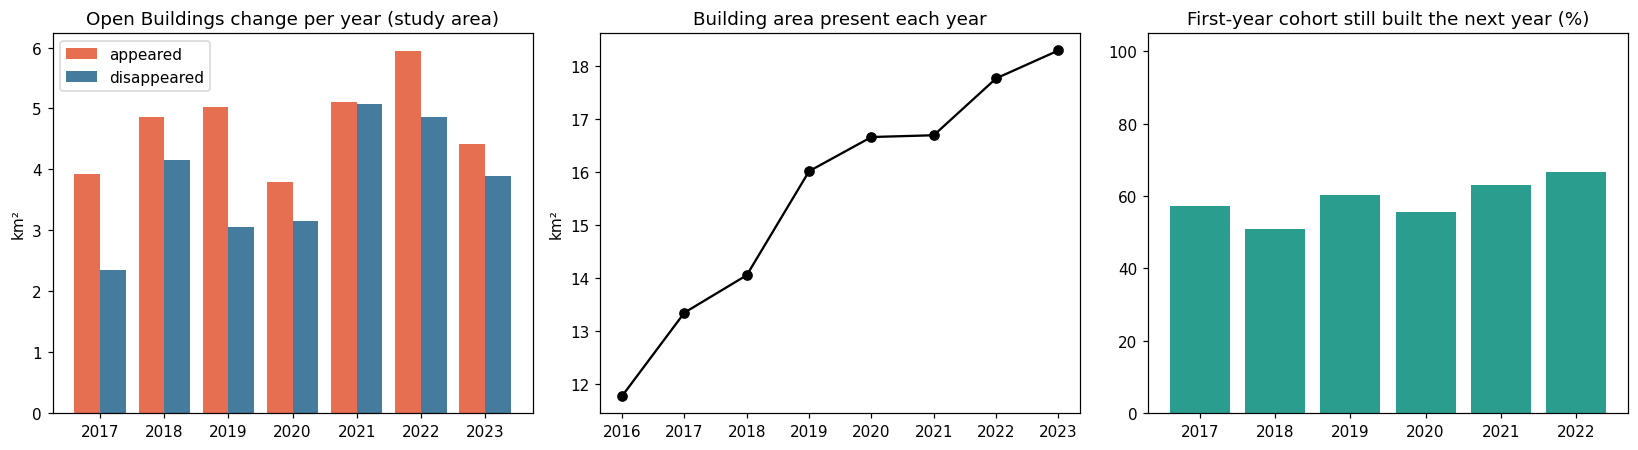

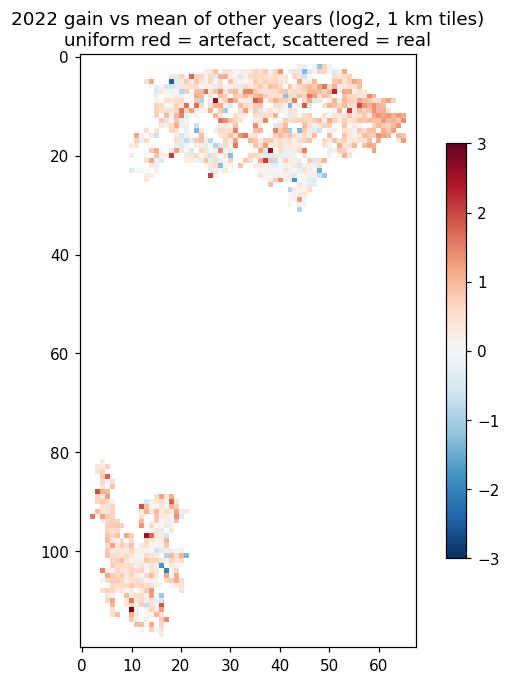


✅ Stage 91 finished in 1.0 min. Saved: ['lab_persist']
   Results are on Google Drive. You can now disconnect; the next stage can run in a new session.


In [ ]:
# ======================= CELL 1A: Open Buildings temporal-stability check =======================
from google.colab import drive
drive.mount('/content/drive')
import os
assert os.path.exists('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py'), 'Run Stage 0 of the staged notebook first.'
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())   # settings + helpers (from Stage 0)
REV = OUT + '/revision'; os.makedirs(REV, exist_ok=True)

# ======================= REVISION 1A: Open Buildings temporal-stability check =======================
begin_stage(91, needs=['GRID', 'H', 'W', 'RES', 'study', 'zone', 'cluster'])
import rasterio
from rasterio.warp import reproject, Resampling

OB_YEARS = list(range(2016, 2024))
OB_THR = 0.30            # same 30 % rule that built OB_first_year (the label layer); 0.50 was used in the first run
stack_files = find_all('OB_built_2016_2023*.tif')
fy_files = find_all('OB_first_year*.tif')
print('Open Buildings stack tiles:', len(stack_files), '| first-year tiles:', len(fy_files))
assert stack_files and fy_files, 'OB_built_2016_2023*.tif or OB_first_year*.tif not found on Drive'

# group code on the 30 m grid: 1 = North outside zone, 2 = South outside zone, 11 = North in zone, 12 = South in zone
grp30 = np.where(study, cluster + 10 * zone.astype(int), 0).astype('int16')
GROUPS = {'Study area': [1, 2, 11, 12], 'Tourism zone': [11, 12], 'Outside zone': [1, 2],
          'North cluster': [1, 11], 'South cluster': [2, 12]}

def onto_tile(arr30, tr, cr, shape):
    out = np.zeros(shape, arr30.dtype)
    reproject(source=arr30, destination=out, src_transform=GRID['transform'], src_crs=GRID['crs'],
              dst_transform=tr, dst_crs=cr, resampling=Resampling.nearest)
    return out

def to30(arr, tr, cr):
    part = np.full((H, W), np.nan, 'float32')
    reproject(source=arr.astype('float32'), destination=part, src_transform=tr, src_crs=cr,
              dst_transform=GRID['transform'], dst_crs=GRID['crs'], dst_nodata=np.nan, resampling=Resampling.average)
    return part

def presence_threshold(src):
    b = src.read(len(OB_YEARS), out_shape=(max(1, src.height // 8), max(1, src.width // 8)))
    mx = float(np.nanmax(b)) if np.isfinite(b).any() else 1.0
    scale = 1.0 if mx <= 1.5 else (100.0 if mx <= 100.5 else 255.0)
    return OB_THR * scale, scale

px10_km2 = None
area = {g: np.zeros(len(OB_YEARS)) for g in GROUPS}            # km² present each year
gain = {g: np.zeros(len(OB_YEARS)) for g in GROUPS}            # appeared vs previous year
loss = {g: np.zeros(len(OB_YEARS)) for g in GROUPS}            # disappeared vs previous year
revert = {g: np.zeros(len(OB_YEARS)) for g in GROUPS}          # appeared in y, gone again in y+1
cohort = {g: np.zeros(len(OB_YEARS)) for g in GROUPS}          # first-year cohort (labels' source)
cohort_kept = {g: np.zeros(len(OB_YEARS)) for g in GROUPS}     # ... still present in 2023
gain30 = {y: np.zeros((H, W), 'float32') for y in OB_YEARS[1:]}
new30 = np.zeros((H, W), 'float32'); kept30 = np.zeros((H, W), 'float32')
conf30 = np.zeros((H, W), 'float32'); newc30 = np.zeros((H, W), 'float32')   # 'confirmed' = present in first year AND the next year
cohort_conf = {g: np.zeros(len(OB_YEARS)) for g in GROUPS}

for path in stack_files:
    with rasterio.open(path) as src:
        tr, cr, shp = src.transform, src.crs, (src.height, src.width)
        thr, scale = presence_threshold(src)
        px10_km2 = abs(tr.a * tr.e) / 1e6
        g10 = onto_tile(grp30, tr, cr, shp)
        gm = {g: np.isin(g10, codes) for g, codes in GROUPS.items()}
        pres = []
        for i, y in enumerate(OB_YEARS):
            b = src.read(i + 1)
            pres.append(np.nan_to_num(b, nan=0) >= thr)
    allfrom = [None] * len(OB_YEARS); allfrom[-1] = pres[-1]
    for i in range(len(OB_YEARS) - 2, -1, -1):
        allfrom[i] = pres[i] & allfrom[i + 1]      # present in year i AND every later year to 2023
    for i, y in enumerate(OB_YEARS):
        for g in GROUPS:
            m = gm[g]
            area[g][i] += (pres[i] & m).sum() * px10_km2
            if i > 0:
                gi = pres[i] & ~pres[i - 1] & m
                gain[g][i] += gi.sum() * px10_km2
                loss[g][i] += (~pres[i] & pres[i - 1] & m).sum() * px10_km2
                if i + 1 < len(OB_YEARS):
                    revert[g][i] += (gi & ~pres[i + 1]).sum() * px10_km2
        if i > 0:
            gain30[y] = np.fmax(gain30[y], np.nan_to_num(to30(pres[i] & ~pres[i - 1] & (g10 > 0), tr, cr), nan=0))
    # first-year cohorts (the layer the labels are built from) and their persistence to 2023
    fy = np.zeros(shp, 'float32')
    for fpath in fy_files:                       # mosaic every first-year tile onto this stack tile
        with rasterio.open(fpath) as fsrc:
            tmp = np.zeros(shp, 'float32')
            reproject(source=np.nan_to_num(fsrc.read(1).astype('float32'), nan=0), destination=tmp, src_transform=fsrc.transform,
                      src_crs=fsrc.crs, dst_transform=tr, dst_crs=cr, dst_nodata=0, resampling=Resampling.nearest)
        fy = np.where(tmp > 0, tmp, fy)
    for i, y in enumerate(OB_YEARS):
        if y < 2017:
            continue
        c = (fy == y) & (g10 > 0)
        for g in GROUPS:
            m = gm[g]
            cohort[g][i] += (c & m).sum() * px10_km2
            cohort_kept[g][i] += (c & m & allfrom[i]).sum() * px10_km2
            if i + 1 < len(OB_YEARS):
                cohort_conf[g][i] += (c & m & pres[i] & pres[i + 1]).sum() * px10_km2
    isnew = (fy >= 2017) & (fy <= 2023) & (g10 > 0)
    new30 = np.fmax(new30, np.nan_to_num(to30(isnew, tr, cr), nan=0))
    conf10 = np.zeros(shp, bool); confirmable = (fy >= 2017) & (fy <= 2022) & (g10 > 0)
    for i, y in enumerate(OB_YEARS):
        if 2017 <= y <= 2022:
            conf10 |= (fy == y) & pres[i] & pres[i + 1]
    conf30 = np.fmax(conf30, np.nan_to_num(to30(conf10 & confirmable, tr, cr), nan=0))
    newc30 = np.fmax(newc30, np.nan_to_num(to30(confirmable, tr, cr), nan=0))
    stable10 = np.zeros(shp, bool)
    for i, y in enumerate(OB_YEARS):
        if y >= 2017:
            stable10 |= (fy == y) & allfrom[i]
    kept30 = np.fmax(kept30, np.nan_to_num(to30(isnew & stable10, tr, cr), nan=0))
    del pres, gm, allfrom, stable10, conf10, confirmable

# ---- annual table ----
rows = []
for g in GROUPS:
    for i, y in enumerate(OB_YEARS):
        rows.append(dict(group=g, year=y, present_km2=area[g][i],
                         change_in_present_pct=(100 * (area[g][i] / area[g][i - 1] - 1) if i > 0 and area[g][i - 1] > 0 else np.nan),
                         gain_km2=gain[g][i] if i else np.nan, loss_km2=loss[g][i] if i else np.nan,
                         loss_to_gain_pct=(100 * loss[g][i] / gain[g][i] if i and gain[g][i] > 0 else np.nan),
                         reverted_next_year_pct=(100 * revert[g][i] / gain[g][i] if 0 < i < len(OB_YEARS) - 1 and gain[g][i] > 0 else np.nan),
                         first_year_cohort_km2=cohort[g][i] if y >= 2017 else np.nan,
                         cohort_confirmed_next_year_pct=(100 * cohort_conf[g][i] / cohort[g][i] if 2017 <= y <= 2022 and cohort[g][i] > 0 else np.nan),
                         cohort_stable_to_2023_pct=(100 * cohort_kept[g][i] / cohort[g][i] if y >= 2017 and cohort[g][i] > 0 else np.nan)))
ann = pd.DataFrame(rows)
ann.to_csv(REV + '/R1A_open_buildings_annual_stability.csv', index=False)
print(ann[ann.group == 'Study area'].round(2).to_string(index=False))

# ---- is the 2022 jump spread evenly (artefact) or clustered (real)? 1 km tiles ----
T = int(round(1000 / RES))
def tiles(a):
    hh, ww = (H // T) * T, (W // T) * T
    return a[:hh, :ww].reshape(H // T, T, W // T, T).sum(axis=(1, 3)) * (RES * RES / 1e6)
st_t = tiles(study.astype('float32')) > 0.5
G = np.stack([tiles(gain30[y]) for y in OB_YEARS[1:]])          # (7 years, tiles)
active = st_t & (G.sum(0) > 0.001)
top_year = np.array(OB_YEARS[1:])[G.argmax(0)][active]
share_top = {int(y): float(100 * (top_year == y).mean()) for y in OB_YEARS[1:]}
other = np.delete(G, OB_YEARS[1:].index(2022), axis=0).mean(0)
ratio22 = np.where(active & (other > 0), G[OB_YEARS[1:].index(2022)] / np.maximum(other, 1e-9), np.nan)
spread = dict(active_tiles=int(active.sum()),
              share_of_tiles_where_year_is_peak_pct=share_top,
              tiles_with_2022_at_least_1p5x_other_years_pct=float(100 * np.nanmean(ratio22[active] >= 1.5)),
              tiles_with_2018_at_least_1p5x_other_years_pct=float(100 * np.nanmean(
                  (G[OB_YEARS[1:].index(2018)] / np.maximum(np.delete(G, OB_YEARS[1:].index(2018), axis=0).mean(0), 1e-9))[active] >= 1.5)))
print('\nWhere is each year the peak year (share of active 1 km tiles, %):', {k: round(v, 1) for k, v in share_top.items()})
print('Tiles where 2022 gain is ≥1.5× the other-year mean: %.1f %% (2018 for comparison: %.1f %%)'
      % (spread['tiles_with_2022_at_least_1p5x_other_years_pct'], spread['tiles_with_2018_at_least_1p5x_other_years_pct']))

# ---- tourism-zone contrast with persistent buildings only (robustness of the 2.3× result) ----
def zone_contrast(a):
    zin, zall = np.nansum(a[zone & study]), np.nansum(a[study])
    zsh = zone[study].mean()
    return dict(new_km2=zall * RES * RES / 1e6, zone_share_pct=100 * zin / zall, zone_area_pct=100 * zsh,
                density_ratio=(zin / zsh) / ((zall - zin) / (1 - zsh)))
contrast = dict(all_new=zone_contrast(new30), stable_to_2023=zone_contrast(kept30),
                confirmable_2017_2022=zone_contrast(newc30), confirmed_next_year=zone_contrast(conf30))
# used by cell 1B: share of a pixel's new 10 m cells confirmed the next year (comparable for every cohort 2017-2022;
# the 2023 cohort cannot be confirmed and counts as unconfirmed)
lab_persist = np.where(new30 > 0, conf30 / np.maximum(new30, 1e-9), np.nan).astype('float32')
print('\nTourism-zone contrast, all new buildings :', {k: round(v, 3) for k, v in contrast['all_new'].items()})
print('Tourism-zone contrast, stable to 2023 only:', {k: round(v, 3) for k, v in contrast['stable_to_2023'].items()})
print('Tourism-zone contrast, confirmed next yr  :', {k: round(v, 3) for k, v in contrast['confirmed_next_year'].items()})
ss = ann[ann.group == 'Study area'].set_index('year')
print(f"\nSum of first-year cohorts 2017-2023: {ss.first_year_cohort_km2.sum():.2f} km²  |  net change in present area 2016->2023: {ss.present_km2[2023] - ss.present_km2[2016]:.2f} km²  |  stable new: {contrast['stable_to_2023']['new_km2']:.2f} km²  |  confirmed next year (2017-2022 cohorts): {contrast['confirmed_next_year']['new_km2']:.2f} of {contrast['confirmable_2017_2022']['new_km2']:.2f} km²")

# ---- figure ----
s = ann[ann.group == 'Study area'].set_index('year')
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
yrs = OB_YEARS[1:]
axs[0].bar([y - 0.2 for y in yrs], s.loc[yrs, 'gain_km2'], 0.4, label='appeared', color='#e76f51')
axs[0].bar([y + 0.2 for y in yrs], s.loc[yrs, 'loss_km2'], 0.4, label='disappeared', color='#457b9d')
axs[0].set_title('Open Buildings change per year (study area)'); axs[0].set_ylabel('km²'); axs[0].legend()
axs[1].plot(OB_YEARS, s['present_km2'], 'o-', color='black'); axs[1].set_title('Building area present each year'); axs[1].set_ylabel('km²')
axs[2].bar(yrs, s.loc[yrs, 'cohort_confirmed_next_year_pct'], color='#2a9d8f'); axs[2].set_ylim(0, 105)
axs[2].set_title('First-year cohort still built the next year (%)')
fig.tight_layout(); fig.savefig(REV + '/R1A_open_buildings_stability.png', dpi=200); plt.show()
fig, ax = plt.subplots(figsize=(7, 7))
im = ax.imshow(np.log2(np.where(active, ratio22, np.nan)), cmap='RdBu_r', vmin=-3, vmax=3)
ax.set_title('2022 gain vs mean of other years (log2, 1 km tiles)\nuniform red = artefact, scattered = real'); plt.colorbar(im, ax=ax, shrink=0.7)
fig.savefig(REV + '/R1A_2022_jump_map.png', dpi=200); plt.show()

RESULTS['label_check'] = dict(presence_threshold_fraction=OB_THR, presence_threshold=thr, scale=scale,
    annual=ann[ann.group == 'Study area'].round(4).to_dict('records'),
    jump_2021_2022_pct=float(s.loc[2022, 'change_in_present_pct']), spread_1km=spread, zone_contrast=contrast)
end_stage(91, exports=['lab_persist'])


### Cell 1B – Automatic screen and manual-check sample (Earth Engine)
1,200 stratified points are screened with independent evidence (Sentinel-2 NDBI/NDVI change and Dynamic World built probability). A stratified sample of 100 points (30 confirmed positives, 30 flicker positives, 25 negatives near and 15 far from settlement) is written for the manual check. Set `GEE_PROJECT` first.

**In the paper:** Section 4.2; Supplementary Table S3.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
assert os.path.exists('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py'), 'Run Stage 0 of the staged notebook first.'
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())   # settings + helpers (from Stage 0)
REV = OUT + '/revision'; os.makedirs(REV, exist_ok=True)

# ======================= REVISION 1B: automatic screening + manual-check sample =======================
GEE_PROJECT = 'YOUR-GEE-PROJECT'  # e.g. 'ee-yourname' (the Cloud project you use in the GEE Code Editor)
N_POS_STABLE, N_POS_FLICKER, N_NEG_NEAR, N_NEG_FAR = 75, 75, 100, 50   # per period x cluster (4 cells) -> 1,200 points
# manual check: stratified random sample (unbiased), ~100 points in total
N_MANUAL = {'pos_stable': 30, 'pos_flicker': 30, 'neg_near': 25, 'neg_far': 15}

begin_stage(92, needs=['GRID', 'H', 'W', 'RES', 'study', 'cluster', 'zone', 'labA', 'labB', 'eligA', 'eligB', 'built', 'lab_persist'])
import ee
from pyproj import Transformer
try:
    ee.Initialize(project=GEE_PROJECT)
except Exception:
    ee.Authenticate(); ee.Initialize(project=GEE_PROJECT)

PER = {'A': dict(lab=labA, elig=eligA, start=2016, end=2020, before=('2015-11-01', '2016-04-30'), after=('2020-11-01', '2021-04-30')),
       'B': dict(lab=labB, elig=eligB, start=2020, end=2023, before=('2019-11-01', '2020-04-30'), after=('2023-11-01', '2024-04-30'))}

# ---- 1. stratified sample of 30 m pixels ----
tr = GRID['transform']; to_ll = Transformer.from_crs(GRID['crs'], 'EPSG:4326', always_xy=True)
rows = []
for p, P in PER.items():
    dens = ndimage.uniform_filter((np.nan_to_num(built[P['start']]) > 0).astype('float32'), size=17)   # ~500 m
    for cl, cname in [(1, 'North'), (2, 'South')]:
        m = study & (cluster == cl)
        st_ = np.nan_to_num(lab_persist, nan=0) >= 0.5        # most of the pixel's new 10 m cells are still built the next year
        strata = {'pos_stable': P['lab'] & m & st_, 'pos_flicker': P['lab'] & m & ~st_, 'neg_near': P['elig'] & ~P['lab'] & m & (dens > 0.02), 'neg_far': P['elig'] & ~P['lab'] & m & (dens <= 0.02)}
        for sname, n in [('pos_stable', N_POS_STABLE), ('pos_flicker', N_POS_FLICKER), ('neg_near', N_NEG_NEAR), ('neg_far', N_NEG_FAR)]:
            idx = np.flatnonzero(strata[sname]); N_pop = idx.size
            pick = rng.choice(idx, size=min(n, N_pop), replace=False)
            r_, c_ = np.unravel_index(pick, (H, W))
            x = tr.c + (c_ + 0.5) * tr.a; y = tr.f + (r_ + 0.5) * tr.e
            lon, lat = to_ll.transform(x, y)
            for k in range(pick.size):
                rows.append(dict(period=p, cluster=cname, stratum=sname, N_stratum=N_pop, row=int(r_[k]), col=int(c_[k]),
                                 x=float(x[k]), y=float(y[k]), lon=float(lon[k]), lat=float(lat[k]),
                                 label=int(sname.startswith('pos')), in_zone=bool(zone[r_[k], c_[k]]),
                                 ob_persist=float(lab_persist[r_[k], c_[k]]) if np.isfinite(lab_persist[r_[k], c_[k]]) else np.nan))
pts = pd.DataFrame(rows)
pts.insert(0, 'id', [f'P{i:04d}' for i in range(len(pts))])
print(pts.groupby(['period', 'cluster', 'stratum']).size().unstack())

# ---- 2. independent evidence from Earth Engine (Sentinel-2 + Dynamic World), 30 m square around each point ----
CSP = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED')
def s2_comp(d0, d1, region):
    col = (ee.ImageCollection('COPERNICUS/S2_HARMONIZED').filterBounds(region).filterDate(d0, d1)
           .linkCollection(CSP, ['cs_cdf']).map(lambda im: im.updateMask(im.select('cs_cdf').gte(0.6))))
    med = col.median()
    return ee.Image.cat(med.normalizedDifference(['B11', 'B8']).rename('ndbi'), med.normalizedDifference(['B8', 'B4']).rename('ndvi'))
def dw_comp(d0, d1, region):
    return ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1').filterBounds(region).filterDate(d0, d1).select('built').mean().rename('dw')

out = []
for p, P in PER.items():
    sub = pts[pts.period == p]
    feats = [ee.Feature(ee.Geometry.Point([r.lon, r.lat]).buffer(15).bounds(), {'id': r.id}) for r in sub.itertuples()]
    fc = ee.FeatureCollection(feats); region = fc.geometry().bounds()
    img = ee.Image.cat(s2_comp(*P['before'], region).rename(['ndbi_b', 'ndvi_b']), s2_comp(*P['after'], region).rename(['ndbi_a', 'ndvi_a']),
                       dw_comp(*P['before'], region).rename('dw_b'), dw_comp(*P['after'], region).rename('dw_a'))
    for i0 in range(0, len(feats), 300):
        res = img.reduceRegions(collection=ee.FeatureCollection(feats[i0:i0 + 300]), reducer=ee.Reducer.mean(), scale=10).getInfo()
        out += [f['properties'] for f in res['features']]
    print(f'Period {p}: Earth Engine values for {len(sub)} points')
ev = pd.DataFrame(out)
pts = pts.merge(ev, on='id', how='left')
for c in ['ndbi_b', 'ndvi_b', 'ndbi_a', 'ndvi_a', 'dw_b', 'dw_a']:
    if c not in pts:
        pts[c] = np.nan          # no clear image in that window
pts['d_dw'] = pts.dw_a - pts.dw_b; pts['d_ndbi'] = pts.ndbi_a - pts.ndbi_b; pts['d_ndvi'] = pts.ndvi_a - pts.ndvi_b

# ---- 3. transparent screening rule (two independent votes + Open Buildings persistence) ----
yes_dw = pts.d_dw >= 0.15;               no_dw = pts.d_dw < 0.05
yes_s2 = (pts.d_ndbi >= 0.05) & (pts.d_ndvi <= -0.05); no_s2 = (pts.d_ndbi < 0.02) & (pts.d_ndvi > -0.03)
persist_ok = pts.ob_persist.isna() | (pts.ob_persist >= 0.7)
pts['auto'] = np.where(yes_dw & yes_s2 & persist_ok, 'clear_yes', np.where(no_dw & no_s2, 'clear_no', 'uncertain'))
pts.loc[pts[['d_dw', 'd_ndbi']].isna().any(axis=1), 'auto'] = 'uncertain'
tab = pd.crosstab([pts.period, pts.stratum], pts.auto)
print('\nAutomatic screening (rows = Open Buildings label stratum):'); print(tab)

# ---- 4. manual-check sample: stratified random (stable labels, flickering labels, negatives) ----
man = pd.concat([pts[pts.stratum == k].sample(n=min(n, (pts.stratum == k).sum()), random_state=SEED) for k, n in N_MANUAL.items()])
man = man.sample(frac=1, random_state=SEED)          # shuffle so the checker cannot guess the group
pts['manual'] = pts.id.isin(man.id)
pts.to_csv(REV + '/R1B_screening_key.csv', index=False)    # KEY: labels + automatic class (do not look at it while checking)
blind = man[['id', 'lat', 'lon', 'period']].copy()
blind['year_from'] = blind.period.map({p: PER[p]['start'] for p in PER}); blind['year_to'] = blind.period.map({p: PER[p]['end'] for p in PER})
blind = blind.drop(columns='period'); blind[['lat', 'lon']] = blind[['lat', 'lon']].round(6)
blind.to_csv(REV + '/manual_check_points.csv', index=False)

# KML with the 30 m square of each point (for Google Earth Pro: open, then use the historical-imagery clock)
to_utm = Transformer.from_crs('EPSG:4326', GRID['crs'], always_xy=True)
kml = ['<?xml version="1.0" encoding="UTF-8"?><kml xmlns="http://www.opengis.net/kml/2.2"><Document><name>Sylhet manual check</name>',
       '<Style id="sq"><LineStyle><color>ff00ffff</color><width>2</width></LineStyle><PolyStyle><fill>0</fill></PolyStyle></Style>']
for r in blind.itertuples():
    x, y = to_utm.transform(r.lon, r.lat)
    cs = [to_ll.transform(x + dx, y + dy) for dx, dy in [(-15, -15), (15, -15), (15, 15), (-15, 15), (-15, -15)]]
    coords = ' '.join(f'{a:.7f},{b:.7f},0' for a, b in cs)
    kml.append(f'<Placemark><name>{r.id}</name><description>New building inside the square between {r.year_from} and {r.year_to}?</description>'
               f'<styleUrl>#sq</styleUrl><Polygon><outerBoundaryIs><LinearRing><coordinates>{coords}</coordinates></LinearRing></outerBoundaryIs></Polygon></Placemark>')
kml.append('</Document></kml>')
open(REV + '/manual_check_points.kml', 'w').write('\n'.join(kml))

RESULTS['label_screen'] = dict(n_points=int(len(pts)), rule=dict(yes='d_dw>=0.15 & d_ndbi>=0.05 & d_ndvi<=-0.05 & OB persistence>=0.7',
                               no='d_dw<0.05 & d_ndbi<0.02 & d_ndvi>-0.03'), crosstab=tab.reset_index().to_dict('records'),
                               n_manual=int(len(man)))
print(f'\n✅ {len(man)} points to check: download  Sylhet_outputs/revision/manual_check_points.csv  (and .kml)')
print('   Open them in the review page, answer each point, then save manual_answers.csv into Sylhet_outputs/revision/.')
end_stage(92, exports=[])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 13.6 GB | CPUs: 2
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 528 files in Drive
Stage 92: loaded 13 saved results from earlier stages.
stratum         neg_far  neg_near  pos_flicker  pos_stable
period cluster                                            
A      North         50       100           75          75
       South         50       100           75          75
B      North         50       100           75          75
       South         50       100           75          75
Period A: Earth Engine values for 600 points
Period B: Earth Engine values for 600 points

Automatic screening (rows = Open Buildings label stratum):
auto                clear_no  clear_yes  uncertain
period stratum                                    
A      neg_far            68          0         3

### Cell 1M – Manual check against dated very-high-resolution imagery (interactive)
Shows each sample point on dated Esri World Imagery Wayback releases from before and after the period; the interpreter answers *Yes / No / Can't tell*. Answers are saved to `revision/manual_answers.csv`. Imagery is cached on Drive. (The interactive widget is not shown in this saved copy.)

In [ ]:
# ======================= CELL 1M: manual check of the label sample against dated imagery =======================
# Step 1 downloads ALL pictures once (with a progress bar) and keeps them on Drive.
# Step 2 shows them instantly: click Yes / No / Can't tell, the next point appears at once.
from google.colab import drive
drive.mount('/content/drive')
import os
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())
REV = OUT + '/revision'; os.makedirs(REV, exist_ok=True)

import re, io, json, math, logging, requests, concurrent.futures as cf
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from PIL import Image, ImageDraw
import ipywidgets as w
from IPython.display import display
from tqdm.auto import tqdm
logging.getLogger('urllib3').setLevel(logging.ERROR)

Z, HALF, SHOW_PX = 18, 128, 380            # zoom 18 (~0.55 m/pixel); 256 px picture ≈ 140 m wide
PTS_FILE, ANS_FILE = REV + '/manual_check_points.csv', REV + '/manual_answers.csv'
CACHE_DIR = REV + '/imagery_cache'; os.makedirs(CACHE_DIR, exist_ok=True)
INDEX = CACHE_DIR + '/index.json'
pts = pd.read_csv(PTS_FILE)
answers = pd.read_csv(ANS_FILE).fillna('').set_index('id').to_dict('index') if os.path.exists(ANS_FILE) else {}
index = json.load(open(INDEX)) if os.path.exists(INDEX) else {}

S = requests.Session(); S.headers['User-Agent'] = 'Mozilla/5.0 (academic land-change label check)'
S.mount('https://', HTTPAdapter(pool_maxsize=100, max_retries=Retry(total=3, backoff_factor=0.5, status_forcelist=[429, 500, 502, 503, 504])))

cfg = S.get('https://s3-us-west-2.amazonaws.com/config.maptiles.arcgis.com/waybackconfig.json', timeout=60).json()
REL = {}
for k, v in cfg.items():
    m = re.search(r'(\d{4}-\d{2}-\d{2})', v.get('itemTitle', '') or v.get('title', ''))
    REL[int(k)] = dict(url=v['itemURL'], date=m.group(1) if m else '', meta=v.get('metadataLayerUrl', ''))
# check only every 4th release (plus the newest): enough to find each distinct image, 4x fewer requests
REL_CHECK = sorted(REL, key=lambda r: REL[r]['date'])
REL_CHECK = REL_CHECK[::4] + [REL_CHECK[-1]]

def tile_xy(lat, lon):
    n = 2 ** Z
    return ((lon + 180) / 360 * n,
            (1 - math.log(math.tan(math.radians(lat)) + 1 / math.cos(math.radians(lat))) / math.pi) / 2 * n)

def jget(url, **kw):
    try:
        return S.get(url, timeout=20, **kw).json()
    except Exception:
        return {}

def capture_date(r, lat, lon):
    base = REL[r]['meta']
    for lid in (5, 4, 6, 3, 7):
        j = jget(f'{base}/{lid}/query', params=dict(f='json', where='1=1', outFields='SRC_DATE2,SRC_DATE', geometry=f'{lon},{lat}',
                 geometryType='esriGeometryPoint', inSR=4326, spatialRel='esriSpatialRelIntersects', returnGeometry='false')) if base else {}
        fs = j.get('features') or []
        if fs:
            a = fs[0]['attributes']
            if a.get('SRC_DATE2'): return pd.to_datetime(a['SRC_DATE2'], unit='ms').strftime('%Y-%m-%d')
            if a.get('SRC_DATE'):  s_ = str(a['SRC_DATE']); return f'{s_[:4]}-{s_[4:6]}-{s_[6:8]}'
    return REL[r]['date']

def picture(r, lat, lon, path):
    x, y = tile_xy(lat, lon)
    c0, r0 = int(x - 0.5), int(y - 0.5)                 # the 2 x 2 tiles that surround the point
    big = Image.new('RGB', (512, 512), (70, 70, 70))
    for dx in (0, 1):
        for dy in (0, 1):
            try:
                b = S.get(REL[r]['url'].format(level=Z, row=r0 + dy, col=c0 + dx), timeout=20).content
                big.paste(Image.open(io.BytesIO(b)).convert('RGB'), (dx * 256, dy * 256))
            except Exception:
                pass
    px, py = (x - c0) * 256, (y - r0) * 256
    im = big.crop((int(px - HALF), int(py - HALF), int(px + HALF), int(py + HALF)))
    s = 15 / (156543.03392 * math.cos(math.radians(lat)) / 2 ** Z)
    ImageDraw.Draw(im).rectangle([HALF - s, HALF - s, HALF + s, HALF + s], outline=(255, 230, 0), width=3)
    im.save(path, 'PNG')

def fetch_point(row):
    pid, lat, lon, y0, y1 = row.id, row.lat, row.lon, row.year_from, row.year_to
    x, y = tile_xy(lat, lon)
    def tm(r):
        j = jget(f'https://wayback.maptiles.arcgis.com/arcgis/rest/services/World_Imagery/MapServer/tilemap/{r}/{Z}/{int(y)}/{int(x)}')
        return (j.get('select') or [r])[0] if j.get('data', [0])[0] == 1 else None
    with cf.ThreadPoolExecutor(16) as ex:
        rels = sorted({s for s in ex.map(tm, REL_CHECK) if s in REL}, key=lambda r: REL[r]['date'])
    with cf.ThreadPoolExecutor(8) as ex:
        dated = sorted(zip(ex.map(lambda r: capture_date(r, lat, lon), rels), rels))
    yr = lambda d: int(d[:4])
    keep = [it for it in dated if yr(it[0]) <= y0][-2:] + [it for it in dated if y0 < yr(it[0]) < y1][:1] + [it for it in dated if yr(it[0]) >= y1][:2]
    keep = keep or dated[:4]
    out = []
    for k, (d, r) in enumerate(keep):
        path = f'{CACHE_DIR}/{pid}_{k}.png'; picture(r, lat, lon, path); out.append([d, path])
    return pid, out

# ---------- STEP 1: download everything once (skips points already in the cache) ----------
todo = [r for r in pts.itertuples() if r.id not in index and not answers.get(r.id, {}).get('answer')]   # skip answered points
if todo:
    print(f'Downloading pictures for {len(todo)} points (about 3–6 minutes, only the first time)…')
    with cf.ThreadPoolExecutor(8) as ex:
        for pid, out in tqdm(ex.map(fetch_point, todo), total=len(todo)):
            index[pid] = out
            json.dump(index, open(INDEX, 'w'))
print(f'Pictures ready. {sum(1 for k in pts.id if answers.get(k, {}).get("answer"))} of {len(pts)} points already answered.')

# ---------- STEP 2: answer (instant, everything is on Drive) ----------
png_cache = {}
def png(path):
    if path not in png_cache:
        png_cache[path] = open(path, 'rb').read()
    return png_cache[path]

def save_answers():
    pd.DataFrame([dict(id=k, answer=v.get('answer', ''), note=v.get('note', '')) for k, v in answers.items()]).to_csv(ANS_FILE, index=False)

def next_open(start):
    for k in list(range(start, len(pts))) + list(range(0, start)):
        if not answers.get(pts.id.iloc[k], {}).get('answer'):
            return k
    return None

head, gallery, note = w.HTML(), w.GridBox(layout=w.Layout(grid_template_columns=f'repeat(4, {SHOW_PX + 8}px)', grid_gap='6px')), w.Text(placeholder='optional note', layout=w.Layout(width='560px'))
state = {'i': 0}

def show(i):
    state['i'] = i; p = pts.iloc[i]
    done = sum(1 for k in pts.id if answers.get(k, {}).get('answer'))
    head.value = (f"<h3 style='margin:4px 0'>Point {p.id} · {i + 1} of {len(pts)} · answered {done}</h3>"
                  f"<div style='font-size:15px'>Did a <b>new building</b> appear inside the <b style='color:#c9a800'>yellow square</b> "
                  f"between <b>{p.year_from}</b> and <b>{p.year_to}</b>?</div>")
    cards = []
    for d, path in index.get(p.id, []):
        tag = 'BEFORE' if int(d[:4]) <= p.year_from else ('AFTER' if int(d[:4]) >= p.year_to else 'DURING')
        col = {'BEFORE': '#1f6f9c', 'DURING': '#777', 'AFTER': '#c1440e'}[tag]
        cards.append(w.VBox([w.HTML(f"<b style='color:{col}'>{tag}</b> {d}"), w.Image(value=png(path), format='png', width=SHOW_PX, height=SHOW_PX)]))
    gallery.children = cards or [w.HTML('<b>No high-resolution picture here.</b> Choose Can&#39;t tell.')]
    note.value = answers.get(p.id, {}).get('note', '')

def answer(a):
    pid = pts.id.iloc[state['i']]
    answers[pid] = dict(answer=a, note=note.value); save_answers()
    nxt = next_open(state['i'] + 1)
    if nxt is None:
        head.value = f"<h3>✅ All {len(pts)} points answered.</h3>Saved to <code>{ANS_FILE}</code>. Now run Cell 1C."
        gallery.children = []
    else:
        show(nxt)

buttons = []
for label, a, style in [('Yes, new building', 'yes', 'success'), ('No new building', 'no', 'danger'), ("Can't tell", 'cant_tell', 'warning')]:
    b = w.Button(description=label, button_style=style, layout=w.Layout(width='190px', height='44px'))
    b.on_click(lambda _, a=a: answer(a)); buttons.append(b)
back = w.Button(description='← Back', layout=w.Layout(width='110px')); back.on_click(lambda _: show(max(0, state['i'] - 1)))
skip = w.Button(description='Skip →', layout=w.Layout(width='110px')); skip.on_click(lambda _: show(min(len(pts) - 1, state['i'] + 1)))

display(w.VBox([head, gallery, w.HBox(buttons), note, w.HBox([back, skip])]))
start = next_open(0)
if start is None:
    head.value = '<h3>✅ All points already answered.</h3>Run Cell 1C.'
else:
    show(start)

### Cell 1C – Label precision and omission
Precision of the labels by stratum, omission near and far from settlement, agreement of the automatic screen, and precision inside versus outside the tourism zone.

**In the paper:** Table 3. The design-based interval for overall precision (0.49–0.75) is computed from these stratum results as described in Supplementary Section S2.3.

In [ ]:
# ======================= CELL 1C: label precision and omission from the manual check =======================
from google.colab import drive
drive.mount('/content/drive')
import os
assert os.path.exists('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py'), 'Run Stage 0 of the staged notebook first.'
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())   # settings + helpers (from Stage 0)
REV = OUT + '/revision'; os.makedirs(REV, exist_ok=True)

# ======================= REVISION 1C: results of the manual check =======================
begin_stage(93, needs=['study'])
key = pd.read_csv(REV + '/R1B_screening_key.csv')
ans = pd.read_csv(REV + '/manual_answers.csv')          # columns: id, answer (yes / no / cant_tell), note
ans['answer'] = ans.answer.astype(str).str.strip().str.lower()
d = key.merge(ans[['id', 'answer']], on='id', how='inner')
print(f'{len(d)} points answered; "can\'t tell": {(d.answer == "cant_tell").sum()}')
d = d[d.answer.isin(['yes', 'no'])].copy(); d['truth'] = (d.answer == 'yes').astype(int)

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan, np.nan)
    p = k / n; den = 1 + z * z / n; c = (p + z * z / (2 * n)) / den; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (p, c - h, c + h)

rows = []
for s_ in ['pos_stable', 'pos_flicker', 'neg_near', 'neg_far']:
    sub = d[d.stratum == s_]; p, lo, hi = wilson(sub.truth.sum(), len(sub))
    rows.append(dict(stratum=s_, n=len(sub), share_real_new_building=p, ci_low=lo, ci_high=hi,
                     meaning='precision' if s_.startswith('pos') else 'omission (missed construction)'))
val = pd.DataFrame(rows); print('\nManual check by stratum (Wilson 95 % CI):'); print(val.round(3).to_string(index=False))

# overall precision of the CURRENT labels = stable and flickering labels weighted by their population size
pop = key.drop_duplicates(['period', 'cluster', 'stratum']).groupby('stratum').N_stratum.sum()
w_st = pop.get('pos_stable', 0) / (pop.get('pos_stable', 0) + pop.get('pos_flicker', 0))
p_st = val.set_index('stratum').share_real_new_building
overall_current = float(w_st * p_st['pos_stable'] + (1 - w_st) * p_st['pos_flicker'])
print(f'\nShare of current label pixels that are stable: {100 * w_st:.1f} %')
print(f'Precision of CURRENT labels (all positives): {overall_current:.3f}  |  stable-only labels: {p_st["pos_stable"]:.3f}')

# is label quality different inside vs outside the tourism zone? (would bias the zone contrast)
inz = d[d.stratum.str.startswith('pos')].groupby('in_zone').truth.agg(['mean', 'size'])
print('\nPrecision inside vs outside the tourism zone:'); print(inz.round(3))

# how good is the automatic screen? (it runs on all 1,200 points; manual answers are the reference)
cm = pd.crosstab(d.auto, d.answer); print('\nAutomatic screen vs manual answer:'); print(cm)
clear = d[d.auto != 'uncertain']
screen_acc = float(((clear.auto == 'clear_yes') == (clear.truth == 1)).mean()) if len(clear) else np.nan
print(f'Accuracy of the automatic screen on its clear calls: {screen_acc:.3f} (n = {len(clear)}); share uncertain: {(key.auto == "uncertain").mean():.2f}')

val.to_csv(REV + '/R1C_label_validation.csv', index=False)
RESULTS['label_validation'] = dict(n_answered=int(len(d)), by_stratum=val.round(4).to_dict('records'),
    share_labels_stable=round(float(w_st), 4), precision_current_labels=round(overall_current, 4),
    precision_stable_labels=round(float(p_st['pos_stable']), 4),
    precision_in_vs_out_zone=inz['mean'].round(4).to_dict(), screen_accuracy_on_clear=round(screen_acc, 4),
    auto_vs_manual=cm.to_dict())
end_stage(93, exports=[])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 56.9 GB | CPUs: 12
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 372 files in Drive
Stage 93: loaded 1 saved results from earlier stages.
100 points answered; "can't tell": 0

Manual check by stratum (Wilson 95 % CI):
    stratum  n  share_real_new_building  ci_low  ci_high                        meaning
 pos_stable 30                    0.633   0.455    0.781                      precision
pos_flicker 30                    0.600   0.423    0.754                      precision
   neg_near 25                    0.120   0.042    0.300 omission (missed construction)
    neg_far 15                    0.000  -0.000    0.204 omission (missed construction)

Share of current label pixels that are stable: 66.4 %
Precision of CURRENT labels (all positives): 0.622  |  stable-only labels: 0.633

## B2 – Time-matched predictors
### Cell 2A – OpenStreetMap as it was on 1 January 2016, 2020 and 2023
Builds distance to any road, distance to main road, tourism-facility density and distance to the nearest facility for each year from the Geofabrik historical extracts, and compares them with the 2026 network.

**In the paper:** Section 4.3; Supplementary Table S5.

In [ ]:
# ======================= CELL 2A: time-matched OpenStreetMap (roads + tourism facilities) =======================
# Downloads the Geofabrik Bangladesh extracts of 1 Jan 2016, 2020 and 2023 and builds, for each year:
# distance to any road, distance to main road, tourism-facility density (1 km) and distance to the nearest facility.
from google.colab import drive
drive.mount('/content/drive')
import os, sys, subprocess
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())
REV = OUT + '/revision'; os.makedirs(REV, exist_ok=True)
try:
    import osmium
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'osmium'], check=True); import osmium
import requests
from pyproj import Transformer
from shapely.geometry import LineString
begin_stage(94, needs=['GRID', 'H', 'W', 'RES', 'study'])

YEARS = {2016: '160101', 2020: '200101', 2023: '230101'}      # predictors at the start of Period A, Period B, projection
MAIN = {'motorway', 'trunk', 'primary', 'secondary', 'motorway_link', 'trunk_link', 'primary_link', 'secondary_link'}
SKIP = {'footway', 'path', 'steps', 'pedestrian', 'cycleway', 'bridleway', 'corridor', 'proposed', 'construction',
        'platform', 'elevator', 'raceway', 'bus_stop', 'abandoned', 'razed'}
TOUR_T = {'hotel', 'guest_house', 'motel', 'hostel', 'resort', 'chalet', 'camp_site', 'apartment', 'attraction', 'viewpoint', 'picnic_site', 'theme_park'}
TOUR_A = {'restaurant', 'cafe', 'fast_food', 'food_court'}

tr = GRID['transform']
to_ll = Transformer.from_crs(GRID['crs'], 'EPSG:4326', always_xy=True)
to_utm = Transformer.from_crs('EPSG:4326', GRID['crs'], always_xy=True)
xs, ys = [tr.c, tr.c + W * tr.a], [tr.f, tr.f + H * tr.e]
(lo0, la0), (lo1, la1) = to_ll.transform(min(xs), min(ys)), to_ll.transform(max(xs), max(ys))
BBOX = (lo0 - 0.02, la0 - 0.02, lo1 + 0.02, la1 + 0.02)

class Grab(osmium.SimpleHandler):
    def __init__(self):
        super().__init__(); self.any, self.main, self.poi = [], [], []
    def inside(self, lon, lat):
        return BBOX[0] <= lon <= BBOX[2] and BBOX[1] <= lat <= BBOX[3]
    def node(self, n):
        if (n.tags.get('tourism') in TOUR_T or n.tags.get('amenity') in TOUR_A) and n.location.valid() and self.inside(n.location.lon, n.location.lat):
            self.poi.append((n.location.lon, n.location.lat))
    def way(self, wy):
        hw, t, a = wy.tags.get('highway'), wy.tags.get('tourism'), wy.tags.get('amenity')
        is_poi = t in TOUR_T or a in TOUR_A
        if not (hw and hw not in SKIP) and not is_poi:
            return
        try:
            pts = [(nd.lon, nd.lat) for nd in wy.nodes]
        except Exception:
            return
        if not pts or not any(self.inside(*p) for p in pts):
            return
        if is_poi:
            self.poi.append((sum(p[0] for p in pts) / len(pts), sum(p[1] for p in pts) / len(pts)))
        if hw and hw not in SKIP and len(pts) > 1:
            self.any.append(LineString(pts))
            if hw in MAIN:
                self.main.append(LineString(pts))

def lines_to_mask(lines):
    if not lines:
        return np.zeros((H, W), 'int32')
    g = gpd.GeoDataFrame(geometry=lines, crs='EPSG:4326').to_crs(GRID['crs'])
    return burn(g)

osm_hist, summary = {}, []
for year, tag in YEARS.items():
    path = f'/content/bangladesh-{tag}.osm.pbf'
    if not os.path.exists(path):
        url = f'https://download.geofabrik.de/asia/bangladesh-{tag}.osm.pbf'
        print('Downloading', url)
        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(path, 'wb') as fh:
                for chunk in r.iter_content(1 << 22):
                    fh.write(chunk)
    h = Grab(); h.apply_file(path, locations=True, idx='flex_mem')
    any_m, main_m = lines_to_mask(h.any), lines_to_mask(h.main)
    count = np.zeros((H, W), 'float32')
    if h.poi:
        px, py = to_utm.transform([p[0] for p in h.poi], [p[1] for p in h.poi])
        cc = ((np.array(px) - tr.c) / tr.a).astype(int); rr = ((np.array(py) - tr.f) / tr.e).astype(int)
        ok = (rr >= 0) & (rr < H) & (cc >= 0) & (cc < W)
        np.add.at(count, (rr[ok], cc[ok]), 1)
    k = int(round(1000 / RES)) | 1
    dens = np.log1p(ndimage.uniform_filter(count, size=k) * k * k).astype('float32')
    osm_hist[year] = dict(dist_any_road=dist_to(any_m), dist_main_road=dist_to(main_m),
                          tour_facility_density=dens, dist_tour_facility=dist_to(count > 0))
    summary.append(dict(year=year, road_pixels_in_study=int((any_m > 0)[study].sum()), main_road_pixels_in_study=int((main_m > 0)[study].sum()),
                        tourism_facilities_in_study=int(count[study].sum()), tourism_facilities_in_grid=int(count.sum())))
    print(summary[-1])

summ = pd.DataFrame(summary)
summ.to_csv(REV + '/R2A_osm_history_summary.csv', index=False)
st = joblib.load(f'{STATE}/static.joblib')
for y in YEARS:
    d = np.abs(osm_hist[y]['dist_any_road'] - st['dist_any_road'])[study]
    print(f'{y}: mean |difference| in distance-to-road vs the 2026 extract = {np.nanmean(d):.0f} m (median {np.nanmedian(d):.0f} m)')
RESULTS['osm_history'] = summ.to_dict('records')
end_stage(94, exports=['osm_hist'])

Mounted at /content/drive
Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 56.9 GB | CPUs: 12
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 372 files in Drive
Stage 94: loaded 5 saved results from earlier stages.
{'year': 2016, 'road_pixels_in_study': 7079, 'main_road_pixels_in_study': 3883, 'tourism_facilities_in_study': 4, 'tourism_facilities_in_grid': 18}
{'year': 2020, 'road_pixels_in_study': 33095, 'main_road_pixels_in_study': 4078, 'tourism_facilities_in_study': 39, 'tourism_facilities_in_grid': 208}
{'year': 2023, 'road_pixels_in_study': 133697, 'main_road_pixels_in_study': 6175, 'tourism_facilities_in_study': 43, 'tourism_facilities_in_grid': 253}
2016: mean |difference| in distance-to-road vs the 2026 extract = 2829 m (median 2262 m)
2020: mean |difference| in distance-to-road vs the 2026 extract = 834 m (median 373 m)
2023: mean |difference| in distance-to-road vs the 2026 extract = 62 m (median 0 m)

✅ Stage 94 finished in 8.6 min. Saved: ['osm_h

## B3 – Attribution (RQ1) and predictive value of tourism (RQ2)
### Cell 2B – Corrected models with time-matched predictors
Logistic regression, random forest and XGBoost trained on Period A with and without the four tourism predictors and tested on Period B; spatial block bootstrap (300 resamples of 3 km blocks); prevalence (prior) correction; SHAP shares and the settlement-tertile check; data-driven versus a-priori index weights; RQ1 logistic model with distance bands and block-clustered errors.

**In the paper:** Tables 4–5; Figures 4–5; Supplementary Table S8 and Section S4.

In [ ]:
# ======================= CELL 2B: corrected models, spatial bootstrap, ablation, SHAP, G4, RQ1 controlled test =======================
# Uses time-matched roads and tourism facilities from Cell 2A. Night-time light is treated as a GENERAL predictor.
from google.colab import drive
drive.mount('/content/drive')
import os
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())
REV = OUT + '/revision'; os.makedirs(REV, exist_ok=True)
import statsmodels.api as sm
begin_stage(95, needs=['GRID', 'H', 'W', 'RES', 'study', 'zone', 'cluster', 'static', 'built', 'eligA', 'eligB', 'labA', 'labB', 'XGB_PARAMS', 'osm_hist'])

N_TEST, N_BOOT, N_SHAP = 200_000, 300, 6000      # Period B test sample, block-bootstrap resamples, SHAP sample
TOUR = ['dist_attraction', 'dist_tourism_route', 'tour_facility_density', 'dist_tour_facility']
RF_PARAMS = dict(n_estimators=500, min_samples_leaf=5, max_features=0.5)          # tuned values (Stage 3)
BLK = int(CV_BLOCK_M / RES)

def build(P, osm_year):
    f = dict(static)
    f.update(dynamic(P['start'])); f.update(neighbourhood(built[P['start']]))
    f.update(osm_hist[osm_year])                       # time-matched roads + tourism facilities
    return f
fA, fB = build(PERIOD_A, 2016), build(PERIOD_B, 2020)
FEAT = [k for k in fA if k in fB]
GEN = [f for f in FEAT if f not in TOUR]
print(len(FEAT), 'predictors | tourism-specific:', TOUR)

rows_i, cols_i = np.indices((H, W)); block = (rows_i // BLK) * 100000 + (cols_i // BLK)
M = lambda f, idx, cols: np.column_stack([f[c][idx] for c in cols]).astype('float32')
pos, neg = np.where(labA), np.where(eligA & ~labA)
pk = rng.choice(len(neg[0]), min(len(neg[0]), NEG_PER_POS * len(pos[0])), replace=False)
iA = (np.r_[pos[0], neg[0][pk]], np.r_[pos[1], neg[1][pk]]); yA2 = labA[iA].astype(int)
allB = np.where(eligB); pb = rng.choice(len(allB[0]), min(N_TEST, len(allB[0])), replace=False)
iB = (allB[0][pb], allB[1][pb]); yB2 = labB[iB].astype(int); gB = block[iB]
imp = SimpleImputer(strategy='median').fit(M(fA, iA, FEAT))
XA2, XB2 = imp.transform(M(fA, iA, FEAT)), imp.transform(M(fB, iB, FEAT))
col = {f: j for j, f in enumerate(FEAT)}
sub = lambda X, cols: X[:, [col[c] for c in cols]]
spw = (yA2 == 0).sum() / max((yA2 == 1).sum(), 1)

def fit(name, cols):
    if name == 'LR':
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight='balanced'))
    elif name == 'RF':
        m = RandomForestClassifier(class_weight='balanced_subsample', n_jobs=-1, random_state=SEED, **RF_PARAMS)
    else:
        m = xgb.XGBClassifier(subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw, tree_method='hist',
                              eval_metric='aucpr', n_jobs=-1, random_state=SEED, **XGB_PARAMS)
    return m.fit(sub(XA2, cols), yA2)

models2, pB = {}, {}
for nm in ['LR', 'RF', 'XGB']:
    for tag, cols in [('full', FEAT), ('no_tourism', GEN)]:
        m = fit(nm, cols); models2[(nm, tag)] = m
        pB[(nm, tag)] = m.predict_proba(sub(XB2, cols))[:, 1]
    print('fitted', nm)
pB[('Null', 'full')] = -fB['dist_existing_built'][iB]

# ---- M7: prior correction (prevalence matching on Period A only) ----
evA = np.where(eligA); sA = rng.choice(len(evA[0]), min(300_000, len(evA[0])), replace=False)
iAll = (evA[0][sA], evA[1][sA]); prevA = labA[eligA].mean()
XAall = imp.transform(M(fA, iAll, FEAT))
def prior_factor(m, cols):
    p = np.clip(m.predict_proba(sub(XAall, cols))[:, 1], 1e-6, 1 - 1e-6)
    lo, hi = 1e-4, 1.0
    for _ in range(60):
        r = np.sqrt(lo * hi); pc = p * r / (p * r + 1 - p)
        lo, hi = (r, hi) if pc.mean() < prevA else (lo, r)
    return r
calib = []
for nm in ['LR', 'RF', 'XGB']:
    r = prior_factor(models2[(nm, 'full')], FEAT); p = pB[(nm, 'full')]; pc = p * r / (p * r + 1 - p)
    calib.append(dict(model=nm, correction_factor=r, mean_prob_raw=p.mean(), mean_prob_corrected=pc.mean(), observed_rate_B=yB2.mean(),
                      brier_raw=brier_score_loss(yB2, p), brier_corrected=brier_score_loss(yB2, pc)))
calib = pd.DataFrame(calib); print('\nProbability correction (Period A prevalence matching):'); print(calib.round(5).to_string(index=False))

# ---- M5: spatial block bootstrap (same resampled blocks for every model) ----
ub, inv = np.unique(gB, return_inverse=True); members = [np.where(inv == k)[0] for k in range(len(ub))]
def fom_obs(y, p):                         # Figure of Merit with the observed quantity (top-k = number of positives)
    k = int(y.sum())
    if k == 0: return np.nan
    top = np.argpartition(-p, k - 1)[:k]; hits = y[top].sum()
    return hits / (2 * k - hits)
def metrics(y, p):
    return roc_auc_score(y, p), average_precision_score(y, p), fom_obs(y, p)
keys = list(pB)
point = {k: metrics(yB2, pB[k]) for k in keys}
boot = {k: [] for k in keys}
for b in range(N_BOOT):
    idx = np.concatenate([members[j] for j in rng.integers(0, len(members), len(members))])
    if yB2[idx].min() == yB2[idx].max(): continue
    for k in keys:
        boot[k].append(metrics(yB2[idx], pB[k][idx]))
boot = {k: np.array(v) for k, v in boot.items()}
tab = []
for k in keys:
    b_ = boot[k]; ref = boot[('XGB', 'full')]
    row = dict(model=k[0], predictors=k[1])
    for j, mname in enumerate(['ROC_AUC', 'PR_AUC', 'FoM_obs']):
        row[mname] = point[k][j]; row[mname + '_lo'], row[mname + '_hi'] = np.nanpercentile(b_[:, j], [2.5, 97.5])
        if k != ('XGB', 'full'):
            d = ref[:, j] - b_[:, j]; row[mname + '_p_vs_XGB'] = float(np.mean(d <= 0))
    tab.append(row)
tab = pd.DataFrame(tab); tab.to_csv(REV + '/R2B_model_comparison_block_bootstrap.csv', index=False)
print(f'\nPeriod B accuracy, spatial block bootstrap ({N_BOOT} resamples of {BLK * RES / 1000:.0f} km blocks):')
print(tab[['model', 'predictors', 'ROC_AUC', 'ROC_AUC_lo', 'ROC_AUC_hi', 'PR_AUC', 'PR_AUC_lo', 'PR_AUC_hi', 'FoM_obs', 'FoM_obs_lo', 'FoM_obs_hi']].round(4).to_string(index=False))

# ---- RQ2: ablation for each model family (paired on the same blocks) ----
abl = []
for nm in ['LR', 'RF', 'XGB']:
    d = boot[(nm, 'full')] - boot[(nm, 'no_tourism')]
    for j, mname in enumerate(['ROC_AUC', 'PR_AUC', 'FoM_obs']):
        abl.append(dict(model=nm, metric=mname, gain_from_tourism=point[(nm, 'full')][j] - point[(nm, 'no_tourism')][j],
                        ci_lo=np.nanpercentile(d[:, j], 2.5), ci_hi=np.nanpercentile(d[:, j], 97.5)))
for nm in ['LR', 'RF', 'XGB']:                          # inside the tourism zone only
    zm = zone[iB]
    if yB2[zm].sum() > 5:
        g = [metrics(yB2[zm], pB[(nm, t)][zm]) for t in ('full', 'no_tourism')]
        abl.append(dict(model=nm, metric='FoM_obs_in_zone', gain_from_tourism=g[0][2] - g[1][2], ci_lo=np.nan, ci_hi=np.nan))
abl = pd.DataFrame(abl); abl.to_csv(REV + '/R2B_ablation_by_model.csv', index=False)
print('\nRQ2 ablation: accuracy gained by adding tourism predictors (95 % block-bootstrap CI):'); print(abl.round(4).to_string(index=False))

# ---- SHAP (XGBoost): Period A sample for weights, Period B sample for the description ----
xm = models2[('XGB', 'full')]; ex = shap.TreeExplainer(xm)
sA_ = rng.choice(len(yA2), min(N_SHAP, len(yA2)), replace=False); svA = ex.shap_values(XA2[sA_])
sB_ = rng.choice(len(yB2), min(N_SHAP, len(yB2)), replace=False); svB = ex.shap_values(XB2[sB_])
def shares(sv):
    a = np.abs(sv).mean(0); return pd.Series(100 * a / a.sum(), index=FEAT)
shA, shB = shares(svA), shares(svB)
tour_share_B = shB[TOUR].sum()
gS = gB[sB_]; uS = np.unique(gS); bs = []
for _ in range(500):
    pick = np.isin(gS, rng.choice(uS, len(uS), replace=True))
    a = np.abs(svB[pick]).mean(0); bs.append(100 * a[[col[c] for c in TOUR]].sum() / a.sum())
shap_tab = pd.DataFrame({'share_B_%': shB, 'share_A_%': shA}).sort_values('share_B_%', ascending=False)
shap_tab['group'] = ['tourism' if f in TOUR else 'general' for f in shap_tab.index]
shap_tab.to_csv(REV + '/R2B_shap_shares.csv')
print(f'\nTourism-specific SHAP share (Period B): {tour_share_B:.2f} % (95 % block CI {np.percentile(bs, 2.5):.2f}–{np.percentile(bs, 97.5):.2f}); '
      f'night-time light (now general): {shB["night_light"]:.2f} %')
print(shap_tab.round(2).head(12).to_string())

# ---- S3: does the tourism effect depend on existing settlement? (amplification test) ----
dens_B = XB2[sB_][:, col['built_density_500m']]; tour_sv = svB[:, [col[c] for c in TOUR]].sum(1)
q = pd.qcut(pd.Series(dens_B).rank(method='first'), 3, labels=['low', 'medium', 'high'])
amp = pd.DataFrame({'settlement_density': q, 'tourism_shap': tour_sv, 'abs_tourism_shap': np.abs(tour_sv)}).groupby('settlement_density', observed=True).mean()
try:
    iv = ex.shap_interaction_values(XB2[sB_][:2000]); jd = col['built_density_500m']
    inter = {c: float(np.abs(iv[:, col[c], jd]).mean() * 2) for c in TOUR}
except Exception as e:
    inter = {'error': str(e)}
print('\nAmplification test: mean tourism SHAP by existing-settlement tertile (higher in "high" = tourism adds more where settlement exists):')
print(amp.round(4)); print('Mean |SHAP interaction| tourism × building density:', {k: round(v, 5) if isinstance(v, float) else v for k, v in inter.items()})

# ---- M4: G4 test without circularity: weights from Period A, evaluated on Period B ----
direction = {f: (1 if (np.isnan(r_) or r_ >= 0) else -1) for f, r_ in ((f, spearmanr(XA2[sA_][:, col[f]], svA[:, col[f]]).correlation) for f in FEAT)}
w_A = (shA / shA.sum()).to_dict()
LIT_RANK = ['dist_any_road', 'built_density_500m', 'population_log', 'dist_existing_built', 'dist_main_road', 'dist_sylhet_city',
            'slope', 'elevation', 'dist_river', 'water_occurrence', 'ndbi', 'ndvi', 'night_light', 'dist_attraction', 'dist_tourism_route']
LIT_RANK = [f for f in LIT_RANK if f in FEAT]
roc_w = {f: sum(1 / k for k in range(i + 1, len(LIT_RANK) + 1)) / len(LIT_RANK) for i, f in enumerate(LIT_RANK)}   # rank-order-centroid weights
nf = {f: (lambda n: n if direction[f] > 0 else 1 - n)(norm01(fB[f], study)) for f in FEAT}
idx_maps = {'SHAP weights (Period A)': sum(w_A[f] * nf[f] for f in FEAT),
            'Equal weights': sum(nf[f] for f in FEAT) / len(FEAT),
            'Literature rank weights (ROC)': sum(roc_w[f] * nf[f] for f in LIT_RANK)}
g4 = []
for nm, P in idx_maps.items():
    s_ = np.nan_to_num(P[iB]); g4.append(dict(index=nm, ROC_AUC=roc_auc_score(yB2, s_), PR_AUC=average_precision_score(yB2, s_), FoM_obs=fom_obs(yB2, s_)))
g4 = pd.DataFrame(g4); g4.to_csv(REV + '/R2B_G4_weights_test.csv', index=False)
print('\nG4 (weights fixed on Period A, tested on Period B):'); print(g4.round(4).to_string(index=False))
print('NOTE: justify LIT_RANK (the ranking of drivers in the literature) in the paper or replace it with published AHP weights.')

# ---- RQ1: does concentration near attractions/routes remain after controls? (logistic regression, block-clustered SE) ----
dT = np.minimum(static['dist_attraction'], static['dist_tourism_route'])
rows = []
for P, f, lab, el, per in [(PERIOD_A, fA, labA, eligA, 0), (PERIOD_B, fB, labB, eligB, 1)]:
    p_, n_ = np.where(lab), np.where(el & ~lab)
    k = rng.choice(len(n_[0]), min(len(n_[0]), 10 * len(p_[0])), replace=False)
    ii = (np.r_[p_[0], n_[0][k]], np.r_[p_[1], n_[1][k]])
    rows.append(pd.DataFrame(dict(y=lab[ii].astype(int), dT=dT[ii], pop=f['population_log'][ii], dens=f['built_density_500m'][ii],
        log_dbuilt=np.log1p(f['dist_existing_built'][ii]), log_droad=np.log1p(f['dist_any_road'][ii]), log_dcity=np.log1p(f['dist_sylhet_city'][ii]),
        slope=f['slope'][ii], elev=f['elevation'][ii], south=(cluster[ii] == 2).astype(int), periodB=per, blk=block[ii])))
df = pd.concat(rows).dropna()
df['band'] = pd.cut(df.dT, [-1, 1000, 2000, 5000, 1e9], labels=['0-1 km', '1-2 km', '2-5 km', '>5 km'])
Xb = pd.get_dummies(df.band, drop_first=False).drop(columns='>5 km').astype(float)
ctrl = ['pop', 'dens', 'log_dbuilt', 'log_droad', 'log_dcity', 'slope', 'elev', 'south', 'periodB']
out = []
for tag, X in [('unadjusted', Xb), ('adjusted', pd.concat([Xb, (df[ctrl] - df[ctrl].mean()) / df[ctrl].std()], axis=1))]:
    r = sm.GLM(df.y, sm.add_constant(X), family=sm.families.Binomial()).fit(cov_type='cluster', cov_kwds={'groups': df.blk})
    for b in Xb.columns:
        out.append(dict(model=tag, band=b, odds_ratio=np.exp(r.params[b]), ci_lo=np.exp(r.conf_int().loc[b, 0]), ci_hi=np.exp(r.conf_int().loc[b, 1]), p=r.pvalues[b]))
rq1 = pd.DataFrame(out); rq1.to_csv(REV + '/R2B_RQ1_controlled_concentration.csv', index=False)
print('\nRQ1: odds of new construction by distance to attractions/routes (reference > 5 km; block-clustered 95 % CI):'); print(rq1.round(3).to_string(index=False))

RESULTS['rev2'] = dict(model_comparison=tab.round(5).to_dict('records'), ablation=abl.round(5).to_dict('records'),
                       tourism_shap_share_B=round(float(tour_share_B), 3), tourism_shap_CI=[round(float(np.percentile(bs, 2.5)), 3), round(float(np.percentile(bs, 97.5)), 3)],
                       night_light_share_B=round(float(shB['night_light']), 3), amplification=amp.round(5).reset_index().to_dict('records'), interaction=inter,
                       G4=g4.round(5).to_dict('records'), calibration=calib.round(6).to_dict('records'), RQ1=rq1.round(4).to_dict('records'),
                       settings=dict(N_TEST=N_TEST, N_BOOT=N_BOOT, block_km=BLK * RES / 1000, tourism_features=TOUR))
xgb_v2, imp_v2, FEAT_v2 = xm, imp, FEAT
end_stage(95, exports=['xgb_v2', 'imp_v2', 'FEAT_v2'])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 56.9 GB | CPUs: 12
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 372 files in Drive
Stage 95: loaded 15 saved results from earlier stages.
21 predictors | tourism-specific: ['dist_attraction', 'dist_tourism_route', 'tour_facility_density', 'dist_tour_facility']
fitted LR
fitted RF
fitted XGB

Probability correction (Period A prevalence matching):
model  correction_factor  mean_prob_raw  mean_prob_corrected  observed_rate_B  brier_raw  brier_corrected
   LR            0.00629        0.25562              0.01226           0.0032    0.17403          0.00439
   RF            0.01660        0.13791              0.00677           0.0032    0.06617          0.00336
  XGB            0.00772        0.16965              0.00765           0.0032    0.10662          0.00352

Period B accuracy, 

## B4 – COVID-19 demand shock (RQ3)
### Cell 2C – Difference-in-differences and event study on 1 km tiles
Two-way fixed effects (tile and year) on log(1 + new m² per tile), 2017–2019 reference, closure years 2020–2021 and recovery years 2022–2023, by cluster and without 2022; event study with 2019 as reference.

**In the paper:** Section 4.6; Table 6; Figure 6.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 56.9 GB | CPUs: 12
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 372 files in Drive
Stage 96: loaded 8 saved results from earlier stages.
1483 tiles (458 near attractions/routes)

Difference-in-differences (log new m² per tile; reference = 2017–2019; % = approx. relative change for tourism tiles):
           sample         term   coef  ci_lo  ci_hi     p  pct_effect
              All near_x_shock -0.004 -0.103  0.094 0.934      -0.418
              All  near_x_post -0.041 -0.141  0.060 0.427      -3.988
            North near_x_shock -0.071 -0.185  0.043 0.224      -6.841
            North  near_x_post -0.035 -0.150  0.081 0.555      -3.413
            South near_x_shock  0.202 -0.030  0.433 0.087      22.345
            South  near_x_post  0.004 -0.232  0.240 0.975       0.380
All,

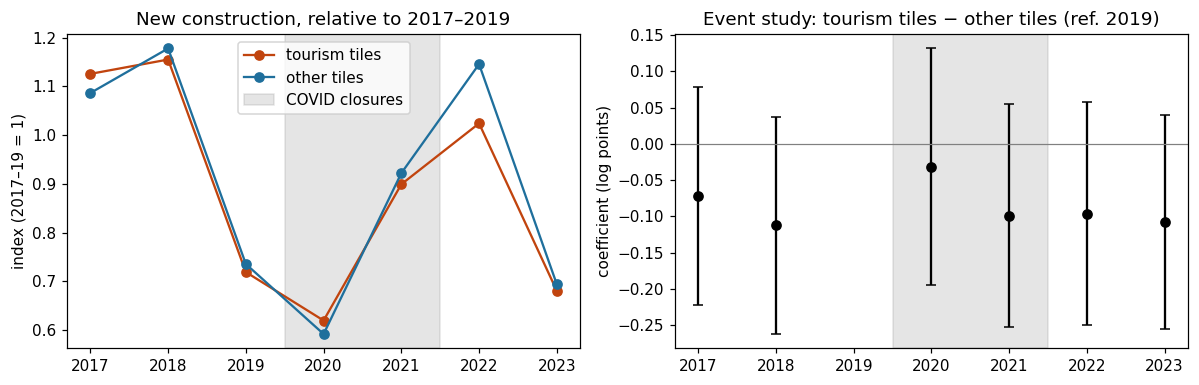

Interpretation: a negative near_x_shock and positive near_x_post support a tourism-demand effect; pre-2020 event-study coefficients near 0 support the parallel-trends assumption. 2022 is re-run without that year because of the known Open Buildings 2022 artefact.

✅ Stage 96 finished in 0.4 min. Saved: []
   Results are on Google Drive. You can now disconnect; the next stage can run in a new session.


In [ ]:
# ======================= CELL 2C: RQ3 – did construction near attractions react to the COVID-19 tourism shock? =======================
# Difference-in-differences / event study on 1 km tiles, 2017–2023 (Open Buildings first-year layer).
# Tourist spots closed 18–19 Mar 2020 → reopened ~Aug 2020; closed 1 Apr 2021 → reopened 19 Aug 2021.
from google.colab import drive
drive.mount('/content/drive')
import os
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())
REV = OUT + '/revision'; os.makedirs(REV, exist_ok=True)
import statsmodels.api as sm
begin_stage(96, needs=['GRID', 'H', 'W', 'RES', 'study', 'zone', 'cluster', 'static'])

NEAR_KM = 2.0                                        # "tourism tile" = tile centre within 2 km of an attraction or tourist route
YEARS = list(range(2017, 2024))
T = int(round(1000 / RES)); hh, ww = (H // T) * T, (W // T) * T
tile = lambda a: a[:hh, :ww].reshape(H // T, T, W // T, T)
new_y = {y: new_fraction(y, y) for y in YEARS}       # share of each 30 m pixel first built in year y
st_t = tile(study.astype('float32')).mean(axis=(1, 3)) > 0.5
dT = np.minimum(static['dist_attraction'], static['dist_tourism_route'])
dT_t = np.nanmean(tile(np.where(study, dT, np.nan)), axis=(1, 3))
cl_t = np.round(np.nanmean(tile(np.where(study, cluster, np.nan).astype('float32')), axis=(1, 3)))
rows = []
for y in YEARS:
    a = tile(np.where(study, new_y[y], 0)).sum(axis=(1, 3)) * RES * RES      # m² new per tile
    for (r, c) in zip(*np.where(st_t)):
        rows.append(dict(tile=r * 10000 + c, year=y, new_m2=a[r, c], near=int(dT_t[r, c] <= NEAR_KM * 1000), cluster=int(cl_t[r, c])))
d = pd.DataFrame(rows)
d['y'] = np.log1p(d.new_m2)
d['shock'] = d.year.isin([2020, 2021]).astype(int); d['post'] = d.year.isin([2022, 2023]).astype(int)
print(f'{d.tile.nunique()} tiles ({d[d.year == 2017].near.sum()} near attractions/routes)')

def twfe(df, terms):
    # two-way fixed effects (tile + year) by double demeaning; SE clustered by tile
    z = df.copy()
    for c in ['y'] + terms:
        z[c] = z[c] - z.groupby('tile')[c].transform('mean') - z.groupby('year')[c].transform('mean') + z[c].mean()
    r = sm.OLS(z['y'], z[terms]).fit(cov_type='cluster', cov_kwds={'groups': z['tile']})
    return pd.DataFrame(dict(coef=r.params, se=r.bse, ci_lo=r.conf_int()[0], ci_hi=r.conf_int()[1], p=r.pvalues))

d['near_x_shock'] = d.near * d.shock; d['near_x_post'] = d.near * d.post
res = {}
for nm, sub_ in [('All', d), ('North', d[d.cluster == 1]), ('South', d[d.cluster == 2]), ('All, without 2022', d[d.year != 2022])]:
    res[nm] = twfe(sub_, ['near_x_shock', 'near_x_post'])
    res[nm]['sample'] = nm
did = pd.concat(res.values()).reset_index().rename(columns={'index': 'term'})
did['pct_effect'] = 100 * (np.exp(did.coef) - 1)
did.to_csv(REV + '/R2C_RQ3_covid_did.csv', index=False)
print('\nDifference-in-differences (log new m² per tile; reference = 2017–2019; % = approx. relative change for tourism tiles):')
print(did[['sample', 'term', 'coef', 'ci_lo', 'ci_hi', 'p', 'pct_effect']].round(3).to_string(index=False))

# event study: near × year (reference 2019)
for y in YEARS:
    d[f'near_{y}'] = d.near * (d.year == y)
ev = twfe(d, [f'near_{y}' for y in YEARS if y != 2019]).reset_index().rename(columns={'index': 'term'})
ev['year'] = ev.term.str[-4:].astype(int); ev.to_csv(REV + '/R2C_RQ3_event_study.csv', index=False)
mean_by = d.groupby(['year', 'near']).new_m2.mean().unstack().reindex(columns=[0, 1]) / 1e4      # hectares per tile
mean_by.columns = ['other tiles', 'tourism tiles']; mean_by.to_csv(REV + '/R2C_RQ3_annual_means.csv')
print('\nMean new building area per 1 km tile (ha):'); print(mean_by.round(3))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for c_, cl in [('tourism tiles', '#c1440e'), ('other tiles', '#1f6f9c')]:
    axs[0].plot(mean_by.index, mean_by[c_] / mean_by[c_].loc[2017:2019].mean(), 'o-', color=cl, label=c_)
axs[0].axvspan(2019.5, 2021.5, color='grey', alpha=0.2, label='COVID closures'); axs[0].set_ylabel('index (2017–19 = 1)'); axs[0].legend(); axs[0].set_title('New construction, relative to 2017–2019')
axs[1].errorbar(ev.year, ev.coef, yerr=[ev.coef - ev.ci_lo, ev.ci_hi - ev.coef], fmt='o', color='black', capsize=3)
axs[1].axhline(0, color='grey', lw=0.8); axs[1].axvspan(2019.5, 2021.5, color='grey', alpha=0.2)
axs[1].set_title('Event study: tourism tiles − other tiles (ref. 2019)'); axs[1].set_ylabel('coefficient (log points)')
fig.tight_layout(); fig.savefig(REV + '/R2C_RQ3_covid.png', dpi=300); plt.show()
print('Interpretation: a negative near_x_shock and positive near_x_post support a tourism-demand effect; pre-2020 event-study '
      'coefficients near 0 support the parallel-trends assumption. 2022 is re-run without that year because of the known '
      'Open Buildings 2022 artefact.')
RESULTS['RQ3_covid'] = dict(near_km=NEAR_KM, did=did.round(4).to_dict('records'), event_study=ev.round(4).to_dict('records'))
end_stage(96, exports=[])

## B5 – Hazard exposure (RQ4)
### Cell 2D – Hazard layers (Earth Engine)
Reads MERIT Hydro HAND and the June 2022 Sentinel-1 flood (VV < −18 dB at the flood peak that was not water in January–March 2022) directly onto the 30 m grid, and defines landslide-prone land as slope ≥ 15°. This cell saves `hazard_maps`, which Cells 2D-v2, 2E, M2 and M3 use. Its first-pass flood class (HAND ≤ 5 m) covered 83% of the land and was replaced in Cell 2D-v2. Set `GEE_PROJECT` first. (This cell was run in a separate session, so its printed output is not stored here; its saved layers are used below.)

In [ ]:
# ======================= CELL 2D: RQ4 – is construction near attractions more often on flood- or landslide-prone land? =======================
# Flood-prone: height above nearest drainage (MERIT Hydro HAND) <= 5 m, or flooded in the June 2022 Sylhet flood (Sentinel-1).
# Landslide-prone: slope >= 15 degrees (or NASA LHASA susceptibility 'high'/'very high' if a file LHASA*.tif is on Drive).
from google.colab import drive
drive.mount('/content/drive')
import os
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())
REV = OUT + '/revision'; os.makedirs(REV, exist_ok=True)
import ee, statsmodels.api as sm
GEE_PROJECT = 'YOUR-GEE-PROJECT'        # same as in Cell 1B
try:
    ee.Initialize(project=GEE_PROJECT)
except Exception:
    ee.Authenticate(); ee.Initialize(project=GEE_PROJECT)
begin_stage(97, needs=['GRID', 'H', 'W', 'RES', 'study', 'zone', 'cluster', 'static', 'labA', 'labB', 'eligA', 'eligB', 'built'])

HAND_MAX, SLOPE_MIN, NEAR_KM = 5.0, 15.0, 2.0
tr = GRID['transform']
def pixels(img, band):
    # read an Earth Engine image directly onto the project's 30 m grid (no export needed), in 4 strips
    out = np.zeros((H, W), 'float32'); step = int(np.ceil(H / 4))
    for r0 in range(0, H, step):
        h_ = min(step, H - r0)
        arr = ee.data.computePixels({'expression': img.select([band]).toFloat(), 'fileFormat': 'NUMPY_NDARRAY',
              'grid': {'dimensions': {'width': W, 'height': h_}, 'crsCode': str(GRID['crs']),
                       'affineTransform': {'scaleX': tr.a, 'shearX': 0, 'translateX': tr.c, 'shearY': 0, 'scaleY': tr.e, 'translateY': tr.f + r0 * tr.e}}})
        out[r0:r0 + h_] = arr[band]
    return out

hand = pixels(ee.Image('MERIT/Hydro/v1_0_1').select('hnd'), 'hnd')
s1 = ee.ImageCollection('COPERNICUS/S1_GRD').filter(ee.Filter.eq('instrumentMode', 'IW')).filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')).select('VV')
pre = s1.filterDate('2022-01-01', '2022-03-31').median(); peak = s1.filterDate('2022-06-15', '2022-06-30').min()
flood_img = peak.lt(-18).And(pre.gte(-18)).rename('flood')            # water in June 2022 that was dry in the dry season
flood22 = pixels(flood_img.unmask(0), 'flood') > 0.5
lh = find_all('LHASA*.tif') if exists('LHASA*.tif') else []
if lh:
    lhasa = to_grid(lh[0], method=Resampling.nearest); landslide = lhasa >= 4; ls_src = 'NASA LHASA (high/very high)'
else:
    landslide = static['slope'] >= SLOPE_MIN; ls_src = f'slope >= {SLOPE_MIN} degrees (proxy)'
flood_prone = ((hand <= HAND_MAX) | flood22) & study & (static['water_occurrence'] < WATER_MAX)
haz = {'flood-prone': flood_prone, 'landslide-prone': landslide & study, 'any hazard': (flood_prone | landslide) & study}
print({k: f'{v.sum() * RES * RES / 1e6:.1f} km² ({100 * v.sum() / study.sum():.1f} %)' for k, v in haz.items()}, '| landslide source:', ls_src)

dT = np.minimum(static['dist_attraction'], static['dist_tourism_route']); near = (dT <= NEAR_KM * 1000) & study
new = (labA | labB) & study
BLK = int(CV_BLOCK_M / RES); ri, ci = np.indices((H, W)); block = (ri // BLK) * 100000 + (ci // BLK)
rows = []
for hname, hm in haz.items():
    for cname, cm in [('All', study), ('North', cluster == 1), ('South', cluster == 2)]:
        for grp, gm in [('near attractions/routes', near), ('elsewhere', study & ~near)]:
            m = new & cm & gm
            rows.append(dict(hazard=hname, cluster=cname, group=grp, new_km2=m.sum() * RES * RES / 1e6,
                             share_on_hazard_pct=100 * (m & hm).sum() / max(m.sum(), 1),
                             hazard_share_of_eligible_land_pct=100 * (hm & cm & gm & (eligA | eligB)).sum() / max((cm & gm & (eligA | eligB)).sum(), 1)))
desc = pd.DataFrame(rows); desc.to_csv(REV + '/R2D_RQ4_hazard_shares.csv', index=False)
print('\nShare of new construction (2017–2023) on hazard-prone land:'); print(desc.round(2).to_string(index=False))

# odds ratio: is new construction NEAR attractions more likely to be on hazard land than new construction elsewhere? (block-clustered logit)
r_, c_ = np.where(new)
dfh = pd.DataFrame(dict(near=near[r_, c_].astype(int), south=(cluster[r_, c_] == 2).astype(int), blk=block[r_, c_],
                        bcover=np.log1p(np.nan_to_num(built[2016][r_, c_])), droad=np.log1p(static['dist_any_road'][r_, c_]),
                        elev=static['elevation'][r_, c_]))
orr = []
for hname, hm in haz.items():
    dfh['h'] = hm[r_, c_].astype(int)
    for cname, s_ in [('All', dfh), ('North', dfh[dfh.south == 0]), ('South', dfh[dfh.south == 1])]:
        if s_.h.nunique() < 2 or s_.near.nunique() < 2: continue
        for tag, cols in [('unadjusted', ['near']), ('adjusted', ['near', 'bcover', 'droad'] + (['elev'] if hname == 'flood-prone' else []))]:
            X = sm.add_constant((s_[cols] - s_[cols].mean()) / s_[cols].std().replace(0, 1) if tag == 'adjusted' else s_[cols])
            X['near'] = s_['near']
            r = sm.GLM(s_.h, X, family=sm.families.Binomial()).fit(cov_type='cluster', cov_kwds={'groups': s_.blk})
            ci = r.conf_int().loc['near']
            orr.append(dict(hazard=hname, cluster=cname, model=tag, odds_ratio_near=np.exp(r.params['near']), ci_lo=np.exp(ci[0]), ci_hi=np.exp(ci[1]), p=r.pvalues['near']))
orr = pd.DataFrame(orr); orr.to_csv(REV + '/R2D_RQ4_hazard_odds_ratios.csv', index=False)
print('\nOdds that new construction lies on hazard-prone land: near attractions/routes vs elsewhere (>1 = more exposed):'); print(orr.round(3).to_string(index=False))

hazard_maps = dict(flood_prone=flood_prone, landslide_prone=landslide & study, hand=hand, flood2022=flood22, landslide_source=ls_src)
RESULTS['RQ4_hazard'] = dict(settings=dict(HAND_MAX=HAND_MAX, SLOPE_MIN=SLOPE_MIN, NEAR_KM=NEAR_KM, landslide_source=ls_src),
                             hazard_area_km2={k: float(v.sum() * RES * RES / 1e6) for k, v in haz.items()},
                             shares=desc.round(3).to_dict('records'), odds_ratios=orr.round(4).to_dict('records'))
end_stage(97, exports=['hazard_maps'])

Mounted at /content/drive
Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 13.6 GB | CPUs: 2
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 530 files in Drive
Stage 97: loaded 13 saved results from earlier stages.
{'flood-prone': '1212.9 km² (83.4 %)', 'landslide-prone': '36.1 km² (2.5 %)', 'any hazard': '1241.8 km² (85.3 %)'} | landslide source: slope >= 15.0 degrees (proxy)

Share of new construction (2017–2023) on hazard-prone land:
         hazard cluster                   group  new_km2  share_on_hazard_pct  hazard_share_of_eligible_land_pct
    flood-prone     All near attractions/routes     5.85                81.28                              86.96
    flood-prone     All               elsewhere     7.85                80.22                              85.55
    flood-prone   North near attractions/routes     4.38                82.93                              88.83
    flood-prone   North               elsewhere     4.52                87.13   

### Cell 2D-v2 – Hazard odds ratios with the observed 2022 flood as the main flood class
Odds that new construction (2017–2023) lies on hazard-prone land, tourism-proximate (≤ 2 km of an attraction or route) versus elsewhere, adjusted for initial building cover, distance to roads and elevation, with 3 km block-clustered errors.

**In the paper:** Section 5.5; Table 7; Supplementary Table S10.

In [ ]:
# ======================= CELL 2D-v2: stricter flood definition (no Earth Engine needed; uses the layers saved by 2D) =======================
from google.colab import drive
drive.mount('/content/drive')
import os
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())
REV = OUT + '/revision'; os.makedirs(REV, exist_ok=True)
import statsmodels.api as sm
begin_stage(99, needs=['H', 'W', 'RES', 'study', 'cluster', 'static', 'labA', 'labB', 'eligA', 'eligB', 'built', 'hazard_maps'])

NEAR_KM = 2.0
hand, flood22 = hazard_maps['hand'], hazard_maps['flood2022']
okland = study & (static['water_occurrence'] < WATER_MAX)
DEFS = {'flooded June 2022 (Sentinel-1, observed)': flood22 & okland,
        'HAND <= 2 m': (hand <= 2) & okland,
        'HAND <= 5 m (old rule)': (hand <= 5) & okland,
        'landslide-prone (slope >= 15°)': hazard_maps['landslide_prone'] & study}
print('Area of each hazard class:')
for k, m in DEFS.items():
    print(f'  {k:42s} {m.sum() * RES * RES / 1e6:8.1f} km²  ({100 * m.sum() / study.sum():5.1f} % of study area)')

dT = np.minimum(static['dist_attraction'], static['dist_tourism_route']); near = (dT <= NEAR_KM * 1000) & study
new = (labA | labB) & study; eligAB = eligA | eligB
BLK = int(CV_BLOCK_M / RES); ri, ci = np.indices((H, W)); block = (ri // BLK) * 100000 + (ci // BLK)
r_, c_ = np.where(new)
dfh = pd.DataFrame(dict(near=near[r_, c_].astype(int), south=(cluster[r_, c_] == 2).astype(int), blk=block[r_, c_],
                        bcover=np.log1p(np.nan_to_num(built[2016][r_, c_])), droad=np.log1p(static['dist_any_road'][r_, c_]),
                        elev=static['elevation'][r_, c_]))
rows, orr = [], []
for hname, hm in DEFS.items():
    for cname, cm in [('All', study), ('North', cluster == 1), ('South', cluster == 2)]:
        for grp, gm in [('near', near), ('elsewhere', study & ~near)]:
            m = new & cm & gm
            rows.append(dict(hazard=hname, cluster=cname, group=grp, new_km2=m.sum() * RES * RES / 1e6,
                             share_of_new_on_hazard_pct=100 * (m & hm).sum() / max(m.sum(), 1),
                             share_of_buildable_land_hazard_pct=100 * (hm & cm & gm & eligAB).sum() / max((cm & gm & eligAB).sum(), 1)))
    dfh['h'] = hm[r_, c_].astype(int)
    for cname, s_ in [('All', dfh), ('North', dfh[dfh.south == 0]), ('South', dfh[dfh.south == 1])]:
        if s_.h.sum() < 10 or (s_.h == 0).sum() < 10 or s_.near.nunique() < 2:
            orr.append(dict(hazard=hname, cluster=cname, model='too few cases', odds_ratio_near=np.nan, ci_lo=np.nan, ci_hi=np.nan, p=np.nan)); continue
        cols = ['near', 'bcover', 'droad'] + (['elev'] if 'landslide' not in hname else [])
        X = sm.add_constant((s_[cols] - s_[cols].mean()) / s_[cols].std().replace(0, 1)); X['near'] = s_['near']
        r = sm.GLM(s_.h, X, family=sm.families.Binomial()).fit(cov_type='cluster', cov_kwds={'groups': s_.blk})
        ci = r.conf_int().loc['near']
        orr.append(dict(hazard=hname, cluster=cname, model='adjusted', odds_ratio_near=np.exp(r.params['near']), ci_lo=np.exp(ci[0]), ci_hi=np.exp(ci[1]), p=r.pvalues['near']))
desc, orr = pd.DataFrame(rows), pd.DataFrame(orr)
desc.to_csv(REV + '/R2D2_hazard_shares.csv', index=False); orr.to_csv(REV + '/R2D2_hazard_odds_ratios.csv', index=False)
print('\nShare of new construction 2017–2023 on hazard land (near attractions/routes vs elsewhere):')
print(desc.pivot_table(index=['hazard', 'cluster'], columns='group', values='share_of_new_on_hazard_pct').round(2))
print('\nAdjusted odds that new construction near attractions/routes lies on hazard land (>1 = more exposed):')
print(orr.round(3).to_string(index=False))

# main flood class for RQ4/RQ5 = observed 2022 flood extent (Cell 2E uses it automatically)
hazard_maps['flood_prone'] = DEFS['flooded June 2022 (Sentinel-1, observed)']
hazard_maps['flood_definition'] = 'flooded in June 2022 (Sentinel-1 VV < -18 dB, dry in Jan–Mar 2022), excluding permanent water'
RESULTS['RQ4_hazard_v2'] = dict(area_km2={k: float(m.sum() * RES * RES / 1e6) for k, m in DEFS.items()},
                                shares=desc.round(3).to_dict('records'), odds_ratios=orr.round(4).to_dict('records'),
                                main_flood_definition=hazard_maps['flood_definition'])
end_stage(99, exports=['hazard_maps'])
print('\nNow run Cell 2E again: it will use the observed 2022 flood extent.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 13.6 GB | CPUs: 2
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 530 files in Drive
Stage 99: loaded 12 saved results from earlier stages.
Area of each hazard class:
  flooded June 2022 (Sentinel-1, observed)      689.4 km²  ( 47.4 % of study area)
  HAND <= 2 m                                   974.4 km²  ( 67.0 % of study area)
  HAND <= 5 m (old rule)                       1210.3 km²  ( 83.2 % of study area)
  landslide-prone (slope >= 15°)                 36.1 km²  (  2.5 % of study area)

Share of new construction 2017–2023 on hazard land (near attractions/routes vs elsewhere):
group                                             elsewhere   near
hazard                                   cluster                  
HAND <= 2 m                              All          42.97  42.43
   

## B6 – Scenarios and hazard (RQ5)
### Cell 2E – Hazard-zone construction to 2035, avoided exposure and precision correction
Share of projected construction on 2022-flooded land, steep slopes or within a 50 m river setback; reallocation of the same total away from these zones; scenario totals multiplied by label precision.

**In the paper:** Section 5.6; Table 8.

In [ ]:
# ======================= CELL 2E: RQ5 – hazard-zone construction to 2035, avoided exposure, and label-precision correction =======================
from google.colab import drive
drive.mount('/content/drive')
import os
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())
REV = OUT + '/revision'; os.makedirs(REV, exist_ok=True)
begin_stage(98, needs=['H', 'W', 'RES', 'study', 'zone', 'cluster', 'static', 'scen_out', 'px_km2', 'hazard_maps', 'upz_id', 'UPZ_NAMES'])

SETBACK_M = 50                       # river setback assumed for the "avoid hazard" variant (state the legal basis in the paper)
# label precision from the manual check (Cell 1C): 37 of 60 checked positives were real new buildings
lv = RESULTS.get('label_validation', {})
P_HAT = lv.get('precision_current_labels', 0.622)
k_pos, n_pos = 37, 60
z = 1.96; ph = k_pos / n_pos; den = 1 + z * z / n_pos; cen = (ph + z * z / (2 * n_pos)) / den
half = z * np.sqrt(ph * (1 - ph) / n_pos + z * z / (4 * n_pos * n_pos)) / den
P_LO, P_HI = cen - half, cen + half
print(f'Label precision used for correction: {P_HAT:.3f} (Wilson 95 % CI {P_LO:.3f}–{P_HI:.3f})')

setback = (static['dist_river'] <= SETBACK_M) & study
avoid = hazard_maps['flood_prone'] | hazard_maps['landslide_prone'] | setback
rows = []
for s, o in scen_out.items():
    p = np.nan_to_num(o['p2035']) * study
    total = p.sum() * px_km2
    on_h = {k: (p * m).sum() * px_km2 for k, m in [('flood', hazard_maps['flood_prone']), ('landslide', hazard_maps['landslide_prone']),
                                                  ('river setback', setback), ('any avoid zone', avoid)]}
    # avoided-exposure variant: the same total, re-allocated to non-hazard pixels in proportion to their probability
    q = p * (~avoid); q = q * (p.sum() / max(q.sum(), 1e-9))
    over = np.clip(q - 1, 0, None).sum(); q = np.clip(q, 0, 1); q = q * (1 + over / max(q.sum(), 1e-9))   # keep total after capping
    rows.append(dict(scenario=s, total_new_km2=total,
                     corrected_total_km2=total * P_HAT, corrected_lo=total * P_LO, corrected_hi=total * P_HI,
                     flood_km2=on_h['flood'], landslide_km2=on_h['landslide'], setback_km2=on_h['river setback'], any_hazard_km2=on_h['any avoid zone'],
                     any_hazard_pct=100 * on_h['any avoid zone'] / max(total, 1e-9),
                     avoided_exposure_km2=on_h['any avoid zone'] - (q * avoid).sum() * px_km2,
                     zone_share_bau_pct=100 * (p * zone).sum() / max(p.sum(), 1e-9), zone_share_avoid_pct=100 * (q * zone).sum() / max(q.sum(), 1e-9)))
tab = pd.DataFrame(rows); tab.to_csv(REV + '/R2E_RQ5_hazard_and_avoided_exposure.csv', index=False)
print('\nExpected new construction to 2035 (km²), hazard-zone share and exposure avoided by keeping new building out of hazard zones:')
print(tab.round(2).to_string(index=False))

pM = np.nan_to_num(scen_out['Medium']['p2035']) * study
up = []
for i, nm in UPZ_NAMES.items():
    m = upz_id == i
    up.append(dict(upazila=nm, medium_new_km2=(pM * m).sum() * px_km2, medium_new_corrected_km2=(pM * m).sum() * px_km2 * P_HAT,
                   medium_on_hazard_km2=(pM * m * avoid).sum() * px_km2,
                   hazard_share_pct=100 * (pM * m * avoid).sum() / max((pM * m).sum(), 1e-9)))
up = pd.DataFrame(up); up.to_csv(REV + '/R2E_RQ5_by_upazila.csv', index=False)
print('\nMedium scenario by upazila:'); print(up.round(2).to_string(index=False))
RESULTS['RQ5_hazard_scenarios'] = dict(setback_m=SETBACK_M, precision=[P_HAT, P_LO, P_HI], scenarios=tab.round(4).to_dict('records'),
                                       by_upazila=up.round(4).to_dict('records'))
end_stage(98, exports=[])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 56.9 GB | CPUs: 12
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 372 files in Drive
Stage 98: loaded 12 saved results from earlier stages.
Label precision used for correction: 0.622 (Wilson 95 % CI 0.490–0.729)

Expected new construction to 2035 (km²), hazard-zone share and exposure avoided by keeping new building out of hazard zones:
scenario  total_new_km2  corrected_total_km2  corrected_lo  corrected_hi  flood_km2  landslide_km2  setback_km2  any_hazard_km2  any_hazard_pct  avoided_exposure_km2  zone_share_bau_pct  zone_share_avoid_pct
     Low      19.950001            12.410000          9.78         14.54       1.10           0.13         0.91            2.08           10.43                  2.08               17.68                 17.74
  Medium      23.760000            14.78

## B7 – Robustness checks
### Cell M2 – Sensitivity of the flood result to the flood definition (Earth Engine)
Repeats the RQ4 test with fixed thresholds from −15 to −20 dB, an Otsu threshold computed from the June 2022 image and a change-detection rule. (The column `agree_with_main_pct` compares with the stored map, which also covers the 2 km processing buffer, so it is not interpretable and is not reported.) Set `GEE_PROJECT` first.

**In the paper:** Sections 4.7 and 5.5; Supplementary Table S11.

In [ ]:
# ======================= CELL M2: flood-threshold sensitivity =======================
from google.colab import drive
drive.mount('/content/drive')
import os
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())
REV = OUT + '/revision'; os.makedirs(REV, exist_ok=True)
import ee, statsmodels.api as sm
GEE_PROJECT = 'YOUR-GEE-PROJECT'
try:
    ee.Initialize(project=GEE_PROJECT)
except Exception:
    ee.Authenticate(); ee.Initialize(project=GEE_PROJECT)
begin_stage(101, needs=['GRID', 'H', 'W', 'RES', 'study', 'cluster', 'static', 'labA', 'labB', 'built', 'hazard_maps'])

tr = GRID['transform']
def pixels(img, band):
    out = np.zeros((H, W), 'float32'); step = int(np.ceil(H / 4))
    for r0 in range(0, H, step):
        h_ = min(step, H - r0)
        arr = ee.data.computePixels({'expression': img.select([band]).toFloat(), 'fileFormat': 'NUMPY_NDARRAY',
              'grid': {'dimensions': {'width': W, 'height': h_}, 'crsCode': str(GRID['crs']),
                       'affineTransform': {'scaleX': tr.a, 'shearX': 0, 'translateX': tr.c, 'shearY': 0, 'scaleY': tr.e,
                                           'translateY': tr.f + r0 * tr.e}}})
        out[r0:r0 + h_] = arr[band]
    return out

s1 = (ee.ImageCollection('COPERNICUS/S1_GRD').filter(ee.Filter.eq('instrumentMode', 'IW'))
      .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')).select('VV'))
pre  = pixels(s1.filterDate('2022-01-01', '2022-03-31').median().unmask(0), 'VV')    # dry season
peak = pixels(s1.filterDate('2022-06-15', '2022-06-30').min().unmask(0), 'VV')       # flood peak
okland = study & (static['water_occurrence'] < WATER_MAX)

# Otsu threshold on the flood-peak backscatter inside the study area
v = peak[study & (peak < 0)]; hist, edges = np.histogram(v, bins=256); mids = (edges[:-1] + edges[1:]) / 2
w0 = np.cumsum(hist); w1 = w0[-1] - w0; m0 = np.cumsum(hist * mids) / np.maximum(w0, 1)
m1 = (np.sum(hist * mids) - np.cumsum(hist * mids)) / np.maximum(w1, 1)
OTSU = float(mids[np.argmax(w0 * w1 * (m0 - m1) ** 2)])
print(f'Otsu threshold on June 2022 VV: {OTSU:.1f} dB')

DEFS = {f'VV < {t} dB': (peak < t) & (pre >= t) & okland for t in [-15, -16, -17, -18, -19, -20]}
DEFS[f'Otsu ({OTSU:.1f} dB)'] = (peak < OTSU) & (pre >= OTSU) & okland
DEFS['change: peak - dry <= -3 dB and peak < -15 dB'] = ((peak - pre) <= -3) & (peak < -15) & okland

dT = np.minimum(static['dist_attraction'], static['dist_tourism_route']); near = (dT <= 2000) & study
new = (labA | labB) & study
BLK = int(CV_BLOCK_M / RES); ri, ci = np.indices((H, W)); block = (ri // BLK) * 100000 + (ci // BLK)
r_, c_ = np.where(new)
dfh = pd.DataFrame(dict(near=near[r_, c_].astype(int), south=(cluster[r_, c_] == 2).astype(int), blk=block[r_, c_],
                        bcover=np.log1p(np.nan_to_num(built[2016][r_, c_])), droad=np.log1p(static['dist_any_road'][r_, c_]),
                        elev=static['elevation'][r_, c_]))
rows = []
for name, fm in DEFS.items():
    dfh['h'] = fm[r_, c_].astype(int)
    row = dict(definition=name, area_km2=fm.sum() * RES * RES / 1e6, area_pct=100 * fm.sum() / study.sum(),
               agree_with_main_pct=100 * (fm & hazard_maps['flood2022']).sum() / max((fm | hazard_maps['flood2022']).sum(), 1),
               share_near_pct=100 * dfh.h[dfh.near == 1].mean(), share_else_pct=100 * dfh.h[dfh.near == 0].mean())
    for cname, s_ in [('All', dfh), ('North', dfh[dfh.south == 0])]:
        if s_.h.sum() < 10:
            row[f'OR_{cname}'] = np.nan; continue
        cols = ['near', 'bcover', 'droad', 'elev']
        X = sm.add_constant((s_[cols] - s_[cols].mean()) / s_[cols].std().replace(0, 1)); X['near'] = s_['near']
        r = sm.GLM(s_.h, X, family=sm.families.Binomial()).fit(cov_type='cluster', cov_kwds={'groups': s_.blk})
        ci_ = np.exp(r.conf_int().loc['near'])
        row[f'OR_{cname}'] = f"{np.exp(r.params['near']):.2f} ({ci_[0]:.2f}–{ci_[1]:.2f}), p={r.pvalues['near']:.3f}"
    rows.append(row)
tab = pd.DataFrame(rows); tab.to_csv(REV + '/M2_flood_threshold_sensitivity.csv', index=False)
pd.set_option('display.width', 250); pd.set_option('display.max_colwidth', 60)
print(tab.round(2).to_string(index=False))
RESULTS['M2_flood_threshold'] = dict(otsu=OTSU, table=tab.round(3).to_dict('records'))
end_stage(101, exports=[])

Mounted at /content/drive
Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 13.6 GB | CPUs: 2
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 531 files in Drive
Stage 101: loaded 11 saved results from earlier stages.
Otsu threshold on June 2022 VV: -17.0 dB
                                   definition  area_km2  area_pct  agree_with_main_pct  share_near_pct  share_else_pct                      OR_All                   OR_North
                                  VV < -15 dB    749.37     51.50                23.87            0.62            0.56   1.61 (0.61–4.23), p=0.333  2.28 (1.08–4.79), p=0.030
                                  VV < -16 dB    730.96     50.23                24.33            0.45            0.39   1.97 (0.81–4.81), p=0.137  2.23 (0.81–6.13), p=0.119
                                  VV < -17 dB    710.81     48.85                24.66            0.34            0.25   2.35 (0.80–6.91), p=0.121  2.59 (0.75–8.96), p=0.133
                    

### Cell M3 – Projection with 2023 roads and allocation sensitivity
Trains a five-member XGBoost ensemble with time-matched roads (no look-ahead), projects the Medium scenario from the 2023 network with allocation proportional to p² (as in the paper) and to p, and compares totals, tourism-zone share, hazard share and pixel-level agreement with the main run. Use a High-RAM runtime (about 45 min).

**In the paper:** Sections 4.8 and 5.6; Supplementary Table S13.

In [ ]:
# ======================= CELL M3: projection rerun with 2023 roads (no look-ahead) + allocation sensitivity =======================
from google.colab import drive
drive.mount('/content/drive')
import os, time
exec(open('/content/drive/MyDrive/Sylhet_outputs/sylhet_setup.py').read())
REV = OUT + '/revision'; os.makedirs(REV, exist_ok=True)
from scipy.stats import spearmanr
begin_stage(102, needs=['GRID', 'H', 'W', 'RES', 'study', 'zone', 'cluster', 'static', 'built', 'eligA', 'eligB',
                        'labA', 'labB', 'XGB_PARAMS', 'osm_hist', 'FEAT_v2', 'scen_out', 'hazard_maps'])
N_RUNS, N_ENS = 100, 5
px_km2 = RES * RES / 1e6

# 1) train a 5-member XGBoost ensemble on Periods A+B with time-matched roads/facilities (2016 for A, 2020 for B)
def build(start, osm_year, b):
    f = dict(static); f.update(dynamic(start)); f.update(neighbourhood(b)); f.update(osm_hist[osm_year]); return f
fA = build(PERIOD_A['start'], 2016, built[PERIOD_A['start']]); fB = build(PERIOD_B['start'], 2020, built[PERIOD_B['start']])
FEAT = list(FEAT_v2)
M = lambda f, idx: np.column_stack([f[c][idx] for c in FEAT]).astype('float32')
def sample(lab, elig):
    pos, neg = np.where(lab), np.where(elig & ~lab)
    k = rng.choice(len(neg[0]), min(len(neg[0]), NEG_PER_POS * len(pos[0])), replace=False)
    return (np.r_[pos[0], neg[0][k]], np.r_[pos[1], neg[1][k]])
iA, iB = sample(labA, eligA), sample(labB, eligB)
XA, XB = M(fA, iA), M(fB, iB)
imp = SimpleImputer(strategy='median').fit(np.vstack([XA, XB]))
X_all = imp.transform(np.vstack([XA, XB])); y_all = np.r_[labA[iA], labB[iB]].astype(int)
spw = (y_all == 0).sum() / max((y_all == 1).sum(), 1)
ens = []
for k in range(N_ENS):
    bs = rng.choice(len(y_all), len(y_all), replace=True)
    ens.append(xgb.XGBClassifier(subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw, tree_method='hist',
                                 eval_metric='aucpr', n_jobs=-1, random_state=SEED + k, **XGB_PARAMS).fit(X_all[bs], y_all[bs]))
print('ensemble trained (time-matched roads)')

# 2) Monte Carlo from 2023 with 2023 roads/facilities, Medium quantity, allocation p^2 (as in paper) and p
yrsA = PERIOD_A['new_to'] - PERIOD_A['new_from'] + 1; yrsB = PERIOD_B['new_to'] - PERIOD_B['new_from'] + 1
RATE_PX = (labA.sum() + labB.sum()) / (yrsA + yrsB); RATE_CV = RESULTS['annual_new_km2_cv']
base = dict(static); base.update(dynamic(PROJ_START)); base.update(osm_hist[2023])
b0 = built[PROJ_START].copy(); elig0 = study & (b0 < BUILT_START_MAX) & (static['water_occurrence'] < WATER_MAX)
YEARS = list(range(PROJ_START + 1, PROJ_END + 1))
def run(power):
    model = ens[rng.integers(N_ENS)]; b = b0.copy(); elig = elig0.copy(); conv = np.zeros((H, W), bool); tot = 0
    for i, yr in enumerate(YEARS):
        if i % UPDATE_EVERY == 0:
            f = dict(base); f.update(neighbourhood(b)); r, c = np.where(elig)
            p = np.concatenate([model.predict_proba(imp.transform(M(f, (r[s:s+500_000], c[s:s+500_000]))))[:, 1]
                                for s in range(0, len(r), 500_000)])
            alive = np.ones(len(r), bool)
        n = int(max(0, rng.normal(RATE_PX, RATE_PX * RATE_CV))); cand = np.where(alive)[0]; n = min(n, len(cand))
        if n > 0:
            keys = power * np.log(np.clip(p[cand], 1e-9, 1)) + rng.gumbel(size=len(cand))
            ch = cand[np.argpartition(-keys, n - 1)[:n]]
            alive[ch] = False; conv[r[ch], c[ch]] = True; b[r[ch], c[ch]] = 100.0; elig[r[ch], c[ch]] = False; tot += n
    return conv, tot
res = {}
for tag, pw in [('roads2023_p2', 2.0), ('roads2023_p1', 1.0)]:
    t0 = time.time(); acc = np.zeros((H, W), 'float32'); tots = []
    for k in range(N_RUNS):
        cv, t = run(pw); acc += cv; tots.append(t * px_km2)
        if (k + 1) % 10 == 0: print(f'  {tag}: {k + 1}/{N_RUNS} runs, {time.time() - t0:.0f} s')
    res[tag] = dict(p2035=acc / N_RUNS, tot=np.array(tots))
    save_tif(res[tag]['p2035'], f'M3_prob_2035_Medium_{tag}.tif')
res['original_2026roads_p2'] = dict(p2035=scen_out['Medium']['p2035'], tot=scen_out['Medium']['cum'][:, -1] * px_km2)

# 3) compare with the original Medium map
setback = (static['dist_river'] <= 50) & study
avoid = hazard_maps['flood2022'] | hazard_maps['landslide_prone'] | setback
ref = res['original_2026roads_p2']['p2035']
def top2(p): t = np.quantile(p[study], 0.98); return (p >= t) & study & (p > 0)
UPA = static.get('upazila_id', None)
rows = []
for tag, d in res.items():
    p = d['p2035']; m = study & ((p > 0) | (ref > 0))
    rows.append(dict(run=tag, total_km2=d['tot'].mean(), total_p5=np.percentile(d['tot'], 5), total_p95=np.percentile(d['tot'], 95),
                     corrected_km2=0.622 * d['tot'].mean(),
                     spearman_vs_original=spearmanr(p[m], ref[m]).correlation,
                     watch_overlap_jaccard=(top2(p) & top2(ref)).sum() / max((top2(p) | top2(ref)).sum(), 1),
                     share_tourism_zone_pct=100 * (p * zone).sum() / p.sum(),
                     share_hazard_pct=100 * (p * avoid).sum() / p.sum(),
                     share_north_pct=100 * (p * (cluster == 1)).sum() / p.sum(),
                     max_prob=float(p[study].max())))
tab = pd.DataFrame(rows); tab.to_csv(REV + '/M3_projection_sensitivity.csv', index=False)
pd.set_option('display.width', 250); print(tab.round(3).to_string(index=False))
RESULTS['M3_projection'] = tab.round(4).to_dict('records')
end_stage(102, exports=[])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/Sylhet_outputs
RAM: 56.9 GB | CPUs: 12
Unzipped Sylhet_QGIS.zip -> /content/Sylhet_QGIS_unzipped
Indexed 372 files in Drive
Stage 102: loaded 18 saved results from earlier stages.
ensemble trained (time-matched roads)
  roads2023_p2: 10/100 runs, 136 s
  roads2023_p2: 20/100 runs, 271 s
  roads2023_p2: 30/100 runs, 407 s
  roads2023_p2: 40/100 runs, 542 s
  roads2023_p2: 50/100 runs, 677 s
  roads2023_p2: 60/100 runs, 812 s
  roads2023_p2: 70/100 runs, 948 s
  roads2023_p2: 80/100 runs, 1083 s
  roads2023_p2: 90/100 runs, 1219 s
  roads2023_p2: 100/100 runs, 1355 s
  roads2023_p1: 10/100 runs, 136 s
  roads2023_p1: 20/100 runs, 271 s
  roads2023_p1: 30/100 runs, 407 s
  roads2023_p1: 40/100 runs, 542 s
  roads2023_p1: 50/100 runs, 678 s
  roads2023_p1: 60/100 runs, 813 s
  roads2023_p1: 70/100 runs, 949 s
  roads2023_p1: 

---
## Outputs

* `Sylhet_outputs/` – Part A tables (`RO*.csv`), GeoTIFF maps (for example `RO6_prob_conversion_2035_Medium.tif`), 300 dpi figures and `key_results.json`.
* `Sylhet_outputs/revision/` – Part B tables (`R1*`, `R2*`, `M2_*`, `M3_*`), `manual_check_points.csv`, `manual_answers.csv` and the M3 GeoTIFFs.

All analyses use open data. Please cite the article and the data providers listed in Supplementary Table S1 when reusing this code.